# From Forecasts to Policies: Inventory Planning with Lead Times

In the first post, ["From Forecasts to Decisions: Inventory Planning with Probabilistic Programming"](https://juanitorduz.github.io/forecast_to_decision/), we sold one product and decided today how many units to order for each of the next $15$ days. We turned the posterior predictive draws of a demand model into demand scenarios and ran an inventory simulator on them. Then we chose the orders that minimize a loss with two unit costs: a holding cost per unit left over and a lost margin per unit of demand that we cannot serve.

That problem had three simplifications, and the first post lists them among its limitations. Every order arrived on the day we planned it for, all $15$ orders were fixed on day one, and the forecast of day one was never updated. In practice a delivery takes time, we place an order every day after we see what is left on the shelf, and we run the forecast again when new demand comes in. In the VN2 challenge described by [Szabłowski (2026)](https://arxiv.org/abs/2601.18919), which motivated the first post, a delivery takes two weeks and the decisions follow a weekly cycle.

In this notebook we remove the three simplifications.

- **Lead time.** An order placed on day $t$ arrives at the start of day $t + L$, where $L$ is the *lead time*.
- **Policies.** The order of each day is a function of what we have observed up to that day. We call such a function a *policy*, and we call a vector of orders fixed in advance a *plan*.
- **Weekly forecast.** We run the forecast again after the first week. On day $8$ we update it with the demand of days $1$ to $7$, as a retailer that runs its forecast every week would do. A second update on day $15$ would only change the last order, so we leave it out for simplicity.

We compare five ways of placing the orders. The first one is the plan of the first post, which is our baseline. The other four look at the stock every day, and all of them except the first base-stock policy use the weekly forecast:

- **Fixed plan.** This is the expected cost plan of the first post, now with a lead time. It uses the forecast of day one and nothing that happens after day one.
- **Base-stock (day-one forecast).** On every day it orders the difference between a target level and the stock that is on the shelf or on its way. The target level of a day is a quantile of the demand that the order has to cover, under the forecast of day one.
- **Base-stock (weekly forecast).** The same rule with the target levels of the weekly forecast, so from day $8$ on the levels use the demand of the first week.
- **Base-stock (trained).** The target levels of the weekly forecast plus an offset for every day, which we train.
- **Neural.** A small neural network adds a correction to the target level of the trained base-stock policy.

All five place their orders with the same lead time $L$. The fixed plan accounts for it in the simulator that we solve it on, which delivers every order $L$ days after we place it. The base-stock and neural policies count the orders on their way as stock, and their target level covers the demand of the $L + 1$ days until the order of the next day arrives.

Why do we need a correction of the target level? The base-stock policy is the standard rule of inventory theory, but it is not optimal when the demand that we cannot serve is lost and the orders take time to arrive. The rule adds the orders on their way to the stock on the shelf, although an order that arrives tomorrow can serve more days than one that arrives in two days.

Also, the weekly forecast does not know the demand of the days since its update. The network sees each order on its way, the forecast and the demand of the last week, so it can learn these effects from the scenarios.

The simulator of the first post is a `jax.lax.scan` over the days, and JAX differentiates through it. So we can train a policy in the same way we solved for the plan: we write the order of each day as `policy(params, observation)` inside the scan and run gradient descent on the parameters over the demand scenarios. [Alvo et al. (2023)](https://arxiv.org/abs/2306.11246) call this approach hindsight differentiable policy optimization and test it on a range of inventory problems.

We want to answer three questions, for lead times of $0$ to $3$ days:

1. How much of the expected loss of the fixed plan do we remove when the order of each day depends on the stock that we observe?
2. How much does the update of the forecast after the first week lower the loss further?
3. With the weekly forecast, does a rule that we train through the simulator lower the loss further?

We keep the data generating process, the forecasting model with its priors, the costs and the initial stock of the first post. A policy needs an objective to train on, and of the four decision rules of the first post the expected cost rule and the conditional value at risk (CVaR) rule provide one. We use the first one everywhere and the second one in the *Tail Risk* section.

We also make two assumptions that favor the policies, and we come back to them in the *Model Limitations* section:

- **Observed demand.** We observe the demand of a day even when the shelf was empty, while in practice we only see the sales.
- **One forecast origin.** Every scenario starts from the same history and the same stock, so we train the policies for these $15$ days only.

We assume that you have read the first post. We recall its terms when we use them, and we do not repeat the derivation of the loss, the forecasting model or its diagnostics.

Here is the outline:

1. **Prepare Notebook.** Imports and plotting defaults.
2. **The Decision Problem.** The lead time, the days on which we count the cost, and the five ways of placing the orders.
3. **Demand Scenarios.** The demand model of the first post written as components, the data, the fit, and the scenario sets for training, validation and testing.
4. **Forecast Updates.** A particle filter that updates the forecast with the observed demand, and the weekly forecast of every scenario.
5. **Inventory Simulator.** The simulator with a lead time, in which a policy places the order of each day.
6. **Policy Training.** The fixed plan, the base-stock policies and the neural policy, which we train by gradient descent through the simulator.
7. **Out of Sample Evaluation.** The expected loss by lead time, the paired differences, the gain of the weekly forecast, the demand since the update, the stock and the stockouts, the cost ratio and the tail risk.
8. **Conclusion.** What we learned.
9. **Next Steps.** Extensions.

## Prepare Notebook

In [1]:
import math
from collections.abc import Callable
from enum import StrEnum
from typing import Final, NamedTuple

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpyro
import numpyro.distributions as dist
import optax
import polars as pl
import preliz as pz
import seaborn as sns
import xarray as xr
from flax import nnx
from jax import random
from jax.scipy.special import logsumexp
from jaxtyping import Array, Float, Int, PRNGKeyArray, PyTree, ScalarLike, UInt32
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, PercentFormatter
from numpyro import handlers
from numpyro.handlers import do
from numpyro.infer import MCMC, NUTS, Predictive
from numpyro.infer.reparam import LocScaleReparam
from numpyro.infer.util import log_likelihood
from numpyro_forecast import Horizon, forecast, innovations, predict, to_datatree
from numpyro_forecast.features import fourier_features
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import ForecastModel

numpyro.set_host_device_count(4)

seed: int = 42
rng_key: PRNGKeyArray = random.PRNGKey(seed)

CI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "eti"
az.rcParams["stats.ci_prob"] = CI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
pl.Config(float_precision=1, tbl_width_chars=160)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## The Decision Problem

Let's start with the setting of the first post. Let $H = 15$ be the **number of days on which we order**, the planning horizon of the first post, and let $D_t$ be the **demand on day** $t$. We start with $I_0$ units on the shelf. Customers buy what is there and go elsewhere for the rest, so the demand that we cannot serve is lost.

Two unit costs define the loss. A unit that sits on the shelf at the end of a day costs the **holding cost** $h$, and a unit of demand that we cannot serve costs the **lost margin** $p$. As in the first post we take $h = 0.1$, $p = 2$ and $I_0 = 50$.

### Lead Time

Let $L \geq 0$ be the **lead time** in days and let $a_t \geq 0$ be the **order placed on day** $t$. The order arrives at the start of day $t + L$. The orders that we have placed and that have not arrived yet are the **pipeline**.

Note that in the first post the letter $L$ was the loss. Here $L$ is the lead time, as is usual in inventory theory, and we write $C$ for the loss and $J$ for the expected loss.

A day $t$ has five steps:

1. **Receive.** For $L \geq 1$ the order placed on day $t - L$ arrives.
2. **Observe.** We look at the stock, the pipeline, the demand of the last days and the latest forecast.
3. **Order.** If $t \leq H$ we place the order $a_t$. For $L = 0$ it arrives at once.
4. **Sell.** The demand $D_t$ arrives and we sell what the shelf allows.
5. **Pay.** We pay the holding cost on the units left over and the lost margin on the demand that we could not serve.

Let $I_{t-1}$ be the **stock on hand** at the end of day $t - 1$. The **stock available** for sale on day $t$ is $y_t = I_{t-1} + a_{t-L}$, the stock on hand plus the order that arrives. With $L = 0$ this is $y_t = I_{t-1} + a_t$, the setting of the first post. The **lost sales** $U_t$ and the stock on hand at the end of the day are

$$
U_t = (D_t - y_t)^{+}, \qquad I_t = (y_t - D_t)^{+},
$$

where $(u)^{+} = \max(u, 0)$, and the cost of the day is $h \, I_t + p \, U_t$.

For $L \geq 1$ the orders $a_{1-L}, \dots, a_0$ were placed before day one. They are the **initial pipeline**. We fix each of them at the median forecast of the demand of the day on which it arrives, and we use the same initial pipeline for every policy.

The **inventory position** is the stock on hand plus the pipeline when we decide the order of day $t$, after the arrival of step $1$:

$$
\text{IP}_t = I_{t-1} + \sum_{s=t-L}^{t-1} a_s.
$$

With $L = 0$ the sum is empty and the inventory position is the stock on hand.

### Cost Window

An order placed on day $t$ cannot change anything before day $t + L$. This has two consequences.

- **First days.** The stock of days $1$ to $L$ depends only on the initial stock, the initial pipeline and the demand. No order can change it, so the cost of these days is the same for every policy.
- **Last orders.** The orders of the last $L$ ordering days arrive after day $H$. If we stopped counting on day $H$, these orders would cost nothing and serve nothing.

So we count the cost on the days $L + 1, \dots, H + L$, the **cost window**. It has $H$ days for every lead time, and every order arrives inside it. The **loss** $C$ of a demand path is the sum of the daily costs over the cost window,

$$
C = \sum_{t=L+1}^{H+L} \left[ h \, I_t + p \, U_t \right].
$$

As in the first post, we report the loss as a plain number, in the currency of $h$ and $p$.

We store the lengths, the lead times and the day of the forecast update in the `Setup` tuple of the first post, which gets three new fields, and the costs and the initial stock in the `InventoryConfig` tuple.

In [2]:
class Setup(NamedTuple):
    """Lengths of the history and the horizon, promotion settings and lead times."""

    t_obs: int = 364  # one year of daily history
    horizon: int = 15  # days on which we place an order
    discount: float = 0.3  # price cut in a promotion week
    promo_prob: float = 0.1  # chance that a given week of the history is a promotion
    lead_times: tuple[int, ...] = (0, 1, 2, 3)  # days between an order and its arrival
    history_window: int = 7  # days of past demand that a policy observes
    update_after: int = 7  # days of demand that the forecast update on day 8 uses

    @property
    def max_days(self) -> int:
        """Days that we simulate for the longest lead time."""
        return self.horizon + max(self.lead_times)

    @property
    def num_future(self) -> int:
        """Days after the history with covariates.

        The forecast of the last simulated day covers its own lead time.
        """
        return self.max_days + max(self.lead_times)


class InventoryConfig(NamedTuple):
    """Costs and initial stock of the inventory problem."""

    holding_cost: float
    lost_sales_cost: float
    initial_inventory: float


setup = Setup()
config = InventoryConfig(holding_cost=0.1, lost_sales_cost=2.0, initial_inventory=50.0)

The next figure shows, for each lead time, the days on which we order and the days on which we count the cost.

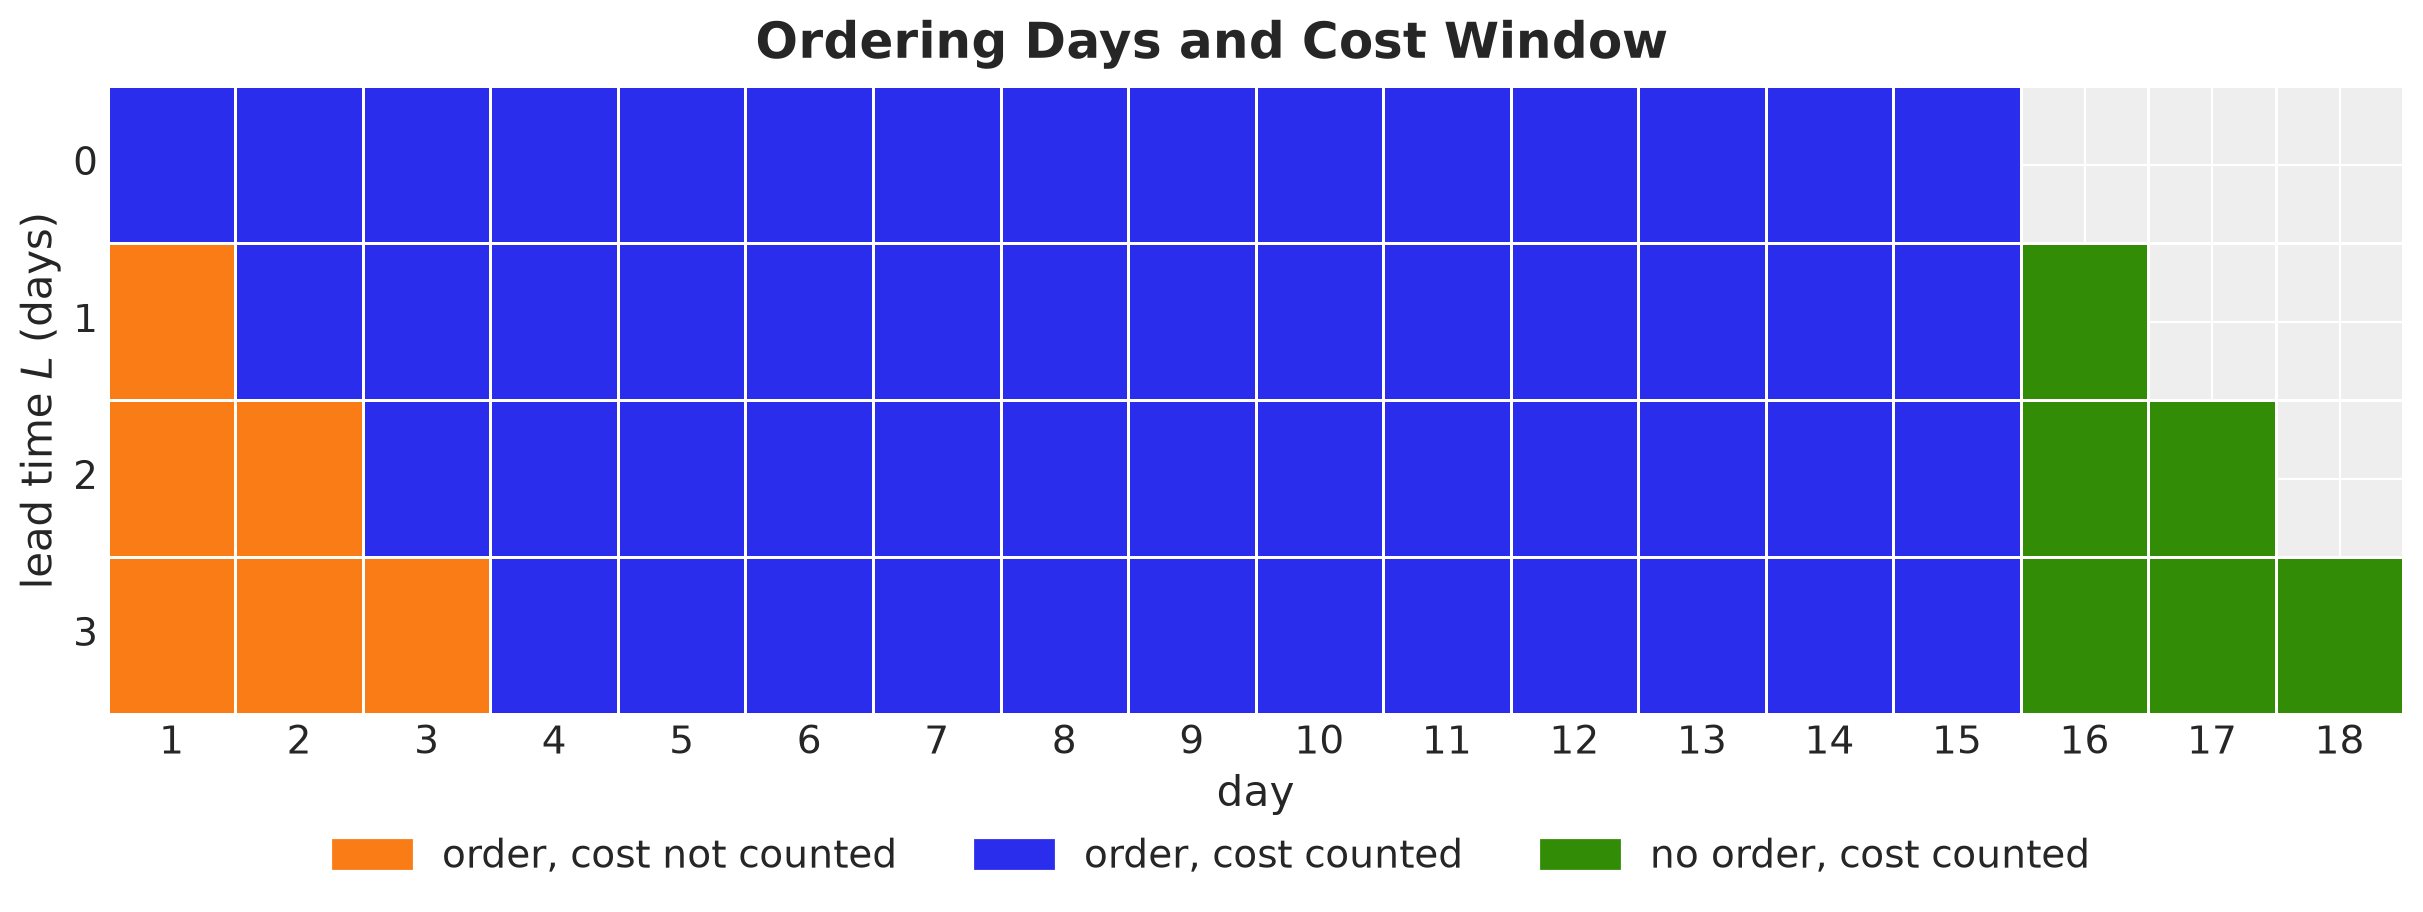

In [3]:
horizon_days = jnp.arange(1, setup.max_days + 1)
lead_times = jnp.asarray(setup.lead_times)[:, None]
is_ordering_day = jnp.broadcast_to(
    horizon_days <= setup.horizon, (lead_times.shape[0], setup.max_days)
)
is_cost_day = (horizon_days > lead_times) & (horizon_days <= setup.horizon + lead_times)
DAY_KINDS = {
    "order, cost not counted": is_ordering_day & ~is_cost_day,
    "order, cost counted": is_ordering_day & is_cost_day,
    "no order, cost counted": ~is_ordering_day & is_cost_day,
}
# one code per kind of day, and the days that we do not simulate stay empty
day_kind = jnp.select(
    list(DAY_KINDS.values()),
    [float(code) for code in range(len(DAY_KINDS))],
    default=jnp.nan,
)

kind_colors = ["C1", "C0", "C2"]

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(
    day_kind,
    cmap=kind_colors,
    cbar=False,
    linewidths=1,
    linecolor="white",
    xticklabels=horizon_days.tolist(),
    yticklabels=setup.lead_times,
    ax=ax,
)
ax.tick_params(axis="y", rotation=0)
ax.set(xlabel="day", ylabel="lead time $L$ (days)")
fig.legend(
    handles=[
        Patch(color=color, label=label)
        for color, label in zip(kind_colors, DAY_KINDS, strict=True)
    ],
    loc="outside lower center",
    ncol=3,
)
fig.suptitle("Ordering Days and Cost Window", fontsize=18, fontweight="bold");

Every row has $15$ ordering days and $15$ days in the cost window, and the cost window starts $L$ days after the first order. The empty cells are days that we do not simulate.

The cost window moves with the lead time, so it covers different days for different lead times. For this reason we compare the policies within a lead time, and we do not compare the loss of one policy across lead times.


### Policies

On day $t$ a policy sees the **observation** $o_t$: the day $t$, the stock on hand after the arrival of step $1$, each order in the pipeline, the demand of the last $K = 7$ days and the latest forecast. A **policy** is a function $\pi_\theta$ that maps the observation to the order of the day,

$$
a_t = \pi_\theta(o_t),
$$

where $\theta$ collects the parameters of the policy (not of the demand model). The observation contains only what we know when we order. In particular it does not contain the demand $D_t$ of the day or of any later day.

The loss now depends on the policy and on the demand path $D = (D_1, \dots, D_{H+L})$, so we write it as $C(\theta, D)$. As in the first post, we estimate its expected value with scenarios. Let $D^{(1)}, \dots, D^{(N)}$ be $N$ **scenarios**, joint draws of the demand path from the forecast. The **expected loss** of a policy is

$$
J(\theta) = \text{E}[C(\theta, D)] \approx \frac{1}{N} \sum_{n=1}^{N} C(\theta, D^{(n)}),
$$

and we look for the parameters $\theta$ that minimize it.

A fixed plan is a policy that ignores the observation. So from here on we call all five ways of placing the orders policies. The first one is the plan:

- **Fixed plan.** The order of day $t$ is one number, $\pi_\theta(o_t) = \theta_t$ with $\theta_t \geq 0$. For $L = 0$ this is the expected cost plan of the first post.

The base-stock policies need a target level. Recall the newsvendor problem of the first post. For a single day, the stock that minimizes the expected cost is the $p / (p + h)$ quantile of the demand, and the ratio $p / (p + h)$ is the **critical fractile**, $0.952$ for our costs.

With a lead time, the order of day $t$ arrives on day $t + L$, and the order of the next day arrives one day later. So the inventory position after the order of day $t$ has to cover the demand of the days $t, \dots, t + L$.

Let the **newsvendor level** $\hat{q}_t$ be the $p / (p + h)$ quantile of the total demand $D_t + \dots + D_{t+L}$ under a forecast. With it we define four policies that order up to a level from the inventory position:

- **Base-stock (day-one forecast).** The level of day $t$ is the newsvendor level of the forecast of day one, $\pi(o_t) = (\hat{q}_t - \text{IP}_t)^{+}$. It has no parameters.
- **Base-stock (weekly forecast).** The same rule, where $\hat{q}_t$ comes from the weekly forecast in the observation: the forecast of day one up to day $7$, and the updated forecast from day $8$ on. It has no parameters either.
- **Base-stock (trained).** The newsvendor level of the weekly forecast plus an **offset** $\theta_t$ for every ordering day, $\pi_\theta(o_t) = (\hat{q}_t + \theta_t - \text{IP}_t)^{+}$. The parameters are the $H$ offsets.
- **Neural.** A neural network $g_\theta$ adds a correction to the level of the trained base-stock policy, $\pi_\theta(o_t) = (\hat{q}_t + \theta_t + \bar{d} \, g_\theta(o_t) - \text{IP}_t)^{+}$, where $\bar{d}$ is the mean daily demand of the history.

Recall from the introduction that with lost sales and a positive lead time the base-stock policy is not optimal in general. [Zipkin (2008)](https://doi.org/10.1287/opre.1070.0471) tests several rules on this problem and reports:

> We find that several perform reasonably well, although none is perfect. However, the standard base-stock policy (a direct analogue of the optimal policy for a backlog system) performs badly.

See also the review of [Bijvank and Vis (2011)](https://doi.org/10.1016/j.ejor.2011.02.004). On the other hand, [Huh et al. (2009)](https://doi.org/10.1287/mnsc.1080.0945) show that the best base-stock policy is close to optimal when the lost margin is large compared with the holding cost. Our ratio is $p / h = 20$.

The neural policy tells us how much a more flexible rule gains over the base-stock policy in our problem. From $L = 2$ on, one or more orders are still in the pipeline when we decide. The inventory position adds them to the stock on hand, while the network sees each of them.

[Gijsbrechts et al. (2022)](https://doi.org/10.1287/msom.2021.1064) train neural policies for this lost-sales problem with deep reinforcement learning. We train ours through the simulator, which is possible because we know the inventory dynamics and we have the scenarios.

Now that we have the five policies, let's build the demand scenarios that all of them use.

## Demand Scenarios

### Demand Model

We use the data generating process and the forecasting model of the first post. The demand has a level that drifts as a random walk on the log scale, a weekly pattern, a price promotion with an elasticity, and negative binomial noise. A promotion cuts the price by $30\%$ for a week, and the second week of the horizon, days $8$ to $14$, is a promotion week. The first post explains the model, the prior elicitation with PreliZ and the diagnostics in its sections *Generate Data* to *Model Fitting*.

Here we write the model from small components. We use the same model to generate the data, to fit it, and to simulate demand paths from any day of the horizon. The forecast update after the first week needs the last one.

Let's start with the priors, which are the priors of the first post. We elicit three of them with PreliZ: `pz.maxent` returns the member of a family with the largest entropy among those with $94\%$ of their mass between two bounds. We state the other two directly.

- **`intercept`**: a Normal on the log of the demand per day at the start of the history at the list price, with $94\%$ of its mass between $\log 10$ and $\log 300$.
- **`drift_scale`**: a LogNormal on the standard deviation of the daily increments of the log level, with $94\%$ of its mass between $\log(1.04) / \sqrt{T}$ and $\log(2) / \sqrt{T}$, where $T = 364$ is the length of the history. So over one year the level moves by a factor between $1.04$ and $2$.
- **`concentration`**: a Gamma on the concentration $\phi$ of the negative binomial, with $94\%$ of its mass between $4$ and $100$. So the extra noise is between a tenth and a half of the level.
- **`beta`**: a $\text{Normal}(0, 0.3)$ for each Fourier coefficient of the weekly pattern.
- **`elasticity`**: a $\text{Normal}(-1, 1)$ for the price elasticity.

The model and the checks refer to the sample sites by name, so we keep the names in the `Site` class. Every model component gets its own small tuple of priors, and the `Priors` tuple collects them.

In [4]:
class Site:
    """Names of the sample sites of the demand model."""

    INTERCEPT: Final = "intercept"
    DRIFT_SCALE: Final = "drift_scale"
    DRIFT: Final = "drift"
    BETA: Final = "beta"
    ELASTICITY: Final = "elasticity"
    CONCENTRATION: Final = "concentration"
    # the expected demand of every day, a deterministic site
    MEAN: Final = "mean"
    # the demand, the site that `predict` registers
    OBS: Final = "obs"
    # the global parameters of the model
    PARAMETERS: Final = (INTERCEPT, DRIFT_SCALE, BETA, ELASTICITY, CONCENTRATION)


class LevelPriors(NamedTuple):
    """Priors of the random walk level."""

    intercept: dist.Distribution
    drift_scale: dist.Distribution


class SeasonalityPriors(NamedTuple):
    """Prior of the weekly seasonality."""

    beta: dist.Distribution


class PricePriors(NamedTuple):
    """Prior of the price effect."""

    elasticity: dist.Distribution


class DispersionPriors(NamedTuple):
    """Prior of the dispersion of the likelihood."""

    concentration: dist.Distribution


class Priors(NamedTuple):
    """Priors of the demand model, one tuple per component."""

    level: LevelPriors
    seasonality: SeasonalityPriors
    price: PricePriors
    dispersion: DispersionPriors


intercept_bounds = (math.log(10), math.log(300))
drift_bounds = (
    math.log(1.04) / math.sqrt(setup.t_obs),
    math.log(2) / math.sqrt(setup.t_obs),
)
concentration_bounds = (4.0, 100.0)


def elicit(
    family: pz.distributions.distributions.Continuous,
    bounds: tuple[float, float],
    mass: float = 0.94,
) -> pz.distributions.distributions.Continuous:
    """Maximum entropy member of `family` with `mass` between the bounds."""
    return pz.maxent(family, *bounds, mass=mass, plot=False)


# the three elicited priors and the two that we state directly
intercept_prior = elicit(pz.Normal(), intercept_bounds)
drift_prior = elicit(pz.LogNormal(), drift_bounds)
concentration_prior = elicit(pz.Gamma(), concentration_bounds)
beta_prior = pz.Normal(0.0, 0.3)
elasticity_prior = pz.Normal(-1.0, 1.0)

priors = Priors(
    level=LevelPriors(
        intercept=dist.Normal(intercept_prior.mu, intercept_prior.sigma),
        drift_scale=dist.LogNormal(drift_prior.mu, drift_prior.sigma),
    ),
    seasonality=SeasonalityPriors(beta=dist.Normal(beta_prior.mu, beta_prior.sigma)),
    price=PricePriors(
        elasticity=dist.Normal(elasticity_prior.mu, elasticity_prior.sigma)
    ),
    dispersion=DispersionPriors(
        concentration=dist.Gamma(concentration_prior.alpha, concentration_prior.beta)
    ),
)

pl.DataFrame(
    {
        "site": [
            Site.INTERCEPT,
            Site.DRIFT_SCALE,
            Site.CONCENTRATION,
            Site.BETA,
            Site.ELASTICITY,
        ],
        "prior": [
            str(prior)
            for prior in (
                intercept_prior,
                drift_prior,
                concentration_prior,
                beta_prior,
                elasticity_prior,
            )
        ],
    }
)

site,prior
str,str
"""intercept""","""Normal(mu=4, sigma=0.904)"""
"""drift_scale""","""LogNormal(mu=-4.26, sigma=0.60…"
"""concentration""","""Gamma(alpha=2.77, beta=0.0578)"""
"""beta""","""Normal(mu=0, sigma=0.3)"""
"""elasticity""","""Normal(mu=-1, sigma=1)"""


The table lists the five priors. For example, the `intercept` prior is centered at $4 \approx \log 55$, the middle of its bounds on the log scale.

Next, we write the components of the model. Each component samples its own sites. The first three return a term of the log of the expected demand with shape `(days, 1)`, one column because we have one series, and the last one returns the concentration of the likelihood.

- `local_level`: the log level $\ell_t$, the initial level `intercept` plus the summed daily increments `drift`.
- `weekly_seasonality`: the Fourier term with the coefficients `beta`.
- `price_effect`: the `elasticity` times the log of the price relative to the list price.
- `dispersion`: the `concentration` of the negative binomial.

The function `make_demand_model` adds the three terms, records the expected demand of every day in the deterministic site `mean`, and registers the likelihood with `predict` of [`numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/). The model has the signature `(covariates, data=None)` of `numpyro_forecast`. The covariates are the Fourier features of the weekly cycle and the log price of every day, so the model runs on any window of consecutive days.

In [5]:
def local_level(h: Horizon, priors: LevelPriors) -> Float[Array, "days 1"]:
    """Random walk level: the initial level plus the summed daily increments."""
    intercept = numpyro.sample(Site.INTERCEPT, priors.intercept)
    drift_scale = numpyro.sample(Site.DRIFT_SCALE, priors.drift_scale)
    drift = innovations(h, Site.DRIFT, dist.Normal(0.0, drift_scale))
    return intercept + jnp.cumsum(drift, axis=-2)


def weekly_seasonality(
    fourier: Float[Array, "days n_fourier"], priors: SeasonalityPriors
) -> Float[Array, "days 1"]:
    """Weekly Fourier seasonality."""
    beta = numpyro.sample(
        Site.BETA, priors.beta.expand([fourier.shape[-1]]).to_event(1)
    )
    return (fourier @ beta)[:, None]


def price_effect(
    log_price: Float[Array, " days"], priors: PricePriors
) -> Float[Array, "days 1"]:
    """Price elasticity times the log price relative to the list price."""
    elasticity = numpyro.sample(Site.ELASTICITY, priors.elasticity)
    return (elasticity * log_price)[:, None]


def dispersion(priors: DispersionPriors) -> Float[Array, ""]:
    """Concentration of the negative binomial."""
    return numpyro.sample(Site.CONCENTRATION, priors.concentration)


def make_demand_model(priors: Priors) -> ForecastModel:
    """Build the demand model as a plain `(covariates, data=None)` function."""

    def demand_model(
        covariates: Float[Array, "days features"],
        data: Int[Array, "t_obs 1"] | None = None,
    ) -> None:
        h = Horizon.from_data(covariates, data)
        # the Fourier features in the first columns and the log price in the last one
        fourier, log_price = covariates[:, :-1], covariates[:, -1]
        log_mean = (
            local_level(h, priors.level)
            + weekly_seasonality(fourier, priors.seasonality)
            + price_effect(log_price, priors.price)
        )
        concentration = dispersion(priors.dispersion)
        numpyro.deterministic(Site.MEAN, jnp.exp(log_mean))

        def likelihood(log_mean: Float[Array, "days 1"]) -> dist.Distribution:
            """Negative binomial with a log link."""
            return dist.NegativeBinomial2(jnp.exp(log_mean), concentration)

        predict(h, likelihood, log_mean)

    return demand_model


demand_model = make_demand_model(priors)

Before we fit the model, we generate the data. Besides the parameters and the demand, the calendar of the promotions is the only random input. We draw it from a small generative model: one Bernoulli per week of the history, repeated over its seven days, followed by the plan of the retailer for the days after the history. The deterministic `log_price` site is the log of the price relative to the list price, $\log(1 - 0.3)$ in a promotion week and zero otherwise.

We need covariates for more days than the horizon. The longest lead time adds $3$ days to the $15$ ordering days, and the forecast of each of these $18$ days covers its own lead time, up to $3$ more days. So the calendar covers the $364$ days of the history and $21$ days after it.

The forecasts of the days after day $15$ never reach an order, but the simulator reads one on every day. Only the second week of the horizon is a promotion week.

Then we fix the true parameters of the first post with the `do` handler and draw the history from the demand model. We keep the daily increments of the level, because the true process test set starts from the true level at the end of the history. This history is a new draw from the process of the first post, so the numbers in this notebook are not the ones of the first post.

In [6]:
def calendar_generator(setup: Setup, promo_future: Float[Array, " num_future"]) -> None:
    """Promotion weeks of the history, followed by the planned future days."""
    # one Bernoulli per week of history, repeated over its seven days
    with numpyro.plate("week", setup.t_obs // 7):
        promo_week = numpyro.sample("promo_week", dist.Bernoulli(setup.promo_prob))

    promo = jnp.concatenate([jnp.repeat(promo_week, 7), promo_future])
    numpyro.deterministic("log_price", promo * jnp.log(1.0 - setup.discount))


# the retailer's plan: a promotion in the second week of the horizon and none after it
promo_future = jnp.zeros(setup.num_future).at[7:14].set(1.0)
rng_key, key_calendar = random.split(rng_key)
calendar = Predictive(calendar_generator, num_samples=1)(
    key_calendar, setup, promo_future
)

# three harmonics of the weekly cycle, and the log price in the last column
fourier = fourier_features(setup.t_obs + setup.num_future, period=7.0, num_terms=3)
covariates = jnp.concatenate([fourier, calendar["log_price"][0][:, None]], axis=1)
covariates_history = covariates[: setup.t_obs]
covariates_future = covariates[setup.t_obs :]

true_params: dict[str, Array] = {
    Site.INTERCEPT: jnp.log(60.0),
    Site.DRIFT_SCALE: jnp.array(0.01),
    Site.BETA: jnp.array([0.15, 0.05, -0.08, 0.10, 0.03, -0.02]),
    Site.ELASTICITY: jnp.array(-1.5),
    Site.CONCENTRATION: jnp.array(30.0),
}

rng_key, key_data = random.split(rng_key)
draw = Predictive(
    do(demand_model, data=true_params),
    num_samples=1,
    return_sites=[Site.OBS, Site.DRIFT],
)(key_data, covariates_history)

data = draw[Site.OBS][0].astype(jnp.int32)
assert data.shape == (setup.t_obs, 1)

# the true log level on the last day of the history: the initial level plus the
# increments
level_true = true_params[Site.INTERCEPT] + draw[Site.DRIFT][0].sum()

Now we fit the model to the history with NUTS. As in the first post, the sampler works with standardized increments of the level, the non-centered parameterization. The `handlers.reparam` handler applies it from the outside, so the data generator and the simulations below use the model as it is. We use the sampler settings of the first post, including its target acceptance probability of $0.9$.

In [7]:
%%time

TARGET_ACCEPT_PROB = 0.9
non_centered_model = handlers.reparam(
    demand_model, config={Site.DRIFT: LocScaleReparam(0)}
)
rng_key, key_fit = random.split(rng_key)
mcmc = MCMC(
    NUTS(non_centered_model, target_accept_prob=TARGET_ACCEPT_PROB),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
)
mcmc.run(key_fit, covariates_history, data)

posterior = mcmc.get_samples()
rng_key, key_tree = random.split(rng_key)
idata = to_datatree(
    key_tree,
    non_centered_model,
    posterior,
    data,
    covariates[: setup.t_obs + setup.horizon],
    num_chains=4,
)

CPU times: user 1min 1s, sys: 1min 19s, total: 2min 21s
Wall time: 16.2 s


As in the first post, we look at the $\hat{R}$ values and the effective sample sizes of the global parameters.

In [8]:
az.summary(idata, var_names=list(Site.PARAMETERS))

,mean,sd,eti94_lb,eti94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,4.016,0.054,3.9,4.1,2913,2795,1.00,0.001,0.00095
drift_scale,0.0125,0.0046,0.0052,0.022,1273,2130,1.00,0.00013,7.2e-05
beta[0],0.1207,0.0174,0.088,0.15,5583,2508,1.00,0.00023,0.00035
beta[1],0.0248,0.0172,-0.0073,0.057,6281,3039,1.00,0.00022,0.00029
beta[2],-0.1228,0.0171,-0.15,-0.091,6305,3042,1.00,0.00022,0.00029
beta[3],0.1328,0.0172,0.1,0.17,5949,2821,1.00,0.00022,0.00034
beta[4],0.046,0.0171,0.014,0.078,7401,3316,1.00,0.0002,0.00028
beta[5],-0.0478,0.0171,-0.08,-0.016,6444,2781,1.00,0.00022,0.0003
elasticity,-1.689,0.1,-1.9,-1.5,4857,3010,1.00,0.0014,0.0015
concentration,27.8,3.2,22,34,3859,2850,1.00,0.052,0.055


The $\hat{R}$ values are at most $1.01$ and the effective sample sizes are above $1{,}000$ for every parameter, which is good! We check the first one with an assertion, because the rest of the notebook depends on this fit.

Next, we count the divergent transitions. A divergent transition is a step of the sampler where the numerical error of the trajectory explodes. A large number of them, or a cluster in one region of the posterior, means that the sampler cannot explore that region.

With a random walk level, the usual region is the funnel at small values of `drift_scale`, where the increments are squeezed together. So for every divergent transition we also compute the percentile of its value of `drift_scale` in the posterior.

In [9]:
assert float(az.summary(idata, var_names=list(Site.PARAMETERS))["r_hat"].max()) <= 1.01

diverging = mcmc.get_extra_fields()["diverging"]
drift_scale_draws = posterior[Site.DRIFT_SCALE]
pl.DataFrame(
    {
        "divergent transition": list(range(1, int(diverging.sum()) + 1)),
        "drift_scale percentile": [
            round(100 * float((drift_scale_draws < value).mean()))
            for value in drift_scale_draws[diverging]
        ],
    }
)

divergent transition,drift_scale percentile
i64,i64
1,84
2,71
3,52
4,37


The sampler reports $4$ divergent transitions in $4{,}000$ draws. They are spread over the posterior: their values of `drift_scale` sit between the $37$th and the $84$th percentile, and none is at the small values of a funnel.

The priors are the ones of the first post, and its PyMC appendix also reported a few divergent transitions at a target acceptance probability of $0.95$. We accept these $4$, since they do not point to a region that the sampler misses, and the $\hat{R}$ values and the effective sample sizes are good.

### Scenario Sets

In the first post a scenario was a posterior predictive draw of the $15$ days. We shuffled the $4{,}000$ draws and used $1{,}000$ of them to build the plans, the **optimization set**, and the other $3{,}000$ to score them, the **evaluation set**. Here we keep this split and make three changes.

- **Longer paths.** The longest lead time needs $15 + 3 = 18$ days of demand. The $3$ extra days have no promotion.
- **A validation set.** The neural policy has many parameters, so we choose its parameters on scenarios that it does not train on.
- **A split by posterior draw.** Every scenario comes from one posterior draw of the parameters and the level. We split the draws and not the scenarios: the training set, the validation set and the forecast updates use the $1{,}000$ optimization draws, and the test scenarios come from the other $3{,}000$ draws. So no policy sees the parameters behind a test scenario.

To simulate demand paths from a posterior draw we need its parameters and the log level $\ell_T$ of the demand on the last day of the history. We call such a pair a **particle**. The name comes from the particle filter of the *Forecast Updates* section, which updates these pairs with the demand that we observe.

The `Particles` tuple holds a batch of particles, with the index of the posterior draw of each one. The function `select_particles` takes a subset of a batch by position, and we use it right away to check that the batch of all posterior draws has one particle per draw.

In [10]:
class Particles(NamedTuple):
    """Parameter draws with the log level of the demand on the last observed day."""

    draw: Int[Array, " particles"]  # index of the posterior draw
    level: Float[Array, " particles"]
    drift_scale: Float[Array, " particles"]
    beta: Float[Array, "particles n_fourier"]
    elasticity: Float[Array, " particles"]
    concentration: Float[Array, " particles"]


def select_particles(particles: Particles, index: Int[Array, " num"]) -> Particles:
    """The particles at the positions `index`, with all their fields."""
    return jax.tree.map(lambda leaf: leaf[index], particles)


particles_all = Particles(
    draw=jnp.arange(posterior[Site.INTERCEPT].shape[0]),
    # the level on the last day of the history: the initial level plus the increments
    level=posterior[Site.INTERCEPT] + posterior[Site.DRIFT].sum(axis=(1, 2)),
    drift_scale=posterior[Site.DRIFT_SCALE],
    beta=posterior[Site.BETA],
    elasticity=posterior[Site.ELASTICITY],
    concentration=posterior[Site.CONCENTRATION],
)

# the first three particles, one row per particle
first_three = select_particles(particles_all, jnp.arange(3))
pl.DataFrame(
    {
        "draw": first_three.draw.tolist(),
        "level": first_three.level.tolist(),
        "exp(level)": jnp.exp(first_three.level).tolist(),
        "elasticity": first_three.elasticity.tolist(),
    }
)

draw,level,exp(level),elasticity
i64,f64,f64,f64
0,4.2,64.8,-1.7
1,4.0,54.7,-1.7
2,4.1,62.4,-1.7


Every particle carries its own level at the end of the history, here between $\exp(\ell_T) \approx 55$ and $65$ units per day at the list price, and its own parameters.

Recall that the level of the model starts at `intercept`. So if we put the level $\ell_T$ of a particle in place of `intercept` and run the model with `Predictive` on the covariates of the next days, the model continues the random walk from $\ell_T$. The function `model_params` maps a batch of particles to the sites of the model in this way, and `simulate_demand` draws one demand path per particle from any day after the history. So we do not need a second simulator.

We check `simulate_demand` against the forecast of `numpyro_forecast`, which continues the random walk of every posterior draw from its own increments.

In [11]:
def model_params(particles: Particles) -> dict[str, Array]:
    """The sites of the model for every particle, starting from its level."""
    return {
        Site.INTERCEPT: particles.level,
        Site.DRIFT_SCALE: particles.drift_scale,
        Site.BETA: particles.beta,
        Site.ELASTICITY: particles.elasticity,
        Site.CONCENTRATION: particles.concentration,
    }


def covariate_window(
    first_day: Int[Array, ""] | int, num_days: int
) -> Float[Array, "num_days features"]:
    """Covariates of `num_days` days from day `first_day` of the horizon on."""
    return jax.lax.dynamic_slice(
        covariates_future, (first_day, 0), (num_days, covariates_future.shape[1])
    )


def simulate_demand(
    key: PRNGKeyArray,
    particles: Particles,
    first_day: Int[Array, ""] | int,
    num_days: int,
) -> Float[Array, "particles num_days"]:
    """One demand path per particle for `num_days` days from `first_day` on."""
    predictive = Predictive(
        demand_model,
        posterior_samples=model_params(particles),
        return_sites=[Site.OBS],
        parallel=True,
    )
    demand = predictive(key, covariate_window(first_day, num_days))[Site.OBS]
    return demand[..., 0].astype(jnp.float32)


# the forecast of `numpyro_forecast` over the 15 days of the horizon
forecast_horizon = jnp.asarray(
    idata["predictions"][Site.OBS].values.reshape(-1, setup.horizon),
    dtype=jnp.float32,
)
rng_key, key_check = random.split(rng_key)
demand_check = simulate_demand(key_check, particles_all, 0, setup.horizon)

# the daily means and the 97% quantiles agree up to Monte Carlo error
assert jnp.allclose(demand_check.mean(axis=0), forecast_horizon.mean(axis=0), rtol=0.02)
assert jnp.allclose(
    jnp.quantile(demand_check, 0.97, axis=0),
    jnp.quantile(forecast_horizon, 0.97, axis=0),
    rtol=0.04,
)

The two agree on the $15$ days of the horizon: the daily means are within $2\%$ of each other and the daily $97\%$ quantiles within $4\%$.

Now we build the scenario sets. First, we shuffle the posterior draws and split them as the first post split its scenarios: $1{,}000$ optimization draws and $3{,}000$ test draws. Of the optimization draws, $800$ go to the training set and $200$ to the validation set, and each of them gives $5$ scenarios. The assertion checks that no posterior draw behind a test scenario is an optimization draw.

In [12]:
class ScenarioSet(StrEnum):
    """Names of the scenario sets."""

    TRAINING = "training set"
    VALIDATION = "validation set"
    FORECAST = "forecast test set"
    TRUE_PROCESS = "true process test set"


NUM_DRAWS_OPT = 1_000
NUM_DRAWS_TRAIN = 800
PATHS_PER_DRAW = 5

rng_key, key_split = random.split(rng_key)
draw_order = random.permutation(key_split, particles_all.draw.shape[0])
draws_opt, draws_test = draw_order[:NUM_DRAWS_OPT], draw_order[NUM_DRAWS_OPT:]

# the optimization particles, and the test particles with one scenario each
particles_opt = select_particles(particles_all, draws_opt)
particles_test = select_particles(particles_all, draws_test)
assert not jnp.isin(particles_opt.draw, particles_test.draw).any()

# 5 copies of each training and validation particle, one per scenario
particles_train = select_particles(
    particles_opt, jnp.tile(jnp.arange(NUM_DRAWS_TRAIN), PATHS_PER_DRAW)
)
particles_val = select_particles(
    particles_opt, jnp.tile(jnp.arange(NUM_DRAWS_TRAIN, NUM_DRAWS_OPT), PATHS_PER_DRAW)
)
pl.DataFrame(
    {
        "scenario set": [str(ScenarioSet.TRAINING), str(ScenarioSet.VALIDATION)],
        "posterior draws": [NUM_DRAWS_TRAIN, NUM_DRAWS_OPT - NUM_DRAWS_TRAIN],
        "scenarios": [particles_train.draw.shape[0], particles_val.draw.shape[0]],
    }
)

scenario set,posterior draws,scenarios
str,i64,i64
"""training set""",800,4000
"""validation set""",200,1000


The split is by draw, so the validation set also has parameter values that the training set does not have.

Next, we simulate the scenarios: $18$ days from every particle of the training set, the validation set and the test draws. The last one is the **forecast test set**, one path from each of the $3{,}000$ test draws.

In [13]:
rng_key, key_train, key_val, key_test = random.split(rng_key, 4)
demand_by_set: dict[ScenarioSet, Float[Array, "scenarios days"]] = {
    ScenarioSet.TRAINING: simulate_demand(
        key_train, particles_train, 0, setup.max_days
    ),
    ScenarioSet.VALIDATION: simulate_demand(key_val, particles_val, 0, setup.max_days),
    ScenarioSet.FORECAST: simulate_demand(key_test, particles_test, 0, setup.max_days),
}
{str(name): paths.shape for name, paths in demand_by_set.items()}

{'training set': (4000, 18),
 'validation set': (1000, 18),
 'forecast test set': (3000, 18)}

Because the data are synthetic, we can also draw paths from the true parameters and the true level at the end of the history. The **true process test set** has $3{,}000$ such paths. These scenarios tell us how a policy that was trained on the forecast does when the demand comes from the process that generated the data. We give the true particle the draw index $-1$, which no posterior draw has.

In [14]:
true_particle = Particles(
    draw=jnp.asarray(-1),
    level=level_true,
    drift_scale=true_params[Site.DRIFT_SCALE],
    beta=true_params[Site.BETA],
    elasticity=true_params[Site.ELASTICITY],
    concentration=true_params[Site.CONCENTRATION],
)
# one copy of the true particle per path
particles_true = jax.tree.map(
    lambda leaf: jnp.broadcast_to(leaf, (draws_test.shape[0], *leaf.shape)),
    true_particle,
)
rng_key, key_true = random.split(rng_key)
demand_by_set[ScenarioSet.TRUE_PROCESS] = simulate_demand(
    key_true, particles_true, 0, setup.max_days
)
# the particles behind every scenario set, which the forecast updates need
particles_by_set = {
    ScenarioSet.TRAINING: particles_train,
    ScenarioSet.VALIDATION: particles_val,
    ScenarioSet.FORECAST: particles_test,
    ScenarioSet.TRUE_PROCESS: particles_true,
}
TEST_SETS = [ScenarioSet.FORECAST, ScenarioSet.TRUE_PROCESS]
demand_by_set[ScenarioSet.TRUE_PROCESS].shape

(3000, 18)

Let's look at the forecast test set over the $18$ days, next to the last $4$ weeks of the history. We want to see whether the $3$ extra days look reasonable and where the true process lies inside the forecast. The bands are the $50\%$ and $94\%$ equal-tailed intervals (ETI) of the forecast test set, that is, the ranges between two percentiles.

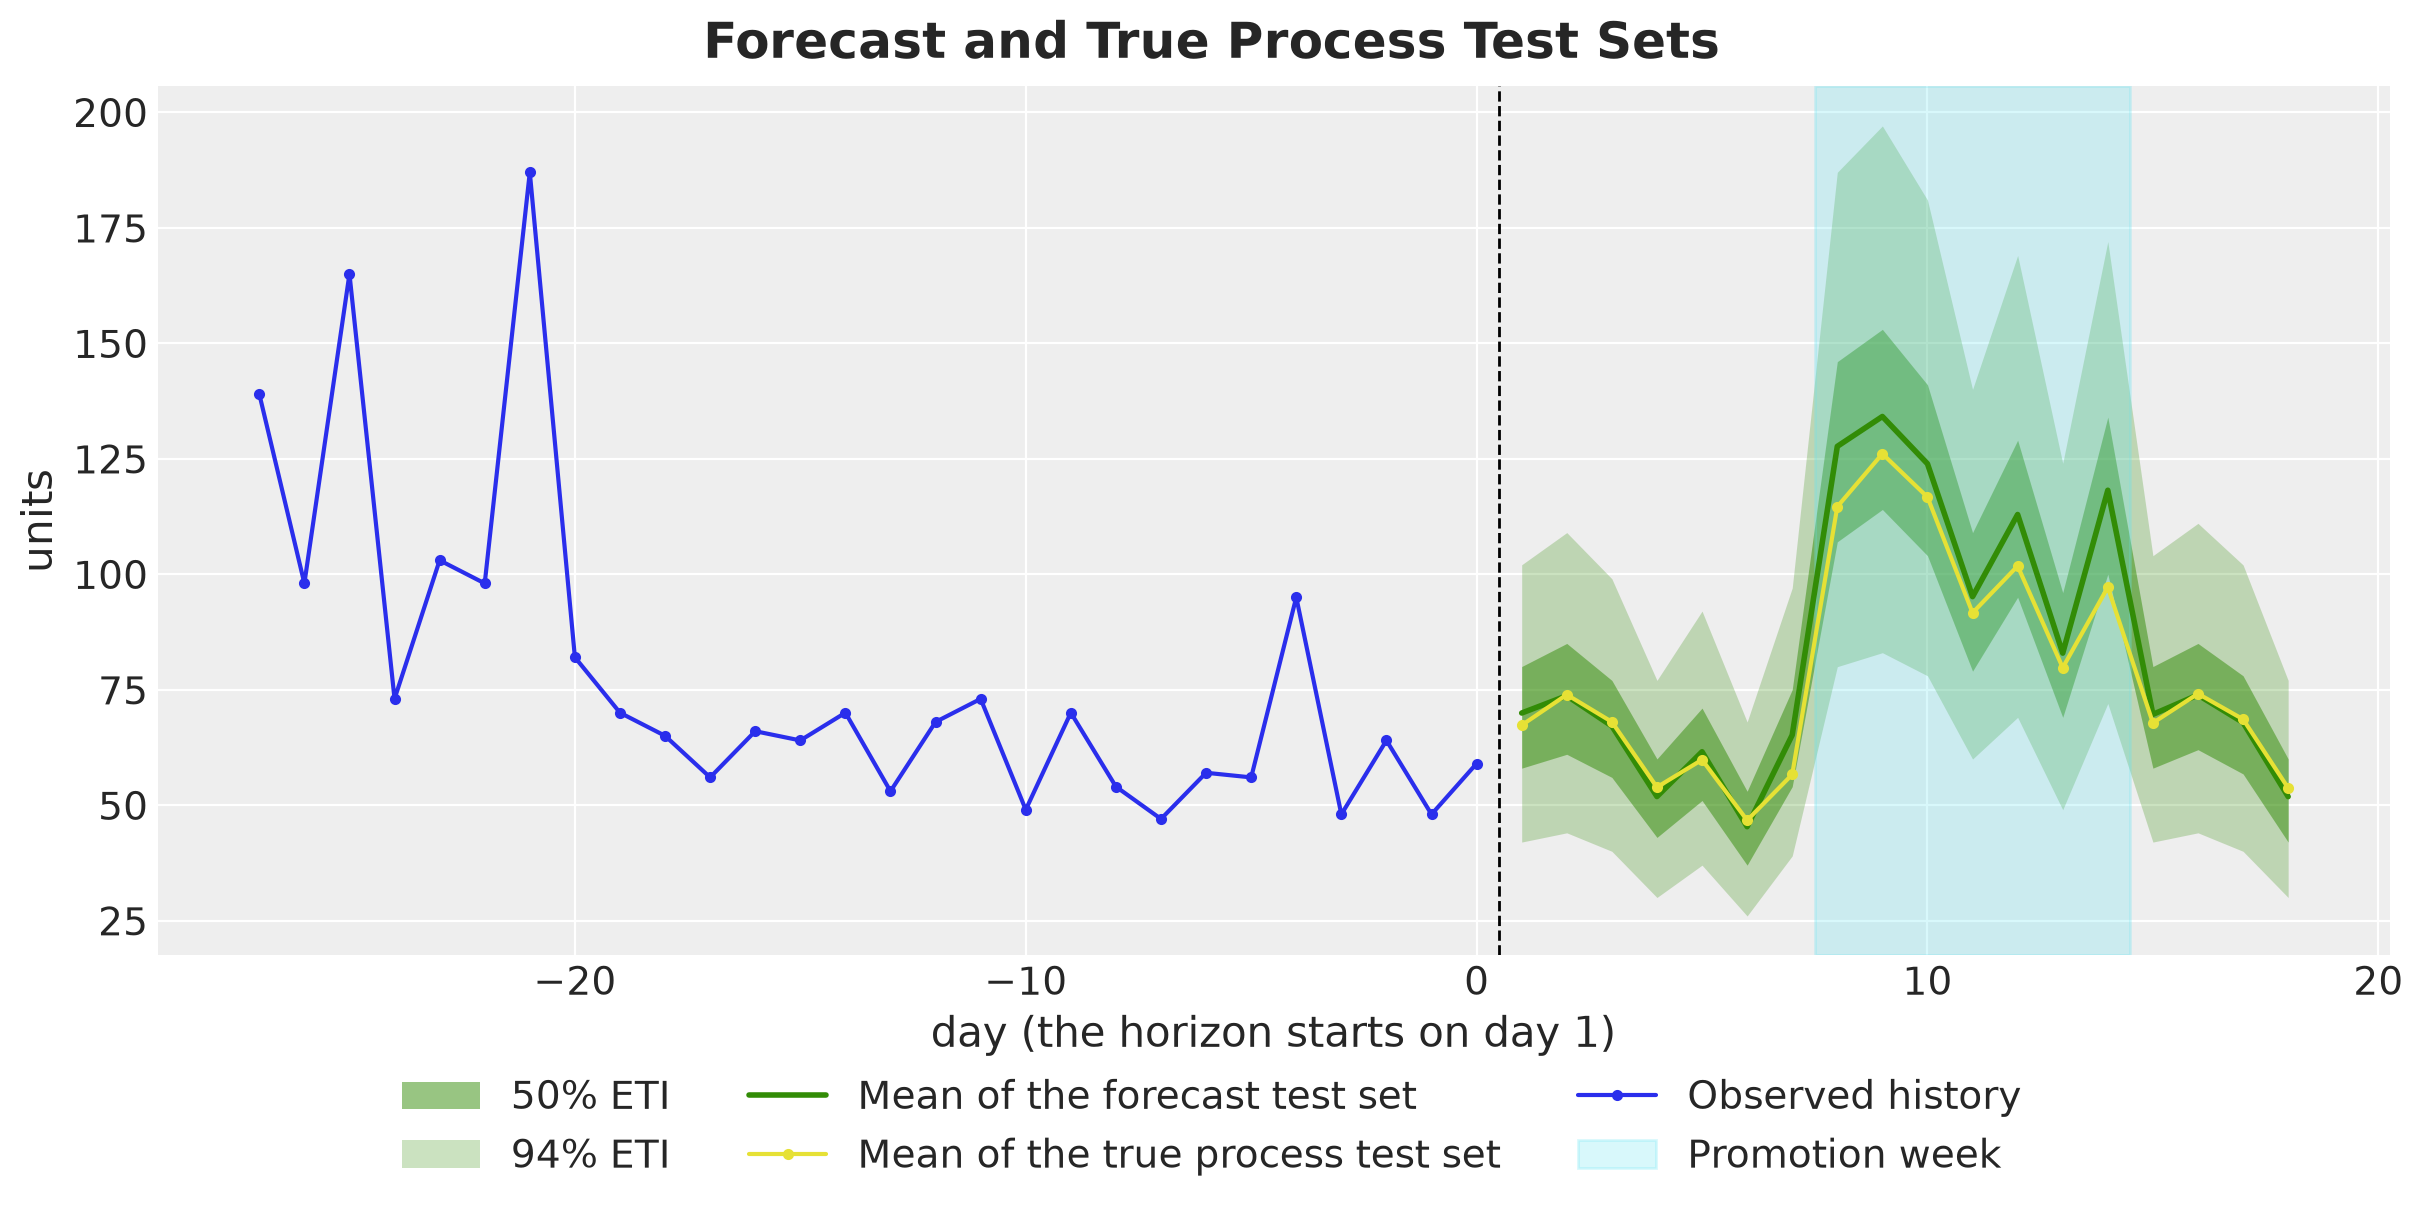

In [15]:
def lighten_bands(pc: az.PlotCollection, x: str) -> None:
    """Set the alpha of the 50% and 94% credible bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]

    for prob, alpha in [(0.5, 0.5), (CI_PROB, 0.25)]:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


def shade_promotion(ax: plt.Axes) -> None:
    """Shade the promotion week of the horizon."""
    promoted = jnp.flatnonzero(promo_future) + 1
    ax.axvspan(
        promoted[0] - 0.5,
        promoted[-1] + 0.5,
        color="C5",
        alpha=0.25,
        label="Promotion week",
    )


forecast_tree = az.from_dict(
    {
        "posterior_predictive": {"demand": demand_by_set[ScenarioSet.FORECAST][None]},
        "observed_data": {
            "demand": demand_by_set[ScenarioSet.TRUE_PROCESS].mean(axis=0)
        },
        # ArviZ sorts the x values in place, which a JAX array does not allow
        "constant_data": {"day": jax.device_get(horizon_days)},
    },
    coords={"time": horizon_days.tolist()},
    dims={"demand": ["time"], "day": ["time"]},
)

pc = az.plot_lm(
    forecast_tree,
    x="day",
    y="demand",
    y_obs="demand",
    smooth=False,
    ci_prob=(0.5, CI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C2"},
        "pe_line": {"color": "C2", "alpha": 1.0, "linewidth": 2},
        "observed_scatter": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "day")
ax = pc.viz["plot"]["day"].item()
pc.viz["ci_band"]["day"].sel(prob=CI_PROB).item().set_label(f"{CI_PROB:.0%} ETI")
pc.viz["ci_band"]["day"].sel(prob=0.5).item().set_label("50% ETI")
pc.viz["pe_line"]["day"].item().set_label(f"Mean of the {ScenarioSet.FORECAST}")
ax.plot(
    horizon_days,
    demand_by_set[ScenarioSet.TRUE_PROCESS].mean(axis=0),
    "o-",
    markersize=3,
    color="C6",
    label=f"Mean of the {ScenarioSet.TRUE_PROCESS}",
)
# the two means are within 20% of each other on every day
assert jnp.allclose(
    demand_by_set[ScenarioSet.TRUE_PROCESS].mean(axis=0),
    demand_by_set[ScenarioSet.FORECAST].mean(axis=0),
    rtol=0.2,
)
history_days = jnp.arange(-27, 1)
ax.plot(
    history_days,
    data[-len(history_days) :, 0],
    "o-",
    markersize=3,
    color="C0",
    label="Observed history",
)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
shade_promotion(ax)
ax.set(xlabel="day (the horizon starts on day $1$)", ylabel="units", title="")
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Forecast and True Process Test Sets", fontsize=18, fontweight="bold");

The forecast follows the weekly pattern and rises in the promotion week (the shaded days), as in the first post, and the $3$ extra days look like the first days of the horizon. The mean of the true process test set lies inside the $50\%$ band of the forecast on almost every day. Still, it is below the mean of the forecast test set in the promotion week.

The posterior is not centered on every true parameter. For example, the posterior mean of the `elasticity` is $-1.69$ with a standard deviation of $0.10$, against a true value of $-1.5$. So the forecast expects more demand in the promotion week than the true process has. Keep this in mind for the evaluation.



## Forecast Updates

In practice we do not keep the forecast of day one for the whole horizon. When new demand comes in, we run the forecasting model again. A retailer that runs its forecast every week updates it after the first week, and so do we: on day $8$ we update the forecast with the demand of the first week. The forecast of day $1$ is the forecast of the model of the first post, fitted to this history.

Why can an update help? In the scenarios from the forecast, every path has its own parameters and its own level, and the days of a path share them. So a path that starts above the forecast mean tends to stay above it. Let's check this on the scenarios. The next figure shows the total demand of the first week against the total demand of days $8$ to $15$, for the training set and for the true process test set.

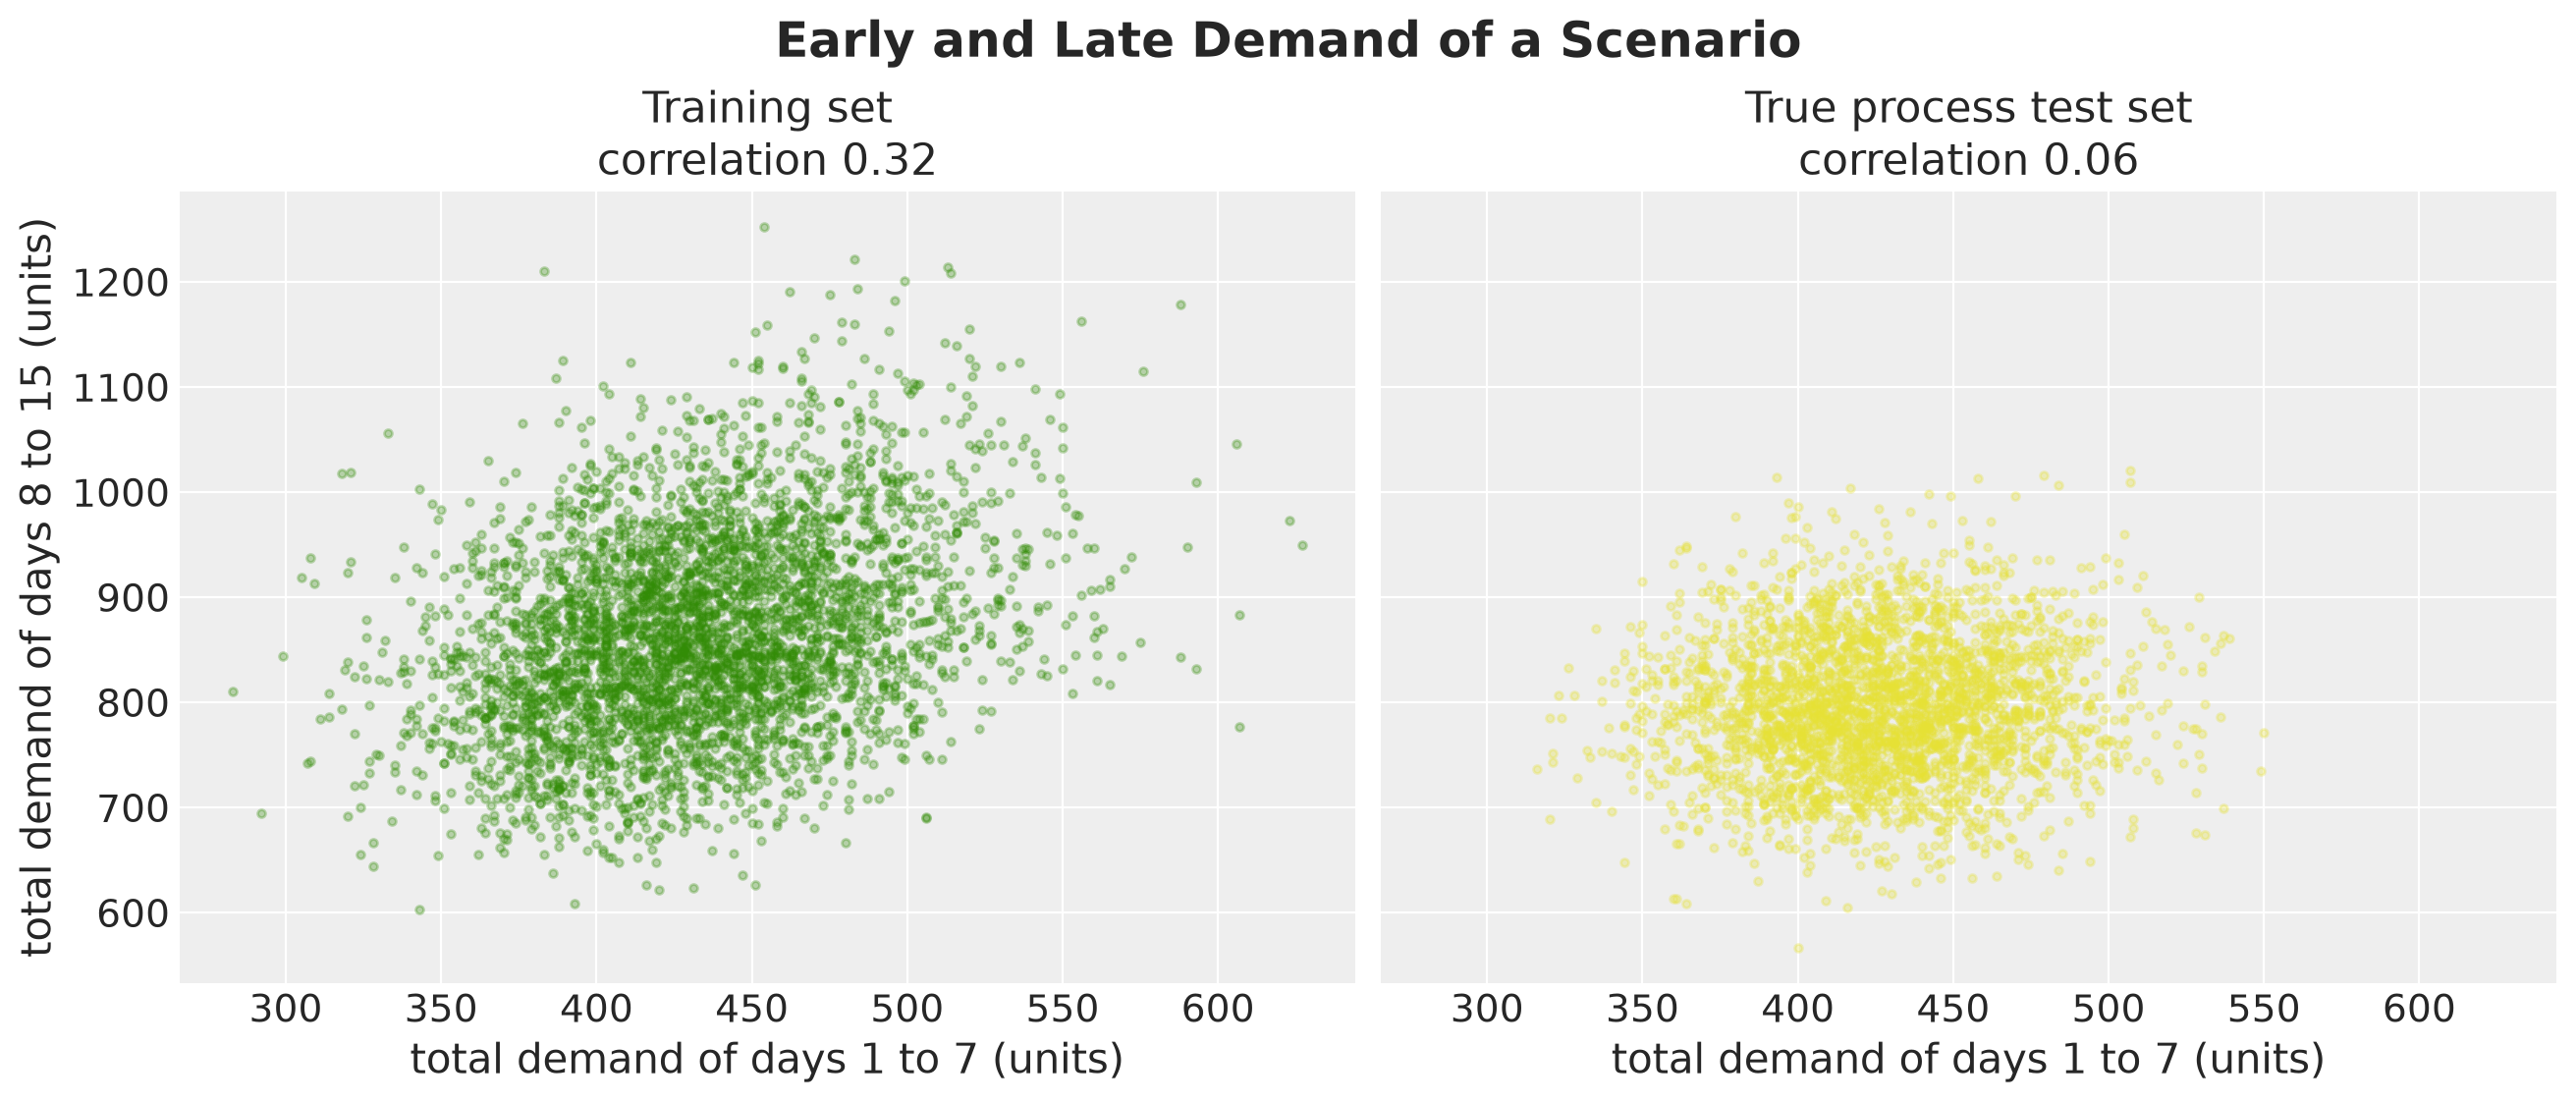

In [16]:
fig, axes = plt.subplots(
    ncols=2, figsize=(13, 5.5), sharex=True, sharey=True, layout="constrained"
)

for ax, scenario_set, color in zip(
    axes, [ScenarioSet.TRAINING, ScenarioSet.TRUE_PROCESS], ["C2", "C6"], strict=True
):
    first_week = demand_by_set[scenario_set][:, :7].sum(axis=1)
    later_days = demand_by_set[scenario_set][:, 7 : setup.horizon].sum(axis=1)
    correlation = float(jnp.corrcoef(first_week, later_days)[0, 1])
    ax.scatter(first_week, later_days, s=8, alpha=0.3, color=color)
    ax.set(
        title=f"{scenario_set.capitalize()}\ncorrelation {correlation:.2f}",
        xlabel="total demand of days $1$ to $7$ (units)",
    )

axes[0].set(ylabel="total demand of days $8$ to $15$ (units)")
fig.suptitle("Early and Late Demand of a Scenario", fontsize=18, fontweight="bold");

In the training set the correlation is $0.32$, so a scenario with a high first week tends to have a high demand afterwards. In the true process test set it is $0.06$. All of its scenarios share the true parameters and the true level, and what is left is the small drift of the level inside the horizon.

The forecast does not know the parameters and the level exactly, and its scenarios differ in them. This is the uncertainty that the observed demand can reduce. An update with the first week of a path moves the forecast toward the parameters and the level of that path.

### Particle Filter

To update the forecast we could fit the model again with NUTS, as the first post suggests. But we need an update for each of the $11{,}000$ scenarios of the training, validation and test sets, and a fit takes about $20$ seconds. A **particle filter** approximates this update at a small fraction of the cost, see the tutorial of [Doucet and Johansen (2011)](https://www.stats.ox.ac.uk/~doucet/doucet_johansen_tutorialPF2011.pdf).

We start from the $1{,}000$ particles of the optimization draws, each with the same weight. This weighted set is our **belief** about the parameters and the level. We store the logarithms of the normalized weights $w_j$, which keeps very small weights from rounding to zero. The **effective sample size** $1 / \sum_j w_j^2$ measures how many particles have a weight that matters, and it is $1{,}000$ when all the weights are equal.

One detail matters for the training and validation scenarios. Each of them comes from an optimization draw, and that draw is also a particle. A filter that starts with it could single out the parameters of the scenario, which a filter on a test scenario cannot do. So the function `uniform_belief` gives zero weight to the particle of the posterior draw behind a scenario, if there is one. Let's look at the initial belief of the first training scenario and of the first test scenario.

In [17]:
class Belief(NamedTuple):
    """Weighted particles: what we know about the demand process on a day."""

    particles: Particles  # the level is the level of the last observed day
    log_weights: Float[Array, " particles"]  # normalized


def uniform_belief(particles: Particles, exclude: Int[Array, ""] | int = -1) -> Belief:
    """Equal weights, and zero weight on the particle of the draw `exclude`."""
    keep = particles.draw != exclude
    return Belief(particles, jnp.where(keep, -jnp.log(keep.sum()), -jnp.inf))


def effective_sample_size(log_weights: Float[Array, " particles"]) -> Float[Array, ""]:
    """One over the sum of the squared normalized weights."""
    return 1.0 / jnp.exp(logsumexp(2.0 * log_weights))


initial_beliefs = {
    ScenarioSet.TRAINING: uniform_belief(particles_opt, particles_train.draw[0]),
    ScenarioSet.FORECAST: uniform_belief(particles_opt, particles_test.draw[0]),
}
pl.DataFrame(
    {
        "first scenario of the": [str(name) for name in initial_beliefs],
        "particles with a positive weight": [
            int(jnp.isfinite(belief.log_weights).sum())
            for belief in initial_beliefs.values()
        ],
        "effective sample size": [
            float(effective_sample_size(belief.log_weights))
            for belief in initial_beliefs.values()
        ],
    }
)

first scenario of the,particles with a positive weight,effective sample size
str,i64,f64
"""training set""",999,999.0
"""forecast test set""",1000,1000.0


The training scenario starts with $999$ particles, and the test scenario with all $1{,}000$, since its posterior draw is not an optimization draw.

When the weights concentrate on a few particles, the filter **resamples**: it draws a new set of particles in proportion to the weights and resets the weights. The function `systematic_resample` uses one uniform number for all the draws, which keeps the count of every particle within one of its expected count. As an example, we draw $10$ particles from $5$ particles with weights $0.5$, $0.25$, $0.15$, $0.1$ and $0$.

In [18]:
def systematic_resample(
    key: PRNGKeyArray, log_weights: Float[Array, " particles"], num: int
) -> Int[Array, " num"]:
    """Positions of `num` particles drawn in proportion to their weights."""
    cumulative = jnp.cumsum(jax.nn.softmax(log_weights))
    # one uniform shift for `num` equally spaced points, scaled to the total weight
    points = (random.uniform(key) + jnp.arange(num)) / num * cumulative[-1]
    index = jnp.searchsorted(cumulative, points)
    return jnp.minimum(index, log_weights.shape[0] - 1)


example_weights = jnp.array([0.5, 0.25, 0.15, 0.1, 0.0])
rng_key, key_example = random.split(rng_key)
example_index = systematic_resample(key_example, jnp.log(example_weights), 10)
pl.DataFrame(
    {
        "weight": example_weights.tolist(),
        "expected count": (10 * example_weights).tolist(),
        "count": jnp.bincount(example_index, length=5).tolist(),
    }
)

weight,expected count,count
f64,f64,i64
0.5,5.0,5
0.2,2.5,2
0.2,1.5,2
0.1,1.0,1
0.0,0.0,0


Every count is within one of its expected count, and the particle with weight zero is never drawn.

Now we turn to the update itself. When we observe the demand of a day, the function `filter_step` updates the belief in three steps:

- **Move.** The level of every particle takes one step of its random walk, so that it is the level of the observed day. The demand model draws this step: we run it with `Predictive` on the covariates of the observed day, with the level of the particle in place of `intercept`, and keep the increment `drift`.
- **Weight.** We multiply the weight of every particle by the likelihood of the observed demand under its parameters and its new level. The function `log_likelihood` of NumPyro computes it from the same model, with the increment of the move fixed.
- **Resample.** When the effective sample size falls below half of the particles, we resample.

The parameters of a particle never change. The filter only changes how much each parameter draw counts, so a long run can leave few distinct draws. We check this at the end of this section.

Let's update the belief of the first test scenario with the demand of its first day.

In [19]:
class FilterStep(NamedTuple):
    """Result of the update of the belief with one or more days."""

    belief: Belief
    effective_sample_size: Float[Array, "*days"]  # before the resampling


def filter_step(
    key: PRNGKeyArray,
    belief: Belief,
    demand_obs: Float[Array, ""],
    day: Int[Array, ""] | int,
) -> FilterStep:
    """Update the belief with the demand observed on `day`."""
    key_move, key_resample = random.split(key)
    particles, log_weights = belief
    num_particles = log_weights.shape[0]
    params = model_params(particles)
    covariates_day = covariate_window(day, 1)

    # move: the model draws one step of the random walk of every particle
    move = Predictive(
        demand_model,
        posterior_samples=params,
        return_sites=[Site.DRIFT],
        parallel=True,
    )(key_move, covariates_day)[Site.DRIFT]

    # weight: the likelihood of the observed demand after the move
    log_lik = log_likelihood(
        demand_model,
        {**params, Site.DRIFT: move},
        covariates_day,
        demand_obs.astype(jnp.int32).reshape(1, 1),
        parallel=True,
    )[Site.OBS]
    log_weights = log_weights + log_lik.reshape(num_particles)
    log_weights = log_weights - logsumexp(log_weights)
    ess = effective_sample_size(log_weights)

    # resample: when the weights concentrate on a few particles
    resample = ess < num_particles / 2
    index = jnp.where(
        resample,
        systematic_resample(key_resample, log_weights, num_particles),
        jnp.arange(num_particles),
    )
    level = particles.level + move.reshape(num_particles)
    particles = select_particles(particles._replace(level=level), index)
    log_weights = jnp.where(resample, -jnp.log(num_particles), log_weights)
    return FilterStep(Belief(particles, log_weights), ess)


path_example = demand_by_set[ScenarioSet.FORECAST][0]
rng_key, key_example = random.split(rng_key)
step_example = filter_step(
    key_example, initial_beliefs[ScenarioSet.FORECAST], path_example[0], 0
)
float(step_example.effective_sample_size)

796.8883666992188

One day of demand moves the effective sample size from $1{,}000$ to about $800$. The particles differ in their level and their parameters, and some of them explain the demand of that day better than others.

The function `filter_days` runs `filter_step` over consecutive days with a `jax.lax.scan` and also returns the effective sample size of every day. Let's filter the first week of the same scenario. We compare the mean and the standard deviation of the demand per day at the list price, $\exp(\ell)$, under the belief before and after the update. Note that after the update $\ell$ is the level of day $7$, and not of the last day of the history.

In [20]:
def filter_days(
    key: PRNGKeyArray,
    demand: Float[Array, " observed"],
    belief: Belief,
    first_day: Int[Array, ""] | int,
) -> FilterStep:
    """Update the belief with the demand of the days from `first_day` on."""

    def step(
        belief: Belief,
        inputs: tuple[Float[Array, ""], Int[Array, ""], PRNGKeyArray],
    ) -> tuple[Belief, Float[Array, ""]]:
        demand_t, day, key_day = inputs
        update = filter_step(key_day, belief, demand_t, day)
        return update.belief, update.effective_sample_size

    num_observed = demand.shape[0]
    belief, effective_sample_size = jax.lax.scan(
        step,
        belief,
        (
            demand,
            first_day + jnp.arange(num_observed),
            random.split(key, num_observed),
        ),
    )
    return FilterStep(belief, effective_sample_size)


def weighted_moments(
    belief: Belief, values: Float[Array, " particles"]
) -> tuple[float, float]:
    """Mean and standard deviation of a quantity of the particles under the belief."""
    weights = jax.nn.softmax(belief.log_weights)
    mean = jnp.sum(weights * values)
    return float(mean), float(jnp.sqrt(jnp.sum(weights * (values - mean) ** 2)))


rng_key, key_example = random.split(rng_key)
week_example = filter_days(
    key_example, path_example[:7], initial_beliefs[ScenarioSet.FORECAST], 0
)
belief_week = week_example.belief
moments = {
    "before the first week": weighted_moments(
        initial_beliefs[ScenarioSet.FORECAST], jnp.exp(particles_opt.level)
    ),
    "after the first week": weighted_moments(
        belief_week, jnp.exp(belief_week.particles.level)
    ),
}
pl.DataFrame(
    {
        "belief": list(moments),
        "mean of exp(level)": [mean for mean, _ in moments.values()],
        "standard deviation of exp(level)": [sd for _, sd in moments.values()],
        "lowest effective sample size": [
            1_000.0,
            float(week_example.effective_sample_size.min()),
        ],
    }
)

belief,mean of exp(level),standard deviation of exp(level),lowest effective sample size
str,f64,f64,f64
"""before the first week""",61.2,3.4,1000.0
"""after the first week""",62.5,3.5,632.3


After the first week the mean of $\exp(\ell)$ moves from $61.2$ to $62.5$ units, and its standard deviation stays at about $3.5$ units. The week tells us something about the level, and the $7$ steps of the random walk add uncertainty, so the spread does not shrink. The lowest effective sample size of the week is $632$, so the filter does not resample.

To forecast from a belief, the function `sample_scenarios` draws particles in proportion to their weights and continues each of them with `simulate_demand`. Let's draw the days $8$ to $18$ of the same scenario from the belief after the first week and from the initial belief, and compare the forecasts of their total demand with the realized total.

In [21]:
def sample_scenarios(
    key: PRNGKeyArray,
    belief: Belief,
    first_day: Int[Array, ""] | int,
    num_days: int,
    num_scenarios: int,
) -> Float[Array, "num_scenarios num_days"]:
    """Demand scenarios for `num_days` days from `first_day` on, from the belief."""
    key_index, key_demand = random.split(key)
    index = systematic_resample(key_index, belief.log_weights, num_scenarios)
    return simulate_demand(
        key_demand, select_particles(belief.particles, index), first_day, num_days
    )


NUM_OBSERVED = setup.update_after  # the days that the update sees, the first week
num_remaining = setup.max_days - NUM_OBSERVED
rng_key, key_before, key_after = random.split(rng_key, 3)
totals_example = {
    "initial belief": sample_scenarios(
        key_before,
        initial_beliefs[ScenarioSet.FORECAST],
        0,
        setup.max_days,
        1_000,
    )[:, NUM_OBSERVED:].sum(axis=1),
    "after the first week": sample_scenarios(
        key_after, belief_week, NUM_OBSERVED, num_remaining, 1_000
    ).sum(axis=1),
}
pl.DataFrame(
    {
        "forecast": list(totals_example),
        "mean": [float(totals.mean()) for totals in totals_example.values()],
        "standard deviation": [
            float(totals.std()) for totals in totals_example.values()
        ],
        "realized": float(path_example[NUM_OBSERVED:].sum()),
    }
)

forecast,mean,standard deviation,realized
str,f64,f64,f64
"""initial belief""",1050.2,104.1,1043.0
"""after the first week""",1081.6,102.5,1043.0


The update moves the mean of the total demand of days $8$ to $18$ from $1{,}050$ to $1{,}082$ units, and the realized total is $1{,}043$ units. So in this scenario the update raises the forecast and moves it away from the realized total. One week is a small sample, and for a single path the update can move the forecast in the wrong direction. The next check looks at more scenarios.

### Filter Check

Before we use the filter, we compare it with the update that it replaces. We take the first $6$ scenarios of the forecast test set and suppose that we have observed their first week. For each scenario we compute the forecast of the total demand of the remaining $11$ days, which contain the promotion week, in two ways:

- **Particle filter.** We update the belief day by day with the first week.
- **NUTS refit.** We fit the forecasting model again on the history plus the first week, with the settings of the fit on the history.

We write both forecasts as the forecast minus the realized total, so that zero is a perfect forecast. We start with the filter. The function `forecast_with_filter` is the update and the forecast that we ran above, compiled once for the $6$ scenarios.

In [22]:
NUM_CHECK_SCENARIOS = 6
num_forecast_draws = particles_all.level.shape[0]


@jax.jit
def forecast_with_filter(
    key: PRNGKeyArray, observed: Float[Array, " observed"]
) -> Float[Array, "draws remaining"]:
    """Update the belief with the observed days and simulate the remaining days."""
    key_filter, key_forecast = random.split(key)
    belief = filter_days(key_filter, observed, uniform_belief(particles_opt), 0).belief
    return sample_scenarios(
        key_forecast, belief, NUM_OBSERVED, num_remaining, num_forecast_draws
    )


paths_check = demand_by_set[ScenarioSet.FORECAST][:NUM_CHECK_SCENARIOS]
realized_check = paths_check[:, NUM_OBSERVED:].sum(axis=1)
rng_key, key_check = random.split(rng_key)
keys_check = random.split(key_check, NUM_CHECK_SCENARIOS)
forecast_errors: dict[str, Float[Array, "draws scenarios"]] = {
    "Particle filter": jnp.stack(
        [
            forecast_with_filter(key, path[:NUM_OBSERVED]).sum(axis=1) - realized
            for key, path, realized in zip(
                keys_check, paths_check, realized_check, strict=True
            )
        ],
        axis=1,
    )
}
forecast_errors["Particle filter"].mean(axis=0)

Array([ 32.018753, -52.037754, -60.621502, 106.5585  ,  20.646252,
         4.60375 ], dtype=float32)

These are the mean errors of the filter for the $6$ scenarios. Next, we run the NUTS refits. Every refit takes about $20$ seconds, and we count its divergent transitions.

In [23]:
%%time

mcmc_refit = MCMC(
    NUTS(non_centered_model, target_accept_prob=TARGET_ACCEPT_PROB),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
    progress_bar=False,
)
refit_errors = []
num_divergent = []

for key, path, realized in zip(keys_check, paths_check, realized_check, strict=True):
    key_fit, key_predict = random.split(key)
    # the history plus the observed days, as integers like the history
    data_long = jnp.concatenate([data, path[:NUM_OBSERVED, None].astype(data.dtype)])
    mcmc_refit.run(key_fit, covariates[: setup.t_obs + NUM_OBSERVED], data_long)
    forecast_refit = forecast(
        key_predict,
        non_centered_model,
        mcmc_refit.get_samples(),
        data_long,
        covariates[: setup.t_obs + setup.max_days],
    )[..., 0]
    refit_errors.append(forecast_refit.sum(axis=1) - realized)
    num_divergent.append(int(mcmc_refit.get_extra_fields()["diverging"].sum()))

forecast_errors["NUTS refit"] = jnp.stack(refit_errors, axis=1)
num_divergent

CPU times: user 7min 33s, sys: 10min 3s, total: 17min 36s
Wall time: 1min 55s


[2, 3, 4, 6, 6, 2]

The refits report between $2$ and $6$ divergent transitions each, about as many as the fit on the history, and we accept them for the same reason.

The next figure shows the two forecasts for every scenario. We also compute the continuous ranked probability score (CRPS) of both. The CRPS generalizes the absolute error to a predictive distribution. It is in the units of the data, and lower is better.

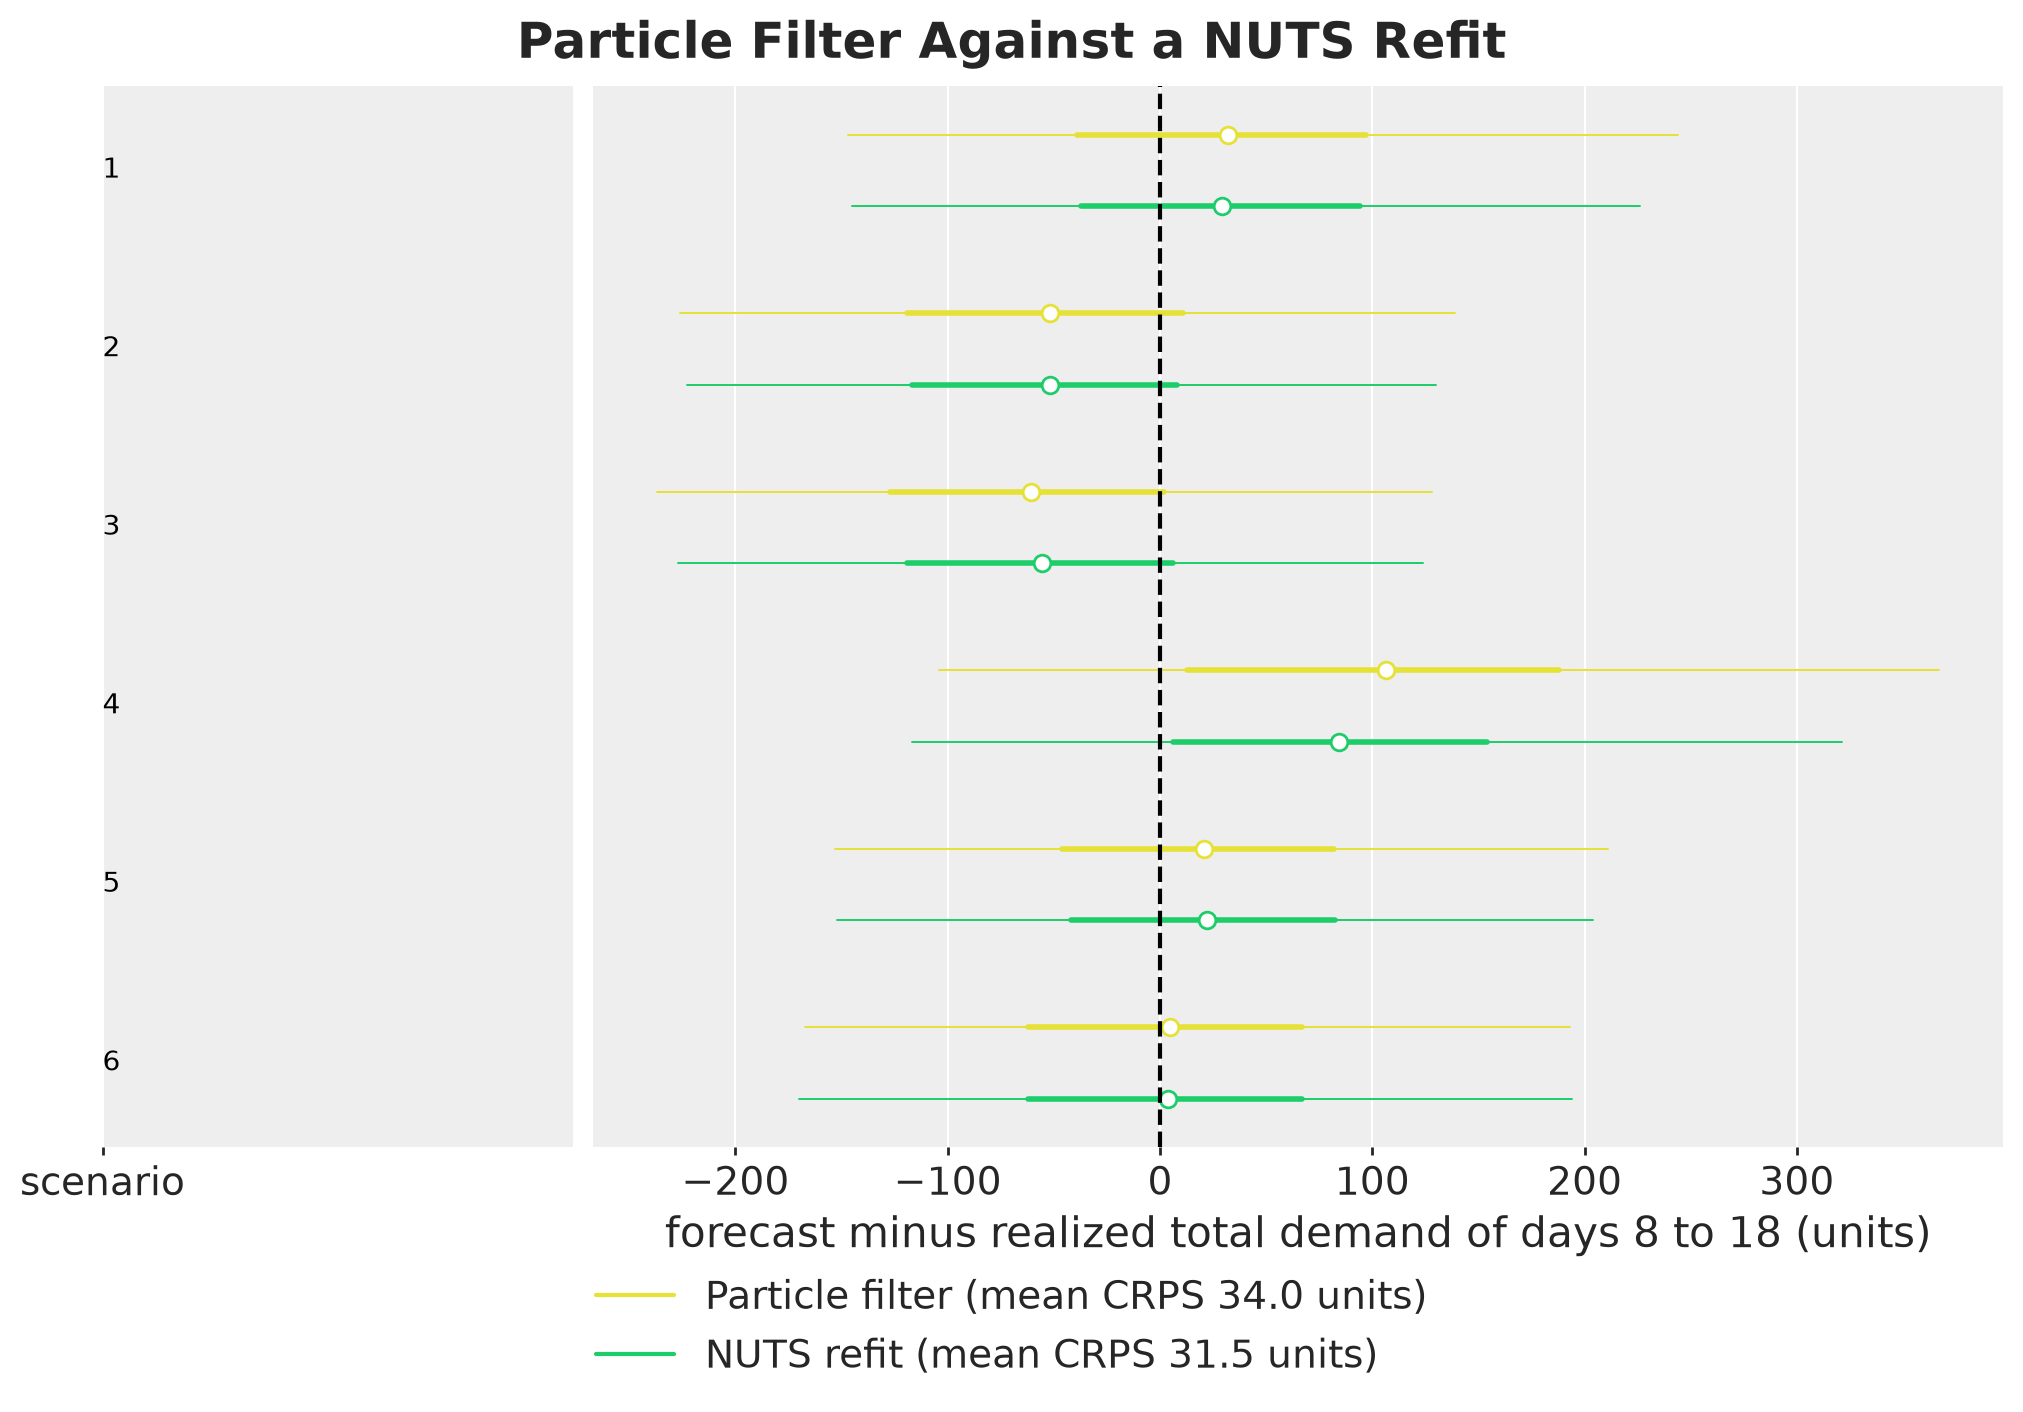

In [24]:
ERROR = "forecast minus realized demand"
error_draws = {
    name: xr.Dataset(
        {ERROR: (("sample", "scenario"), errors)},
        coords={"scenario": list(range(1, NUM_CHECK_SCENARIOS + 1))},
    )
    for name, errors in forecast_errors.items()
}
# the CRPS of the forecast error against zero, averaged over the scenarios
crps = {
    name: float(crps_empirical(errors, jnp.zeros(NUM_CHECK_SCENARIOS)).mean())
    for name, errors in forecast_errors.items()
}

pc = az.plot_forest(
    {
        f"{name} (mean CRPS {crps[name]:.1f} units)": dataset
        for name, dataset in error_draws.items()
    },
    sample_dims=["sample"],
    labels=["scenario"],
    color=["C6", "C7"],
    figure_kwargs={"figsize": (10, 7)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black", linestyle="--")
ax.set(
    xlabel=f"forecast minus realized total demand of days {NUM_OBSERVED + 1} "
    f"to {setup.max_days} (units)"
)
pc.add_legend("model", title="", loc="outside lower center", ncol=1)
pc.viz["figure"].item().suptitle(
    "Particle Filter Against a NUTS Refit", fontsize=18, fontweight="bold"
);

The dots are the means and the thick and thin bars the $50\%$ and $94\%$ intervals. In $5$ of the $6$ scenarios the means of the two forecasts are at most $5$ units apart. In the fourth scenario the mean of the filter is $22$ units higher than the mean of the refit.

The intervals of the filter are a little wider, and the mean CRPS is $34.0$ units for the particle filter and $31.5$ units for the NUTS refit. So on these scenarios the filter is a little worse than a refit and much cheaper, and we use it for the weekly forecast.

### Weekly Forecast

A policy does not need the whole forecast. Recall from the *Policies* section that on day $t$ the base-stock policy needs the newsvendor level $\hat{q}_t$ of the latest forecast: the $p / (p + h)$ quantile of the total demand $D_t + \dots + D_{t+L}$ of the days that the order of day $t$ has to cover. The neural policy also reads the mean of the same total. So for every day and lead time we keep these two numbers in a `Forecast` tuple.

The function `summarize_forecast` computes them from forecast paths, for every lead time and for a given quantile. We start with the forecast of day one. We draw $4{,}000$ paths of $21$ days from the initial belief over all $1{,}000$ particles, which is the same for every scenario, and take the quantile $p / (p + h) = 2 / 2.1 \approx 0.952$. The table shows the newsvendor levels of the first $3$ days.

In [25]:
class Forecast(NamedTuple):
    """Newsvendor level and mean of the total demand of the days t, ..., t + L."""

    level: Float[Array, "*batch"]
    mean: Float[Array, "*batch"]


MAX_LEAD_TIME = max(setup.lead_times)


def critical_fractile(config: InventoryConfig) -> float:
    """The quantile of the newsvendor problem, p / (p + h)."""
    return config.lost_sales_cost / (config.lost_sales_cost + config.holding_cost)


def summarize_forecast(
    paths: Float[Array, "paths days_ahead"], num_days: int, fractile: float
) -> Forecast:
    """Levels and means of the totals over the days t, ..., t + L of the paths.

    Both have shape `(num_days, lead_times)`, one column per lead time.
    """
    cumulative = jnp.cumsum(jnp.pad(paths, ((0, 0), (1, 0))), axis=1)
    first = jnp.arange(num_days)[:, None]
    last = first + jnp.asarray(setup.lead_times)[None, :]
    # total demand of the days t, ..., t + L: shape (paths, num_days, lead_times)
    totals = cumulative[:, last + 1] - cumulative[:, first]
    return Forecast(jnp.quantile(totals, fractile, axis=0), totals.mean(axis=0))


NUM_DAY_ONE_PATHS = 4_000
rng_key, key_day_one = random.split(rng_key)
paths_day_one = sample_scenarios(
    key_day_one,
    uniform_belief(particles_opt),
    0,
    setup.max_days + MAX_LEAD_TIME,
    NUM_DAY_ONE_PATHS,
)
forecast_day_one = summarize_forecast(
    paths_day_one, setup.max_days, critical_fractile(config)
)
pl.DataFrame(
    {
        "day": [1, 2, 3],
        **{
            f"L = {lead_time}": forecast_day_one.level[:3, k].tolist()
            for k, lead_time in enumerate(setup.lead_times)
        },
    }
)

day,L = 0,L = 1,L = 2,L = 3
i64,f64,f64,f64,f64
1,99.0,186.0,266.0,323.0
2,105.0,185.0,244.0,312.0
3,96.0,157.0,228.0,280.0


The level grows with the lead time, since the order of day $t$ covers $L + 1$ days.

Now we compute the weekly forecast of a path with the function `weekly_forecast`. Up to day $7$ it is the forecast of day one. On day $8$ the function `update_belief` filters the demand of the first week, and `weekly_forecast` draws $1{,}000$ paths from the updated belief and summarizes them. The paths cover days $8$ to $18$, the rest of the simulated days, plus $3$ days for the lead time of the last day.

Recall that a training or validation scenario comes from an optimization draw. In the first week its forecast is the forecast of day one, in which that draw is one particle of $1{,}000$, the same for every scenario. In the update, the belief of the scenario gives zero weight to that particle.

Let's compare the levels of the first test scenario at $L = 2$ with the levels of day one.

In [26]:
def update_belief(
    key: PRNGKeyArray, path: Float[Array, " days"], exclude: Int[Array, ""] | int
) -> FilterStep:
    """Filter the first week of a path, from a belief without the draw `exclude`."""
    first_week = path[: setup.update_after]
    return filter_days(key, first_week, uniform_belief(particles_opt, exclude), 0)


def weekly_forecast(
    key: PRNGKeyArray,
    path: Float[Array, " days"],
    exclude: Int[Array, ""] | int,
    fractile: float,
) -> Forecast:
    """The forecast of day one for the first week and the update for the other days."""
    key_filter, key_paths = random.split(key)
    belief = update_belief(key_filter, path, exclude).belief
    num_days = setup.max_days - setup.update_after
    paths = sample_scenarios(
        key_paths,
        belief,
        setup.update_after,
        num_days + MAX_LEAD_TIME,
        NUM_FORECAST_PATHS,
    )
    first_week = jax.tree.map(lambda leaf: leaf[: setup.update_after], forecast_day_one)
    return jax.tree.map(
        lambda before, after: jnp.concatenate([before, after]),
        first_week,
        summarize_forecast(paths, num_days, fractile),
    )


NUM_FORECAST_PATHS = 1_000
LEAD_TIME_DETAIL = 2  # the lead time that we look at in detail
lead_index_detail = setup.lead_times.index(LEAD_TIME_DETAIL)
days_example = jnp.array([0, 6, 7, 13, 14])
rng_key, key_example = random.split(rng_key)
forecast_example = weekly_forecast(
    key_example, path_example, particles_test.draw[0], critical_fractile(config)
)
pl.DataFrame(
    {
        "day": (days_example + 1).tolist(),
        "day-one level": forecast_day_one.level[
            days_example, lead_index_detail
        ].tolist(),
        "weekly level": forecast_example.level[
            days_example, lead_index_detail
        ].tolist(),
    }
)

day,day-one level,weekly level
i64,f64,f64
1,266.0,266.0
7,411.0,411.0
8,483.0,486.4
14,329.0,331.0
15,266.0,274.4


Up to day $7$ the two levels are the same, since the weekly forecast is the forecast of day one. From day $8$ on the levels of this scenario are a few units higher, by $3$ units on day $8$ and $8$ units on day $15$.

Here is an important observation. We observe the demand and not the sales, so the forecast of a day depends on the demand of the earlier days and not on the orders. The orders cannot change it.

So we can compute the weekly forecast of every scenario once, before we train any policy, and give it to the simulator as an input. We do this for the four scenario sets, in batches of $500$ scenarios. We keep the random key of every scenario, so that we can repeat the computation with the same random numbers.

In [27]:
%%time

forecast_scenarios = jax.jit(
    lambda keys, paths, draws: jax.lax.map(
        lambda inputs: weekly_forecast(*inputs, critical_fractile(config)),
        (keys, paths, draws),
        batch_size=500,
    )
)
forecast_keys: dict[ScenarioSet, UInt32[Array, "scenarios 2"]] = {}
forecast_by_set: dict[ScenarioSet, Forecast] = {}

for scenario_set, paths in demand_by_set.items():
    rng_key, key_set = random.split(rng_key)
    forecast_keys[scenario_set] = random.split(key_set, paths.shape[0])
    forecast_by_set[scenario_set] = forecast_scenarios(
        forecast_keys[scenario_set], paths, particles_by_set[scenario_set].draw
    )

forecast_by_set = jax.block_until_ready(forecast_by_set)
{str(name): forecast.level.shape for name, forecast in forecast_by_set.items()}

CPU times: user 16min 17s, sys: 10.1 s, total: 16min 27s
Wall time: 1min 18s


{'training set': (4000, 18, 4),
 'validation set': (1000, 18, 4),
 'forecast test set': (3000, 18, 4),
 'true process test set': (3000, 18, 4)}

Every set now has a level and a mean for every scenario, day and lead time. The next figure shows the weekly levels at $L = 2$ on the two test sets: the median and the $50\%$ and $94\%$ intervals over the scenarios, with the levels of day one as a black line.

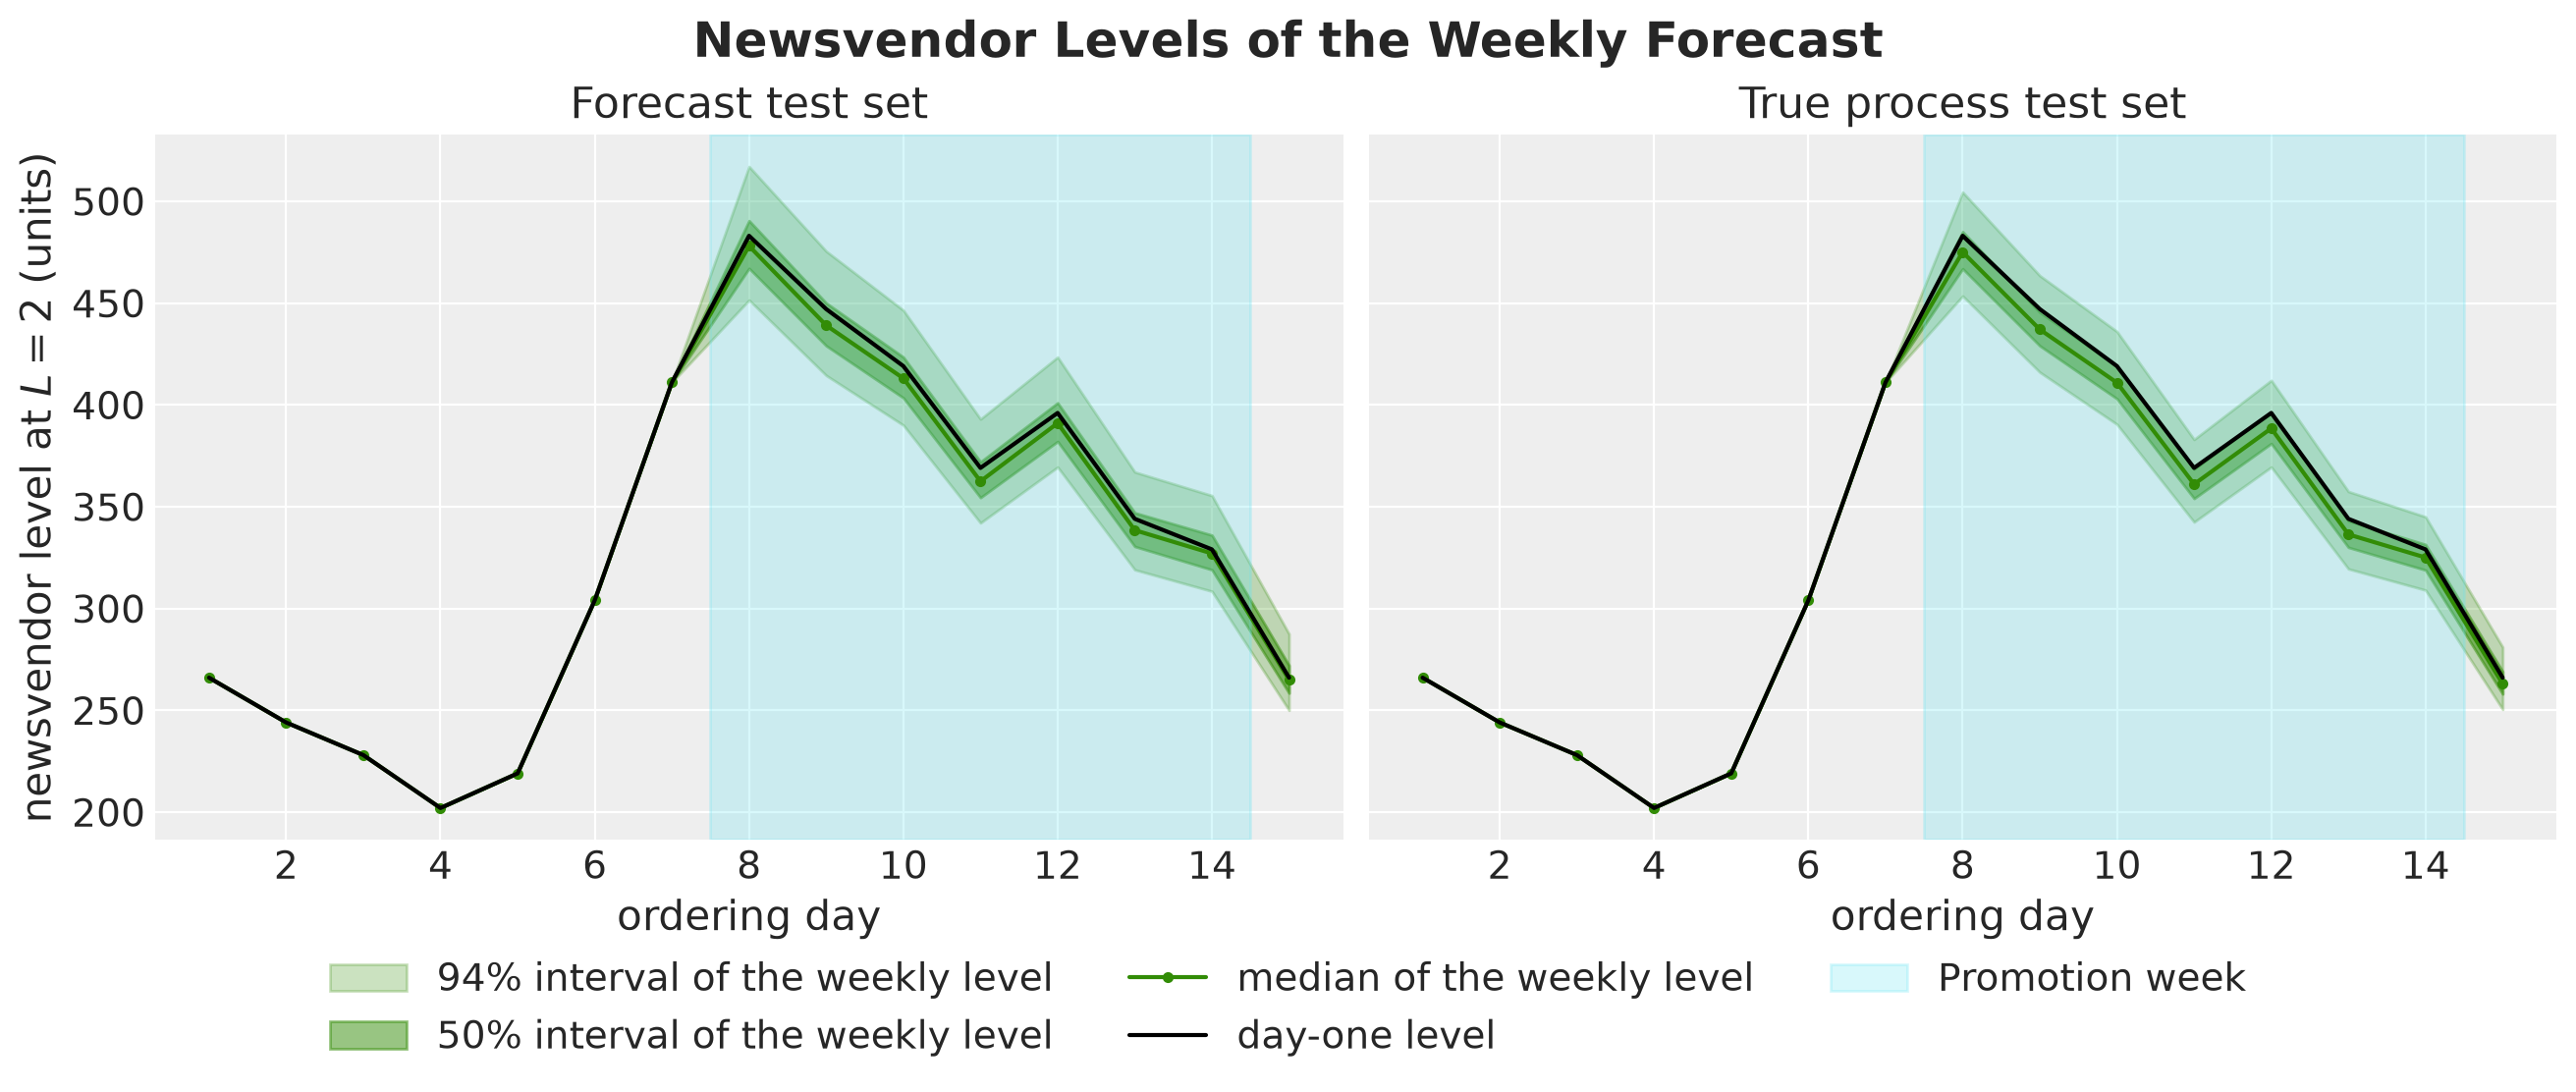

In [28]:
fig, axes = plt.subplots(
    ncols=2, figsize=(13, 5.5), sharex=True, sharey=True, layout="constrained"
)
ordering_days = jnp.arange(1, setup.horizon + 1)

for ax, scenario_set in zip(axes, TEST_SETS, strict=True):
    levels = forecast_by_set[scenario_set].level[:, : setup.horizon, lead_index_detail]

    for prob, alpha in [(CI_PROB, 0.25), (0.5, 0.5)]:
        ax.fill_between(
            ordering_days,
            jnp.quantile(levels, (1 - prob) / 2, axis=0),
            jnp.quantile(levels, (1 + prob) / 2, axis=0),
            color="C2",
            alpha=alpha,
            label=f"{prob:.0%} interval of the weekly level",
        )

    ax.plot(
        ordering_days,
        jnp.median(levels, axis=0),
        "o-",
        markersize=3,
        color="C2",
        label="median of the weekly level",
    )
    ax.plot(
        ordering_days,
        forecast_day_one.level[: setup.horizon, lead_index_detail],
        color="black",
        label="day-one level",
    )
    shade_promotion(ax)
    ax.set(title=scenario_set.capitalize(), xlabel="ordering day")

axes[0].set(ylabel=f"newsvendor level at $L = {LEAD_TIME_DETAIL}$ (units)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    "Newsvendor Levels of the Weekly Forecast", fontsize=18, fontweight="bold"
);

Up to day $7$ there is no band, since every scenario uses the forecast of day one. From day $8$ on the levels spread around the day-one levels, and the $94\%$ interval on day $8$ is about $66$ units wide on the forecast test set. The median is $1$ to $8$ units below the day-one level.

This is what we expect when an update narrows the forecast. The first week tells us part of the parameters and the level of a path, so the updated forecast is narrower than the forecast of day one, and its $95.2\%$ quantile is lower. On the true process test set the levels drop more, since the truth is below the center of the forecast.

Next, we check that the forecast of a day does not use the demand of that day or of a later day. We add $50$ units to the demand of every validation scenario from day $8$ on, the day of the update, and compute the weekly forecast again with the same keys. The update uses the first week only, so no level should change.

As a control, we also add $50$ units to the demand of day $7$ alone. Then the level of every day from day $8$ on should change in some scenarios, and the levels of the first week should not change.

In [29]:
CHANGED_FROM = setup.update_after  # index of the first day whose demand we change

demand_val = demand_by_set[ScenarioSet.VALIDATION]
level_original = forecast_by_set[ScenarioSet.VALIDATION].level
forecast_changed, forecast_day_7 = (
    forecast_scenarios(forecast_keys[ScenarioSet.VALIDATION], paths, particles_val.draw)
    for paths in (
        demand_val.at[:, CHANGED_FROM:].add(50.0),
        demand_val.at[:, CHANGED_FROM - 1].add(50.0),
    )
)
assert jnp.array_equal(forecast_changed.level, level_original)
assert jnp.array_equal(
    forecast_day_7.level[:, :CHANGED_FROM], level_original[:, :CHANGED_FROM]
)
# every day from the update on changes in at least one scenario
assert (
    (forecast_day_7.level[:, CHANGED_FROM:] != level_original[:, CHANGED_FROM:])
    .any(axis=0)
    .all()
)

The three assertions pass: the forecast of a day only depends on the demand before the day of its update.

Finally, the filter has to keep enough particles. For every scenario of the two test sets we filter the first week again with the keys of the forecast, and look at the effective sample size of every day of the week and at the number of distinct posterior draws among the particles on day $8$, which the function `count_distinct_draws` counts. The table shows the averages over the scenarios.

In [30]:
def count_distinct_draws(belief: Belief) -> Int[Array, ""]:
    """Number of distinct posterior draws among the particles."""
    draws = jnp.sort(belief.particles.draw)
    return (jnp.diff(draws) > 0).sum() + 1


def filter_diagnostics(
    key: PRNGKeyArray, path: Float[Array, " days"], exclude: Int[Array, ""] | int
) -> tuple[Float[Array, " week"], Int[Array, ""]]:
    """Effective sample sizes of the first week and distinct draws on day 8."""
    # the key of the filter inside `weekly_forecast`
    update = update_belief(random.split(key)[0], path, exclude)
    return update.effective_sample_size, count_distinct_draws(update.belief)


diagnostics = {
    test_set: jax.jit(
        lambda keys, paths, draws: jax.lax.map(
            lambda inputs: filter_diagnostics(*inputs),
            (keys, paths, draws),
            batch_size=500,
        )
    )(
        forecast_keys[test_set],
        demand_by_set[test_set],
        particles_by_set[test_set].draw,
    )
    for test_set in TEST_SETS
}
pl.DataFrame(
    {
        "test set": [str(name) for name in diagnostics],
        "lowest mean effective sample size": [
            float(ess.mean(axis=0).min()) for ess, _ in diagnostics.values()
        ],
        "mean distinct draws on day 8": [
            float(distinct.mean()) for _, distinct in diagnostics.values()
        ],
        "share of scenarios with a resampling": [
            float((distinct < particles_opt.draw.shape[0]).mean())
            for _, distinct in diagnostics.values()
        ],
        "fewest distinct draws": [
            int(distinct.min()) for _, distinct in diagnostics.values()
        ],
    }
)

test set,lowest mean effective sample size,mean distinct draws on day 8,share of scenarios with a resampling,fewest distinct draws
str,f64,f64,f64,i64
"""forecast test set""",746.6,914.0,0.2,232
"""true process test set""",753.9,948.2,0.1,405


On both test sets the mean effective sample size stays above $740$ on every day of the first week, and the particles of day $8$ come from more than $910$ distinct posterior draws on average. The filter resamples in about a fifth of the forecast test scenarios, and the lowest count is $232$ distinct draws. So one week of updates keeps enough particles.

Now that every scenario has its weekly forecast, we can build the simulator in which the policies place their orders.

## Inventory Simulator

The simulator of the first post took a vector of orders and a demand path and returned the loss. The new simulator takes a policy and its parameters in place of the orders, and the forecast of every day as a second input. It is again a `jax.lax.scan` over the days, and every iteration runs the five steps of a day from the *Lead Time* section.

We start with the state and the observation.

- **State.** The scan carries the `InventoryState` from one day to the next: the stock on hand, the pipeline as a vector of length $L$, and the last $K$ demands. The function `initial_state` returns the state before day one, the same for every policy: the initial stock, the initial pipeline and the demand of the last $7$ days of the history.
- **Observation.** The function `observe` receives the order that arrives and builds the `Observation` from the state, the day and the forecast of the day. It does not take the demand as an argument, so no policy can see the demand of the day on which it orders. A policy that reads no forecast gets `None`.

Let's look at the observation of day one for $L = 2$, without a forecast.

In [31]:
class InventoryState(NamedTuple):
    """What the simulator carries from one day to the next."""

    inventory: Float[Array, ""]  # stock on hand at the end of the day
    pipeline: Float[Array, " lead_time"]  # orders on their way, the first arrives next
    demand_history: Float[Array, " window"]  # the last demands, most recent last


class Observation(NamedTuple):
    """What a policy sees on a day, before the demand of that day."""

    day: Int[Array, ""]
    inventory: Float[Array, ""]  # stock on hand after the arrival of the day
    pipeline: Float[Array, " in_transit"]  # orders that arrive on later days
    position: Float[Array, ""]  # stock on hand plus pipeline
    demand_history: Float[Array, " window"]
    forecast: Forecast | None  # the latest forecast of the days t, ..., t + L


def initial_state(lead_time: int) -> InventoryState:
    """The state before day one, the same for every policy."""
    return InventoryState(
        inventory=jnp.asarray(config.initial_inventory),
        # each order in the pipeline is the median demand of the day on which it arrives
        pipeline=jnp.median(demand_by_set[ScenarioSet.TRAINING][:, :lead_time], axis=0),
        demand_history=data[-setup.history_window :, 0].astype(jnp.float32),
    )


def observe(
    state: InventoryState,
    day: Int[Array, ""],
    forecast: Forecast | None,
    lead_time: int,
) -> Observation:
    """Receive the order that arrives today and collect what a policy may see."""
    if lead_time > 0:
        inventory = state.inventory + state.pipeline[0]
        in_transit = state.pipeline[1:]
    else:
        inventory, in_transit = state.inventory, state.pipeline

    return Observation(
        day=day,
        inventory=inventory,
        pipeline=in_transit,
        position=inventory + in_transit.sum(),
        demand_history=state.demand_history,
        forecast=forecast,
    )


observe(initial_state(LEAD_TIME_DETAIL), jnp.asarray(0), None, LEAD_TIME_DETAIL)

Observation(day=Array(0, dtype=int32, weak_type=True), inventory=Array(118., dtype=float32), pipeline=Array([73.], dtype=float32), position=Array(191., dtype=float32), demand_history=Array([57., 56., 95., 48., 64., 48., 59.], dtype=float32), forecast=None)

On day one the first order of the initial pipeline has arrived, so the stock on hand is the initial stock of $50$ units plus that order. The second order of the initial pipeline arrives on day two, and the inventory position adds it.

Next, the function `inventory_step` asks the policy for the order, appends it to the pipeline, sells, and charges the cost if the day is in the cost window. It returns a `DayResult`: the state at the end of the day and the record of the day, a `Simulation` with the cost, the order, the stock and the lost sales.

The simplest policy is the fixed plan. Its order on day $t$ is the entry $\theta_t$ of a vector of orders, whatever the observation. As a plan we take the mean demand of the training scenarios on the day on which each order arrives, which the function `mean_demand_plan` computes. Let's follow the first scenario of the training set through its first five days at $L = 2$.

In [32]:
class Simulation(NamedTuple):
    """Daily cost, orders, stock and lost sales of a policy on demand paths."""

    daily_cost: Float[Array, "*scenarios days"]
    orders: Float[Array, "*scenarios days"]
    inventory: Float[Array, "*scenarios days"]
    lost_sales: Float[Array, "*scenarios days"]

    @property
    def loss(self) -> Float[Array, "*scenarios"]:
        """Sum of the daily costs, which are zero outside the cost window."""
        return self.daily_cost.sum(axis=-1)


class DayResult(NamedTuple):
    """The state at the end of a day and the record of that day."""

    state: InventoryState
    record: Simulation


type Policy = Callable[[PyTree, Observation], Float[Array, ""]]


def inventory_step(
    policy: Policy,
    params: PyTree,
    state: InventoryState,
    demand_t: Float[Array, ""],
    forecast_t: Forecast | None,
    day: Int[Array, ""],
    config: InventoryConfig,
    lead_time: int,
) -> DayResult:
    """One day of the inventory dynamics: receive, observe, order, sell, pay."""
    observation = observe(state, day, forecast_t, lead_time)
    # no orders after day H
    order = jnp.where(day < setup.horizon, policy(params, observation), 0.0)

    if lead_time > 0:
        inventory = observation.inventory
        pipeline = jnp.concatenate([observation.pipeline, order[None]])
    else:
        # without a lead time the order is on the shelf before the demand
        inventory = observation.inventory + order
        pipeline = observation.pipeline

    sales = jnp.minimum(inventory, demand_t)
    lost_sales = demand_t - sales
    inventory = inventory - sales
    in_cost_window = (day >= lead_time) & (day < setup.horizon + lead_time)
    daily_cost = jnp.where(
        in_cost_window,
        config.holding_cost * inventory + config.lost_sales_cost * lost_sales,
        0.0,
    )
    demand_history = jnp.concatenate([state.demand_history[1:], demand_t[None]])
    return DayResult(
        state=InventoryState(inventory, pipeline, demand_history),
        record=Simulation(daily_cost, order, inventory, lost_sales),
    )


def fixed_plan(params: Float[Array, " horizon"], obs: Observation) -> Float[Array, ""]:
    """The order of a day is one number per ordering day."""
    return params[obs.day]


def mean_demand_plan(lead_time: int) -> Float[Array, " horizon"]:
    """Mean demand of the training scenarios on the day on which each order arrives."""
    demand = demand_by_set[ScenarioSet.TRAINING]
    return demand[:, lead_time : lead_time + setup.horizon].mean(axis=0)


NUM_DEMO_DAYS = 5
state = initial_state(LEAD_TIME_DETAIL)
plan = mean_demand_plan(LEAD_TIME_DETAIL)
path = demand_by_set[ScenarioSet.TRAINING][0]
rows = []

for day in range(NUM_DEMO_DAYS):
    # the order that arrives at the start of the day
    arrival = state.pipeline[0]
    state, record = inventory_step(
        fixed_plan,
        plan,
        state,
        path[day],
        None,
        jnp.asarray(day),
        config,
        LEAD_TIME_DETAIL,
    )
    rows.append(
        {
            "day": day + 1,
            "arrival": float(arrival),
            "order": float(record.orders),
            "demand": float(path[day]),
            "lost sales": float(record.lost_sales),
            "stock at the end": float(record.inventory),
            "cost": float(record.daily_cost),
        }
    )

pl.DataFrame(rows)

day,arrival,order,demand,lost sales,stock at the end,cost
i64,f64,f64,f64,f64,f64,f64
1,68.0,67.4,74.0,0.0,44.0,0.0
2,73.0,51.8,71.0,0.0,46.0,0.0
3,67.4,61.4,76.0,0.0,37.4,3.7
4,51.8,45.4,64.0,0.0,25.2,2.5
5,61.4,64.6,51.0,0.0,35.5,3.6


The order of day $1$, $67.4$ units, arrives on day $3$, and the order of day $2$ arrives on day $4$. On days $1$ and $2$ the arrivals come from the initial pipeline, and the cost is zero because these days are not in the cost window. From day $3$ on we pay the holding cost of $0.1$ per unit left on the shelf at the end of the day. In this scenario no demand is lost in the first five days.

Next, the function `simulate` scans `inventory_step` over a demand path, and `simulate_scenarios` vectorizes it over the scenarios with `jax.vmap`. Both take a `Scenarios` tuple: the demand paths and the forecast of every day, or `None`.

The function `scenarios_for` builds this tuple for a scenario set, a lead time and the forecast that a policy reads, which the `ForecastSource` enumeration names: none, the forecast of day one or the weekly forecast. It keeps the $H + L$ days that we simulate for the lead time, and the forecast of that lead time.

The lead time changes the shape of the pipeline, so it is a static argument and JAX compiles the simulator once per lead time. The costs are ordinary arguments, so we can change them later without a new compilation.

We run the mean demand plan of every lead time on the training set and check the result below.

In [33]:
class ForecastSource(StrEnum):
    """The forecast that a policy reads."""

    NONE = "no forecast"
    DAY_ONE = "day-one forecast"
    WEEKLY = "weekly forecast"


class Scenarios(NamedTuple):
    """Demand paths and the forecast of every day of every path."""

    demand: Float[Array, "*scenarios days"]
    forecast: Forecast | None


def scenarios_for(
    scenario_set: ScenarioSet,
    lead_time: int,
    source: ForecastSource,
    day_one: Forecast = forecast_day_one,
) -> Scenarios:
    """The days that we simulate for a lead time, with the forecast of a source."""
    num_days = setup.horizon + lead_time
    demand = demand_by_set[scenario_set][:, :num_days]
    column = setup.lead_times.index(lead_time)

    if source == ForecastSource.DAY_ONE:
        # the same forecast for every scenario
        forecast = jax.tree.map(
            lambda leaf: jnp.broadcast_to(
                leaf[:num_days, column], (demand.shape[0], num_days)
            ),
            day_one,
        )
    elif source == ForecastSource.WEEKLY:
        forecast = jax.tree.map(
            lambda leaf: leaf[:, :num_days, column], forecast_by_set[scenario_set]
        )
    else:
        forecast = None

    return Scenarios(demand, forecast)


def simulate(
    policy: Policy,
    params: PyTree,
    scenario: Scenarios,
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
) -> Simulation:
    """Run a policy against one demand path from day one on."""

    def step(
        state: InventoryState,
        inputs: tuple[Float[Array, ""], Forecast | None, Int[Array, ""]],
    ) -> tuple[InventoryState, Simulation]:
        demand_t, forecast_t, day = inputs
        # `jax.lax.scan` needs a pair: the carry and the output of the day
        day_result = inventory_step(
            policy, params, state, demand_t, forecast_t, day, config, lead_time
        )
        return day_result.state, day_result.record

    days = jnp.arange(scenario.demand.shape[0])
    _, simulation = jax.lax.scan(
        step, state, (scenario.demand, scenario.forecast, days)
    )
    return simulation


def simulate_scenarios(
    policy: Policy,
    params: PyTree,
    scenarios: Scenarios,
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
) -> Simulation:
    """Run a policy against a batch of demand paths from the same initial state."""
    return jax.vmap(
        lambda scenario: simulate(policy, params, scenario, state, config, lead_time)
    )(scenarios)


simulate_scenarios_jit = jax.jit(
    simulate_scenarios, static_argnames=("policy", "lead_time")
)

simulations_mean_plan = {
    lead_time: simulate_scenarios_jit(
        fixed_plan,
        mean_demand_plan(lead_time),
        scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.NONE),
        initial_state(lead_time),
        config,
        lead_time,
    )
    for lead_time in setup.lead_times
}
{lead_time: sim.loss.shape for lead_time, sim in simulations_mean_plan.items()}

{0: (4000,), 1: (4000,), 2: (4000,), 3: (4000,)}

Every lead time has one loss for each of the $4{,}000$ training scenarios. Given the orders that come out of the scan, we can write the dynamics of a whole path at once and compare them with the scan:

- **Arrivals.** The order that arrives on day $t$ is the initial pipeline for $t \leq L$ and the order of day $t - L$ afterwards.
- **Stock and lost sales.** The stock available on day $t$ is $y_t = I_{t-1}$ plus the arrival, and the scan has to return $I_t = (y_t - D_t)^{+}$ and $U_t = (D_t - y_t)^{+}$.

In [34]:
for lead_time, simulation in simulations_mean_plan.items():
    demand = scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.NONE).demand
    state = initial_state(lead_time)
    num_scenarios, num_days = demand.shape

    # arrivals: the initial pipeline, then the orders placed `lead_time` days before
    arrivals = jnp.concatenate(
        [
            jnp.broadcast_to(state.pipeline, (num_scenarios, lead_time)),
            simulation.orders,
        ],
        axis=1,
    )[:, :num_days]

    # stock available: the stock at the end of the day before plus the arrival
    stock_before = jnp.concatenate(
        [
            jnp.full((num_scenarios, 1), config.initial_inventory),
            simulation.inventory[:, :-1],
        ],
        axis=1,
    )
    available = stock_before + arrivals

    assert jnp.allclose(
        simulation.inventory, jnp.maximum(available - demand, 0.0), atol=1e-3
    )
    assert jnp.allclose(
        simulation.lost_sales, jnp.maximum(demand - available, 0.0), atol=1e-3
    )

The stock and the lost sales match for every lead time. Two more checks concern the days:

- **Cost window.** The daily cost is $h \, I_t + p \, U_t$ on the days $L + 1, \dots, H + L$ and zero on the others.
- **Orders.** There are no orders after day $H$.

In [35]:
for lead_time, simulation in simulations_mean_plan.items():
    # the days L + 1, ..., H + L are the indices L, ..., H + L - 1
    days = jnp.arange(setup.horizon + lead_time)
    in_cost_window = (days >= lead_time) & (days < setup.horizon + lead_time)
    daily_cost = (
        config.holding_cost * simulation.inventory
        + config.lost_sales_cost * simulation.lost_sales
    )
    assert jnp.allclose(
        simulation.daily_cost, jnp.where(in_cost_window, daily_cost, 0.0), atol=1e-3
    )
    assert (simulation.orders[:, setup.horizon :] == 0.0).all()

The four checks pass for every lead time, which is good!

## Policy Training

We train the fixed plan, the base-stock offsets and the neural policy with one function. First, we need its objective. As in the first post, we summarize the loss of a policy over the scenarios with two quantities:

- **Expected loss.** The mean of the loss over the scenarios, the estimate of $J(\theta)$.
- **Conditional value at risk (CVaR).** The mean of the worst $\alpha = 5\%$ of the scenario losses, the tail average. With $N$ scenarios it is the mean of the $k = \alpha N$ largest losses.

As an example, we compute both for the mean demand plans of the simulator checks. The training of the fixed plan starts from these plans.

In [36]:
ALPHA = 0.05  # tail probability of the CVaR


def tail_size(num_scenarios: int) -> int:
    """The integer k = ALPHA * N, static because top_k needs a Python integer."""
    return max(1, round(ALPHA * num_scenarios))


def cvar(losses: Float[Array, " scenarios"]) -> Float[Array, ""]:
    """Mean of the k largest losses."""
    worst, _ = jax.lax.top_k(losses, tail_size(losses.shape[0]))
    return worst.mean()


pl.DataFrame(
    [
        {
            "lead time": lead_time,
            "expected loss": float(simulation.loss.mean()),
            f"CVaR (worst {ALPHA:.0%})": float(cvar(simulation.loss)),
        }
        for lead_time, simulation in simulations_mean_plan.items()
    ]
)

lead time,expected loss,CVaR (worst 5%)
i64,f64,f64
0,156.9,458.9
1,164.5,478.1
2,171.5,496.6
3,176.8,511.1


The mean demand plans have an expected loss between $157$ and $177$ and a CVaR between $459$ and $511$. Recall that the cost window moves with the lead time, so we do not compare the rows with each other.

Before we train, we set up the bookkeeping. The `PolicyName` enumeration lists the names that we use in the figures, including the policies of the next sections. As the plans of the first post, every policy gets one color of the default color cycle, `C0` to `C4`, and `C5` shades the promotion week.

A `TrainedPolicy` holds a policy, its parameters and the forecast that it reads, and the function `evaluate` simulates it on a scenario set with that forecast. We keep the trained policies in a dictionary indexed by the lead time and the name of the policy. As a check, `evaluate` gives the losses of the mean demand plans of the table above.

In [37]:
class PolicyName(StrEnum):
    """Names of the ways of placing the orders."""

    FIXED_PLAN = "Fixed plan"
    DAY_ONE = "Base-stock (day-one forecast)"
    WEEKLY = "Base-stock (weekly forecast)"
    BASE_STOCK = "Base-stock (trained)"
    NEURAL = "Neural"


# one color per policy in every figure that follows
POLICY_COLORS = {
    PolicyName.FIXED_PLAN: "C0",
    PolicyName.DAY_ONE: "C1",
    PolicyName.WEEKLY: "C2",
    PolicyName.BASE_STOCK: "C3",
    PolicyName.NEURAL: "C4",
}


class TrainedPolicy(NamedTuple):
    """A policy with its parameters and the forecast that it reads."""

    policy: Policy
    params: PyTree
    source: ForecastSource


def evaluate(
    trained: TrainedPolicy,
    scenario_set: ScenarioSet,
    lead_time: int,
    config: InventoryConfig = config,
) -> Simulation:
    """Simulate a trained policy on a scenario set with the forecast that it reads."""
    return simulate_scenarios_jit(
        trained.policy,
        trained.params,
        scenarios_for(scenario_set, lead_time, trained.source),
        initial_state(lead_time),
        config,
        lead_time,
    )


for lead_time, simulation in simulations_mean_plan.items():
    mean_plan = TrainedPolicy(
        fixed_plan, mean_demand_plan(lead_time), ForecastSource.NONE
    )
    assert jnp.allclose(
        evaluate(mean_plan, ScenarioSet.TRAINING, lead_time).loss, simulation.loss
    )

The objective of the training is the expected loss plus a **tail weight** $\lambda \geq 0$ times the CVaR,

$$
\min_\theta \; J(\theta) + \lambda \, \text{CVaR}_\alpha(C(\theta, D)).
$$

We train with $\lambda = 0$, the expected loss, everywhere except in the *Tail Risk* section.

The function `train` runs Adam from [Optax](https://optax.readthedocs.io/) on this objective, and the gradient with respect to the parameters of the policy comes from `jax.grad` through the simulator. Here are four remarks about this function:

- **Batches.** The fixed plan and the base-stock offsets have $15$ parameters each, and we train them on the full training set with the learning rate and the number of steps of the first post. The neural policy trains on random batches of scenarios.
- **Validation.** Every $100$ steps we evaluate the objective on a second set of scenarios, and we return the parameters with the lowest value on that set. For the neural policy this is the validation set, and for the other two we pass the training set again. The initial parameters are the first candidate, so the training cannot return a policy that is worse on that set than its starting point. The scan carries the current and the best parameters in a `TrainState`.
- **Gradient clipping.** We clip the norm of the gradient at $10$, a guard that the solver of the first post did not have.
- **Projection.** The orders of the fixed plan cannot be negative, so after every step we clip them at zero. The base-stock and neural policies clip the order inside the policy.

Is Adam a good choice here? Adam rescales the step of every parameter by a running estimate of the size of its gradient. The [cannibalization post](https://juanitorduz.github.io/forecast_to_decision_cannibalization/) uses plain gradient steps instead, because a store capacity couples the orders of the products, and there a rescaled step followed by the projection onto the capacity set can stop at a plan that is not optimal.

Our problem has no capacity. The projection of the fixed plan is the clip at zero, which acts on every order separately. So a rescaled step followed by the clip has the same fixed points as a plain step followed by the clip: the plans in which every positive order has a zero (sub)gradient and no zero order has a negative one. A positive factor on each coordinate of the step does not change these conditions, and neither does the clip of the gradient norm, which multiplies the whole gradient by one positive number. The loss is piecewise linear in the plan, so the gradient is rarely exactly zero, and in practice the run ends where the cosine schedule brings the step size to zero.

The offsets and the network have no projection at all, and the network trains on random batches, where Adam is the usual choice.

The function is pure, so we can vectorize it over random keys with `jax.vmap` to train from several seeds at once.

In [38]:
def objective(
    losses: Float[Array, " scenarios"], tail_weight: ScalarLike
) -> Float[Array, ""]:
    """Expected loss plus the tail weight times the CVaR of the loss."""
    return losses.mean() + tail_weight * cvar(losses)


class TrainConfig(NamedTuple):
    """Settings of one training run."""

    num_steps: int
    batch_size: int  # a value at or above the number of scenarios means the full batch
    learning_rate: float
    eval_every: int = 100  # steps between two evaluations on the validation set


class TrainResult(NamedTuple):
    """Best parameters on the validation set and the validation objective."""

    params: PyTree
    validation: Float[Array, "*seeds evaluations"]  # the first value is at the start


class TrainState(NamedTuple):
    """What the training carries from one step to the next."""

    params: PyTree
    opt_state: optax.OptState
    best_params: PyTree  # the parameters with the lowest validation objective so far
    best_value: Float[Array, ""]


def train(
    key: PRNGKeyArray,
    policy: Policy,
    params: PyTree,
    scenarios_train: Scenarios,
    scenarios_val: Scenarios,
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
    tail_weight: ScalarLike,
    train_config: TrainConfig,
    project: Callable[[PyTree], PyTree] | None = None,
) -> TrainResult:
    """Adam on the objective through the simulator, best parameters on validation."""
    schedule = optax.cosine_decay_schedule(
        train_config.learning_rate, train_config.num_steps
    )
    # the clip bounds the size of a step when a batch has a large gradient
    optimizer = optax.chain(optax.clip_by_global_norm(10.0), optax.adam(schedule))
    num_train = scenarios_train.demand.shape[0]

    def loss(params: PyTree, scenarios: Scenarios) -> Float[Array, ""]:
        simulation = simulate_scenarios(
            policy, params, scenarios, state, config, lead_time
        )
        return objective(simulation.loss, tail_weight)

    def step(carry: TrainState, key_step: PRNGKeyArray) -> tuple[TrainState, None]:
        """One step of Adam on a batch, followed by the projection."""
        if train_config.batch_size < num_train:
            index = random.choice(
                key_step, num_train, (train_config.batch_size,), replace=False
            )
            batch = jax.tree.map(lambda leaf: leaf[index], scenarios_train)
        else:
            batch = scenarios_train

        grads = jax.grad(loss)(carry.params, batch)
        updates, opt_state = optimizer.update(grads, carry.opt_state, carry.params)
        params = optax.apply_updates(carry.params, updates)

        if project is not None:
            params = project(params)

        return carry._replace(params=params, opt_state=opt_state), None

    def train_round(
        carry: TrainState, keys: UInt32[Array, "steps 2"]
    ) -> tuple[TrainState, Float[Array, ""]]:
        """`eval_every` steps, then one evaluation on the validation set."""
        carry, _ = jax.lax.scan(step, carry, keys)
        value = loss(carry.params, scenarios_val)
        improved = value < carry.best_value
        best_params = jax.tree.map(
            lambda new, old: jnp.where(improved, new, old),
            carry.params,
            carry.best_params,
        )
        carry = carry._replace(
            best_params=best_params, best_value=jnp.minimum(value, carry.best_value)
        )
        return carry, value

    num_evaluations = train_config.num_steps // train_config.eval_every
    keys = random.split(key, (num_evaluations, train_config.eval_every))
    value_start = loss(params, scenarios_val)
    carry = TrainState(params, optimizer.init(params), params, value_start)
    carry, values = jax.lax.scan(train_round, carry, keys)
    return TrainResult(carry.best_params, jnp.concatenate([value_start[None], values]))


train_jit = jax.jit(
    train, static_argnames=("policy", "lead_time", "train_config", "project")
)
# the settings of the first post: the full batch, 1,500 steps and a learning rate of 1
FULL_BATCH = TrainConfig(
    num_steps=1_500,
    batch_size=demand_by_set[ScenarioSet.TRAINING].shape[0],
    learning_rate=1.0,
)
NO_KEY = random.PRNGKey(0)  # a full batch uses no random numbers

### Fixed Plan

Now we train the fixed plan for every lead time on the training set, from the mean demand plans. For $L = 0$ this is the expected cost plan of the first post. The table compares the expected loss on the training set before and after the training.

In [39]:
def clip_at_zero(params: Float[Array, " horizon"]) -> Float[Array, " horizon"]:
    """Projection of a plan onto the non-negative orders."""
    return jnp.maximum(params, 0.0)


def train_fixed_plan(
    lead_time: int, config: InventoryConfig, tail_weight: float = 0.0
) -> TrainedPolicy:
    """Train the fixed plan from the mean demand plan."""
    scenarios = scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.NONE)
    result = train_jit(
        NO_KEY,
        fixed_plan,
        mean_demand_plan(lead_time),
        scenarios,
        scenarios,  # 15 parameters: we keep the best iterate on the training set
        initial_state(lead_time),
        config,
        lead_time=lead_time,
        tail_weight=tail_weight,
        train_config=FULL_BATCH,
        project=clip_at_zero,
    )
    return TrainedPolicy(fixed_plan, result.params, ForecastSource.NONE)


policies: dict[tuple[int, PolicyName], TrainedPolicy] = {
    (lead_time, PolicyName.FIXED_PLAN): train_fixed_plan(lead_time, config)
    for lead_time in setup.lead_times
}


pl.DataFrame(
    [
        {
            "lead time": lead_time,
            "mean demand plan": float(simulations_mean_plan[lead_time].loss.mean()),
            "trained plan": float(
                evaluate(
                    policies[lead_time, PolicyName.FIXED_PLAN],
                    ScenarioSet.TRAINING,
                    lead_time,
                ).loss.mean()
            ),
        }
        for lead_time in setup.lead_times
    ]
)

lead time,mean demand plan,trained plan
i64,f64,f64
0,156.9,143.9
1,164.5,154.7
2,171.5,164.2
3,176.8,171.9


The training lowers the expected loss of the plans by $13$ for $L = 0$ and by $5$ for $L = 3$.

### Base-Stock Policy

The three base-stock policies share one function, `base_stock`: order up to the newsvendor level of the forecast in the observation plus the offset of the day. They differ in the forecast that the observation carries and in the offsets:

- **Day-one forecast.** The levels of the forecast of day one and zero offsets.
- **Weekly forecast.** The levels of the latest weekly forecast and zero offsets.
- **Trained.** The levels of the latest weekly forecast and offsets that we train from zero, with the same settings as the fixed plan.

The first two need no training. The assertion checks that with zero offsets every ordering day has a positive order in more than half of the training scenarios, so every offset has a gradient when the training starts.

In [40]:
def base_stock(params: Float[Array, " horizon"], obs: Observation) -> Float[Array, ""]:
    """Order up to the newsvendor level plus the offset of the day."""
    return jax.nn.relu(obs.forecast.level + params[obs.day] - obs.position)


def train_base_stock(
    lead_time: int,
    config: InventoryConfig,
    source: ForecastSource = ForecastSource.WEEKLY,
    tail_weight: float = 0.0,
) -> TrainedPolicy:
    """Train the offsets of the base-stock policy from zero."""
    scenarios = scenarios_for(ScenarioSet.TRAINING, lead_time, source)
    result = train_jit(
        NO_KEY,
        base_stock,
        jnp.zeros(setup.horizon),
        scenarios,
        scenarios,  # 15 parameters: we keep the best iterate on the training set
        initial_state(lead_time),
        config,
        lead_time=lead_time,
        tail_weight=tail_weight,
        train_config=FULL_BATCH,
    )
    return TrainedPolicy(base_stock, result.params, source)


no_offsets = jnp.zeros(setup.horizon)

for lead_time in setup.lead_times:
    for name, source in [
        (PolicyName.DAY_ONE, ForecastSource.DAY_ONE),
        (PolicyName.WEEKLY, ForecastSource.WEEKLY),
    ]:
        policies[lead_time, name] = TrainedPolicy(base_stock, no_offsets, source)

    policies[lead_time, PolicyName.BASE_STOCK] = train_base_stock(lead_time, config)
    # with zero offsets every ordering day has a positive order in more than half of
    # the training scenarios, so every offset has a gradient at the start
    orders_start = evaluate(
        policies[lead_time, PolicyName.WEEKLY], ScenarioSet.TRAINING, lead_time
    ).orders[:, : setup.horizon]
    assert float((orders_start > 0).mean(axis=0).min()) > 0.5

Next, we look at the trained offsets. The figure shows the offset of every ordering day, with one line per lead time. The lead time is an ordered variable, so its colors go from dark to light along the viridis palette, which the function `sequential_colors` samples.

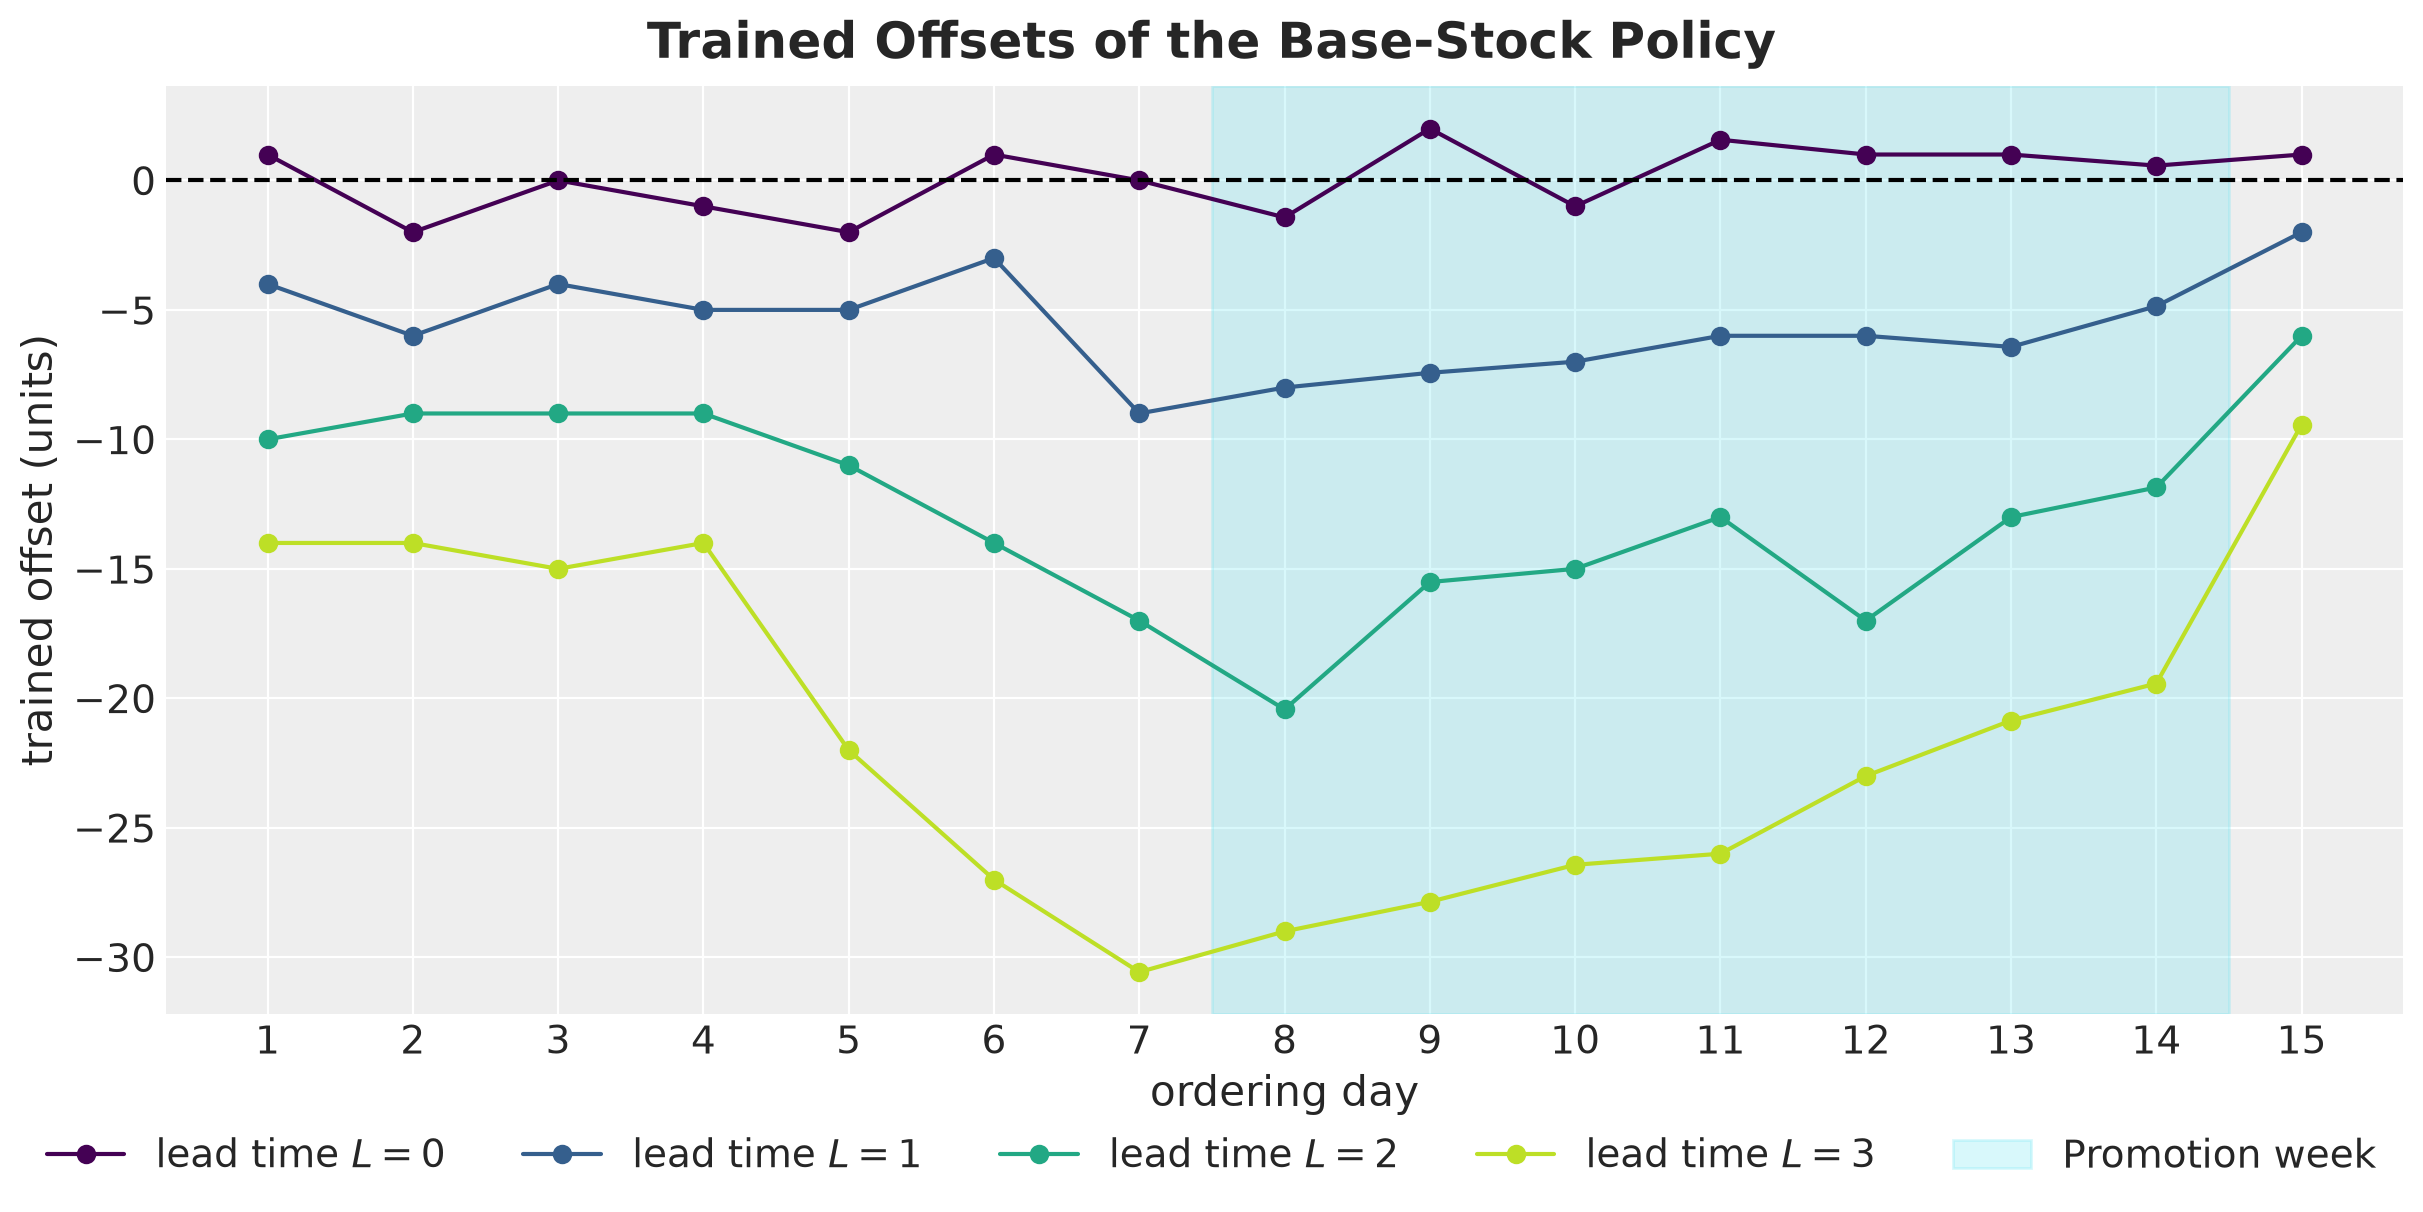

In [41]:
def sequential_colors(num: int) -> list[tuple[float, ...]]:
    """`num` colors of the viridis palette for an ordered variable, dark to light."""
    return [plt.colormaps["viridis"](0.9 * k / max(num - 1, 1)) for k in range(num)]


fig, ax = plt.subplots(figsize=(12, 6))

for lead_time, color in zip(
    setup.lead_times, sequential_colors(len(setup.lead_times)), strict=True
):
    ax.plot(
        ordering_days,
        policies[lead_time, PolicyName.BASE_STOCK].params,
        "o-",
        color=color,
        label=f"lead time $L = {lead_time}$",
    )

ax.axhline(0.0, color="black", linestyle="--")
shade_promotion(ax)
ax.set(
    xlabel="ordering day",
    ylabel="trained offset (units)",
    xticks=ordering_days,
)
fig.legend(loc="outside lower center", ncol=5)
fig.suptitle(
    "Trained Offsets of the Base-Stock Policy", fontsize=18, fontweight="bold"
);

The offsets stay near zero without a lead time and are negative with one.

- **No lead time.** For $L = 0$ the offsets stay within $2$ units of zero. Without a lead time we can order up to the level of the day on every day. As long as the stock left over is below that level, the days are separate single-day problems, and the newsvendor levels already solve them.
- **Positive lead time.** For $L \geq 1$ the offsets are negative on every ordering day, and their size grows with the lead time. The lowest offsets are $-9$, $-20$ and $-31$ units for $L = 1, 2, 3$, on days $7$ and $8$, whose orders cover promotion days.

Recall that in the first post the myopic newsvendor *plan* cost $11\%$ more than the expected cost plan. A plan cannot react to the stock left over, and a policy can, which is why the same rule works here for $L = 0$.

The negative offsets for $L \geq 1$ are consistent with the lost sales. The newsvendor level counts all the demand of the days $t, \dots, t + L$ against the inventory position. With lost sales the demand that we cannot serve on one of those days does not take stock away, so the level asks for more than we need.

### Neural Policy

Recall from the introduction why we add a network to the base-stock policy. The base-stock rule adds the orders on their way to the stock on hand, while with lost sales it matters when each of them arrives. In addition, the forecast is updated only on day $8$, and the demand since the last forecast tells us whether the path runs above or below it.

The neural policy adds a correction to the level of the trained base-stock policy. The correction is a multilayer perceptron with two hidden layers of $32$ units, which we build with [Flax NNX](https://flax.readthedocs.io/en/latest/nnx_basics.html) as the module `MLP`. Its last layer starts with zero weights and a zero bias, so a new network returns a correction of zero. Let's check this on a network with five inputs.

In [42]:
DEMAND_SCALE = float(data.mean())  # mean daily demand of the history
HIDDEN_UNITS = 32


class MLP(nnx.Module):
    """Multilayer perceptron with two hidden layers and GELU activations."""

    def __init__(self, num_features: int, rngs: nnx.Rngs) -> None:
        self.hidden_1 = nnx.Linear(num_features, HIDDEN_UNITS, rngs=rngs)
        self.hidden_2 = nnx.Linear(HIDDEN_UNITS, HIDDEN_UNITS, rngs=rngs)
        # zero weights and bias: the network starts with no correction
        self.output = nnx.Linear(
            HIDDEN_UNITS, 1, kernel_init=nnx.initializers.zeros, rngs=rngs
        )

    def __call__(self, x: Float[Array, " features"]) -> Float[Array, "1"]:
        x = nnx.gelu(self.hidden_1(x))
        x = nnx.gelu(self.hidden_2(x))
        return self.output(x)


network_example = MLP(5, nnx.Rngs(0))
rng_key, key_example = random.split(rng_key)
{
    "parameters": sum(
        leaf.size for leaf in jax.tree.leaves(nnx.state(network_example, nnx.Param))
    ),
    "output": float(network_example(random.normal(key_example, (5,)))[0]),
}

{'parameters': 1281, 'output': 0.0}

A network with $5$ inputs has $1{,}281$ weights and biases, and it returns zero, as it should. The network of the policy reads the following features of the observation:

- **Stock.** The stock on hand and each order in the pipeline, divided by the mean daily demand $\bar{d}$ of the history.
- **Promotion.** The promotion flags of the days $t, \dots, t + L$.
- **Day.** The day $t$ divided by $H$.
- **Forecast.** The newsvendor level and the mean of the total demand of the days $t, \dots, t + L$ under the latest weekly forecast, divided by $\bar{d}$.
- **Demand history.** The demand of the last $K = 7$ days, divided by $\bar{d}$. On days $1$ and $8$ all of these days are in the forecast, and on the other days some of them are not.

The policy keeps its own copy of the offsets, in units of $\bar{d}$, and trains them together with the network. The function `nnx.split` separates a network into its graph definition, the structure of the layers, and its state, the weights and the biases. The state is a PyTree, so the trainer updates it like the offsets, and the policy puts it back into the network with `nnx.merge`. The function `make_neural_policy` returns the policy, the correction, and a function `init` that returns the state of a new network for a random key. Let's build the policy for $L = 2$ and check that the correction of a new network is zero on the first day of a test scenario.

In [43]:
class NeuralPolicy(NamedTuple):
    """A neural base-stock policy for one lead time."""

    policy: Policy
    # what the network adds to the base-stock level of the day, in units
    correction: Callable[[PyTree, Observation], Float[Array, ""]]
    # the state of a new network, its weights and biases, for a random key
    init: Callable[[PRNGKeyArray], nnx.State]
    num_features: int


def make_neural_policy(lead_time: int) -> NeuralPolicy:
    """Trained base-stock levels plus a network that reads the observation."""

    def features(obs: Observation) -> Float[Array, " features"]:
        return jnp.concatenate(
            [
                obs.inventory[None] / DEMAND_SCALE,
                obs.pipeline / DEMAND_SCALE,
                # promotion flags of the days t, ..., t + lead_time
                jax.lax.dynamic_slice(promo_future, (obs.day,), (lead_time + 1,)),
                (obs.day / setup.horizon)[None],
                jnp.stack([obs.forecast.level, obs.forecast.mean]) / DEMAND_SCALE,
                obs.demand_history / DEMAND_SCALE,
            ]
        )

    # the number of features, from the observation of day one with any forecast
    forecast_shape = Forecast(jnp.asarray(0.0), jnp.asarray(0.0))
    observation = observe(
        initial_state(lead_time), jnp.asarray(0), forecast_shape, lead_time
    )
    num_features = features(observation).shape[0]
    # the structure of the network, without its weights and biases
    graphdef, _ = nnx.split(MLP(num_features, nnx.Rngs(0)))

    def init(key: PRNGKeyArray) -> nnx.State:
        _, state = nnx.split(MLP(num_features, nnx.Rngs(key)))
        return state

    def correction(params: PyTree, obs: Observation) -> Float[Array, ""]:
        network = nnx.merge(graphdef, params["net"])
        return DEMAND_SCALE * network(features(obs))[0]

    def policy(params: PyTree, obs: Observation) -> Float[Array, ""]:
        offset = DEMAND_SCALE * params["offsets"][obs.day]
        level = obs.forecast.level + offset + correction(params, obs)
        return jax.nn.relu(level - obs.position)

    return NeuralPolicy(policy, correction, init, num_features)


neural_example = make_neural_policy(LEAD_TIME_DETAIL)
scenarios_example = scenarios_for(
    ScenarioSet.FORECAST, LEAD_TIME_DETAIL, ForecastSource.WEEKLY
)
observation_example = observe(
    initial_state(LEAD_TIME_DETAIL),
    jnp.asarray(0),
    jax.tree.map(lambda leaf: leaf[0, 0], scenarios_example.forecast),
    LEAD_TIME_DETAIL,
)
rng_key, key_example = random.split(rng_key)
params_example = {
    "offsets": jnp.zeros(setup.horizon),
    "net": neural_example.init(key_example),
}
{
    "features": neural_example.num_features,
    "correction": float(neural_example.correction(params_example, observation_example)),
}

{'features': 15, 'correction': 0.0}

For $L = 2$ the network reads $15$ features, $1 + 1 + 3 + 1 + 2 + 7$ in the order of the list above, and a new network adds nothing to the level.

The function `train_neural` trains the neural policy of one lead time from three seeds at once, with `jax.vmap` over the seeds. Every seed starts from the trained offsets of the base-stock policy and from a new network. It uses batches of $256$ scenarios, $3{,}000$ steps and a learning rate of $0.003$, and keeps the seed with the lowest validation loss.

In [44]:
MINIBATCH = TrainConfig(num_steps=3_000, batch_size=256, learning_rate=3e-3)
NUM_SEEDS = 3


class NeuralTraining(NamedTuple):
    """The neural policy of the best seed and the validation loss of every seed."""

    trained: TrainedPolicy
    validation: Float[Array, "seeds evaluations"]


def train_neural(
    key: PRNGKeyArray,
    lead_time: int,
    config: InventoryConfig,
    offsets: Float[Array, " horizon"],
) -> NeuralTraining:
    """Train the neural policy from several seeds and keep the best on validation."""
    neural = make_neural_policy(lead_time)
    scenarios = (
        scenarios_for(ScenarioSet.TRAINING, lead_time, ForecastSource.WEEKLY),
        scenarios_for(ScenarioSet.VALIDATION, lead_time, ForecastSource.WEEKLY),
    )
    state = initial_state(lead_time)
    key_init, key_train = random.split(key)
    # one new network per seed, all with the same offsets
    params = jax.vmap(
        lambda key_seed: {
            "offsets": offsets / DEMAND_SCALE,
            "net": neural.init(key_seed),
        }
    )(random.split(key_init, NUM_SEEDS))
    train_seeds = jax.jit(
        jax.vmap(
            lambda key_seed, params_seed: train(
                key_seed,
                neural.policy,
                params_seed,
                *scenarios,
                state,
                config,
                lead_time,
                0.0,  # tail weight: we train the network for the expected loss
                MINIBATCH,
            )
        )
    )
    result = train_seeds(random.split(key_train, NUM_SEEDS), params)
    best_seed = int(result.validation.min(axis=1).argmin())
    best_params = jax.tree.map(lambda leaf: leaf[best_seed], result.params)
    return NeuralTraining(
        TrainedPolicy(neural.policy, best_params, ForecastSource.WEEKLY),
        result.validation,
    )

We train the neural policy for every lead time. The assertions check that before the first step every seed is the trained base-stock policy: its validation loss is the validation loss of that policy.

In [45]:
%%time

validation: dict[int, Float[Array, "seeds evaluations"]] = {}

for lead_time in setup.lead_times:
    rng_key, key_neural = random.split(rng_key)
    policies[lead_time, PolicyName.NEURAL], validation[lead_time] = train_neural(
        key_neural,
        lead_time,
        config,
        policies[lead_time, PolicyName.BASE_STOCK].params,
    )
    loss_base_stock = evaluate(
        policies[lead_time, PolicyName.BASE_STOCK], ScenarioSet.VALIDATION, lead_time
    ).loss.mean()
    assert jnp.allclose(validation[lead_time][:, 0], loss_base_stock, atol=0.01)

CPU times: user 5min 52s, sys: 2min 37s, total: 8min 30s
Wall time: 1min 16s


Let's look at the expected loss on the validation set during the training. Every line is one seed, and the dashed line is the validation loss of the trained base-stock policy, where every seed starts.

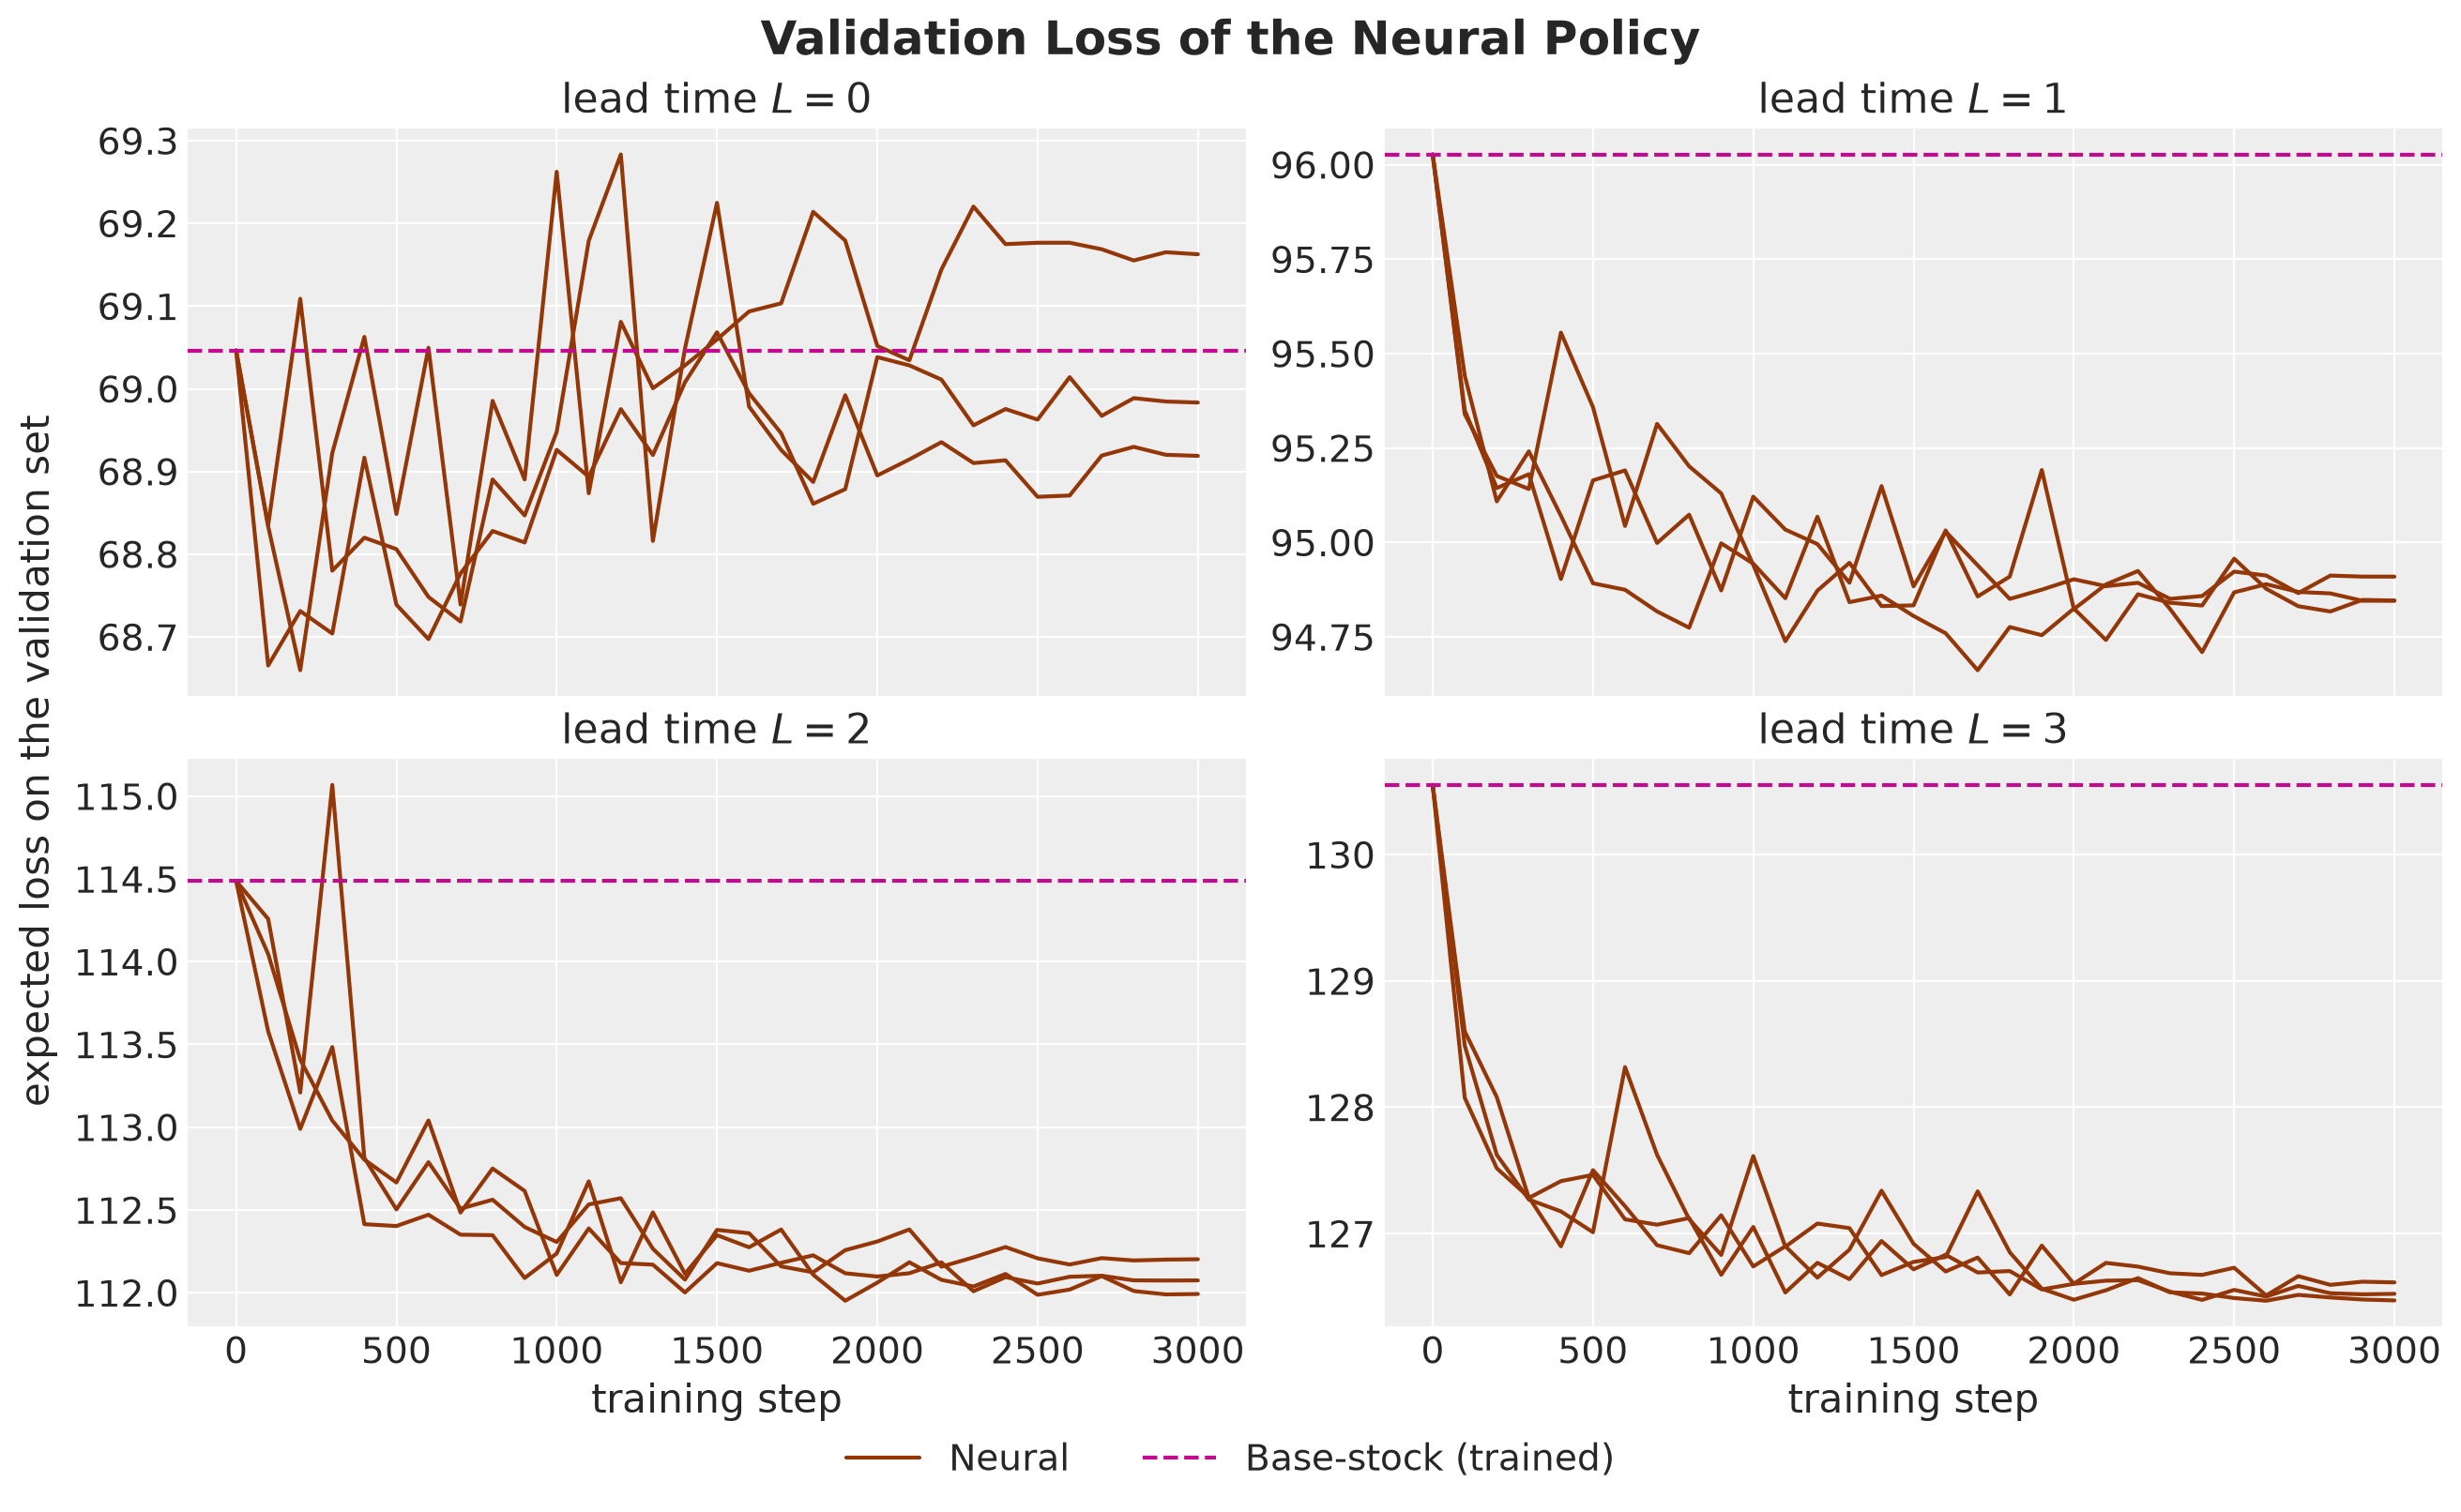

In [46]:
evaluation_steps = MINIBATCH.eval_every * jnp.arange(
    MINIBATCH.num_steps // MINIBATCH.eval_every + 1
)

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(13, 8), sharex=True, layout="constrained"
)

for ax, lead_time in zip(axes.flat, setup.lead_times, strict=True):
    lines = ax.plot(
        evaluation_steps,
        validation[lead_time].T,
        color=POLICY_COLORS[PolicyName.NEURAL],
    )
    lines[0].set_label(PolicyName.NEURAL)
    ax.axhline(
        float(validation[lead_time][0, 0]),
        color=POLICY_COLORS[PolicyName.BASE_STOCK],
        linestyle="--",
        label=PolicyName.BASE_STOCK,
    )
    ax.set(title=f"lead time $L = {lead_time}$")

for ax in axes[-1]:
    ax.set(xlabel="training step")

fig.supylabel(
    "expected loss on the validation set", fontsize=plt.rcParams["axes.labelsize"]
)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
fig.suptitle("Validation Loss of the Neural Policy", fontsize=18, fontweight="bold");

Let's look at the curves by lead time.

- **No lead time.** For $L = 0$ the validation loss moves by less than $0.4$ around its start, and the seeds end on both sides of it. The base-stock policy leaves little to correct here.
- **Positive lead time.** For $L \geq 1$ the loss falls in the first $500$ steps and then levels off. The best values are about $1.4$, $2.5$ and $4.1$ below the start for $L = 1, 2, 3$, and the three seeds end within $0.2$ of each other.

These gains are small next to the losses themselves, which are between $69$ and $131$. We measure them on the test sets in the *Out of Sample Evaluation* section.

Before we move on, we check on a trained policy that it does not use the demand of the day on which it orders. Recall the validation scenarios of the forecast check, with $50$ more units of demand from day $8$ on, and their weekly forecast, which is the same as before. The orders of the neural policy for $L = 2$ must be the same up to and including day $8$, and differ on day $9$.

In [47]:
num_days_detail = setup.horizon + LEAD_TIME_DETAIL
scenarios_changed = Scenarios(
    demand_val.at[:, CHANGED_FROM:num_days_detail].add(50.0)[:, :num_days_detail],
    jax.tree.map(
        lambda leaf: leaf[:, :num_days_detail, lead_index_detail], forecast_changed
    ),
)
orders_original = evaluate(
    policies[LEAD_TIME_DETAIL, PolicyName.NEURAL],
    ScenarioSet.VALIDATION,
    LEAD_TIME_DETAIL,
).orders
orders_changed = simulate_scenarios_jit(
    *policies[LEAD_TIME_DETAIL, PolicyName.NEURAL][:2],
    scenarios_changed,
    initial_state(LEAD_TIME_DETAIL),
    config,
    LEAD_TIME_DETAIL,
).orders
assert jnp.array_equal(
    orders_original[:, : CHANGED_FROM + 1], orders_changed[:, : CHANGED_FROM + 1]
)
assert not jnp.array_equal(
    orders_original[:, CHANGED_FROM + 1], orders_changed[:, CHANGED_FROM + 1]
)

The orders are the same up to the day of the change and differ on the day after it, as expected.

Now that we have trained all the policies, let's score them on the test sets.

## Out of Sample Evaluation

We score every policy on the two test sets, on all $3{,}000$ scenarios of each. We also simulate the policies on the training set, to see how much of a gain is left on new scenarios.

We record five scores. The stockout scores count only the days of the cost window. As in the first post, we count a stockout only when the lost sales exceed $10^{-3}$ units, since the orders of the solver are not whole numbers.

- **Expected loss.** The mean of the loss over the scenarios.
- **CVaR of the loss.** The mean of the worst $5\%$ of the scenario losses. We look at it in the *Tail Risk* section.
- **Stockout probability per day.** The fraction of scenario and day pairs with a lost sale.
- **Probability of a stockout in the cost window.** The fraction of scenarios with at least one lost sale.
- **Units ordered.** The mean over the scenarios of the sum of the orders.

The function `summarize` computes them for one policy on one scenario set. We run every policy on the three sets and collect the scores in one table.

In [48]:
STOCKOUT_TOL = 1e-3  # lost sales below this are rounding noise of the solver


class Metric(StrEnum):
    """Names of the scores."""

    EXPECTED_LOSS = "expected loss"
    CVAR = f"CVaR of loss (worst {ALPHA:.0%})"
    STOCKOUT = "stockout probability per day"
    WINDOW = "probability of a stockout in the cost window"
    ORDERED = "units ordered"


def summarize(simulation: Simulation, lead_time: int) -> dict[Metric, float]:
    """Scores of one policy over a set of scenarios."""
    # a day of the cost window with lost sales above the tolerance
    stockout = simulation.lost_sales[:, lead_time:] > STOCKOUT_TOL
    return {
        Metric.EXPECTED_LOSS: float(simulation.loss.mean()),
        Metric.CVAR: float(cvar(simulation.loss)),
        Metric.STOCKOUT: float(stockout.mean()),
        Metric.WINDOW: float(stockout.any(axis=1).mean()),
        Metric.ORDERED: float(simulation.orders.sum(axis=1).mean()),
    }


EVALUATION_SETS = [ScenarioSet.TRAINING, *TEST_SETS]
simulations: dict[tuple[ScenarioSet, int, PolicyName], Simulation] = {
    (scenario_set, lead_time, name): evaluate(trained, scenario_set, lead_time)
    for scenario_set in EVALUATION_SETS
    for (lead_time, name), trained in policies.items()
}

results = pl.DataFrame(
    [
        {
            "scenario set": str(scenario_set),
            "lead time": lead_time,
            "policy": str(name),
            **summarize(simulation, lead_time),
        }
        for (scenario_set, lead_time, name), simulation in simulations.items()
    ]
)
results.filter(pl.col("scenario set") == ScenarioSet.FORECAST).pivot(
    on="lead time", index="policy", values=Metric.EXPECTED_LOSS
)

policy,0,1,2,3
str,f64,f64,f64,f64
"""Fixed plan""",144.0,154.8,163.6,171.3
"""Base-stock (day-one forecast)""",70.4,99.2,121.2,141.3
"""Base-stock (weekly forecast)""",69.7,97.6,118.9,138.0
"""Base-stock (trained)""",69.7,96.6,114.8,129.4
"""Neural""",69.3,95.9,112.8,126.4


The table shows the expected loss on the forecast test set, one column per lead time. In every column the loss falls, or stays about the same, from one policy to the next, in the order in which we introduced them.

### Expected Loss

Let's start with the first two questions: how much of the expected loss of the fixed plan do we remove when the order of each day depends on the stock, and how much more with the weekly forecast? The next figure shows the expected loss of the five policies on each test set, by lead time.

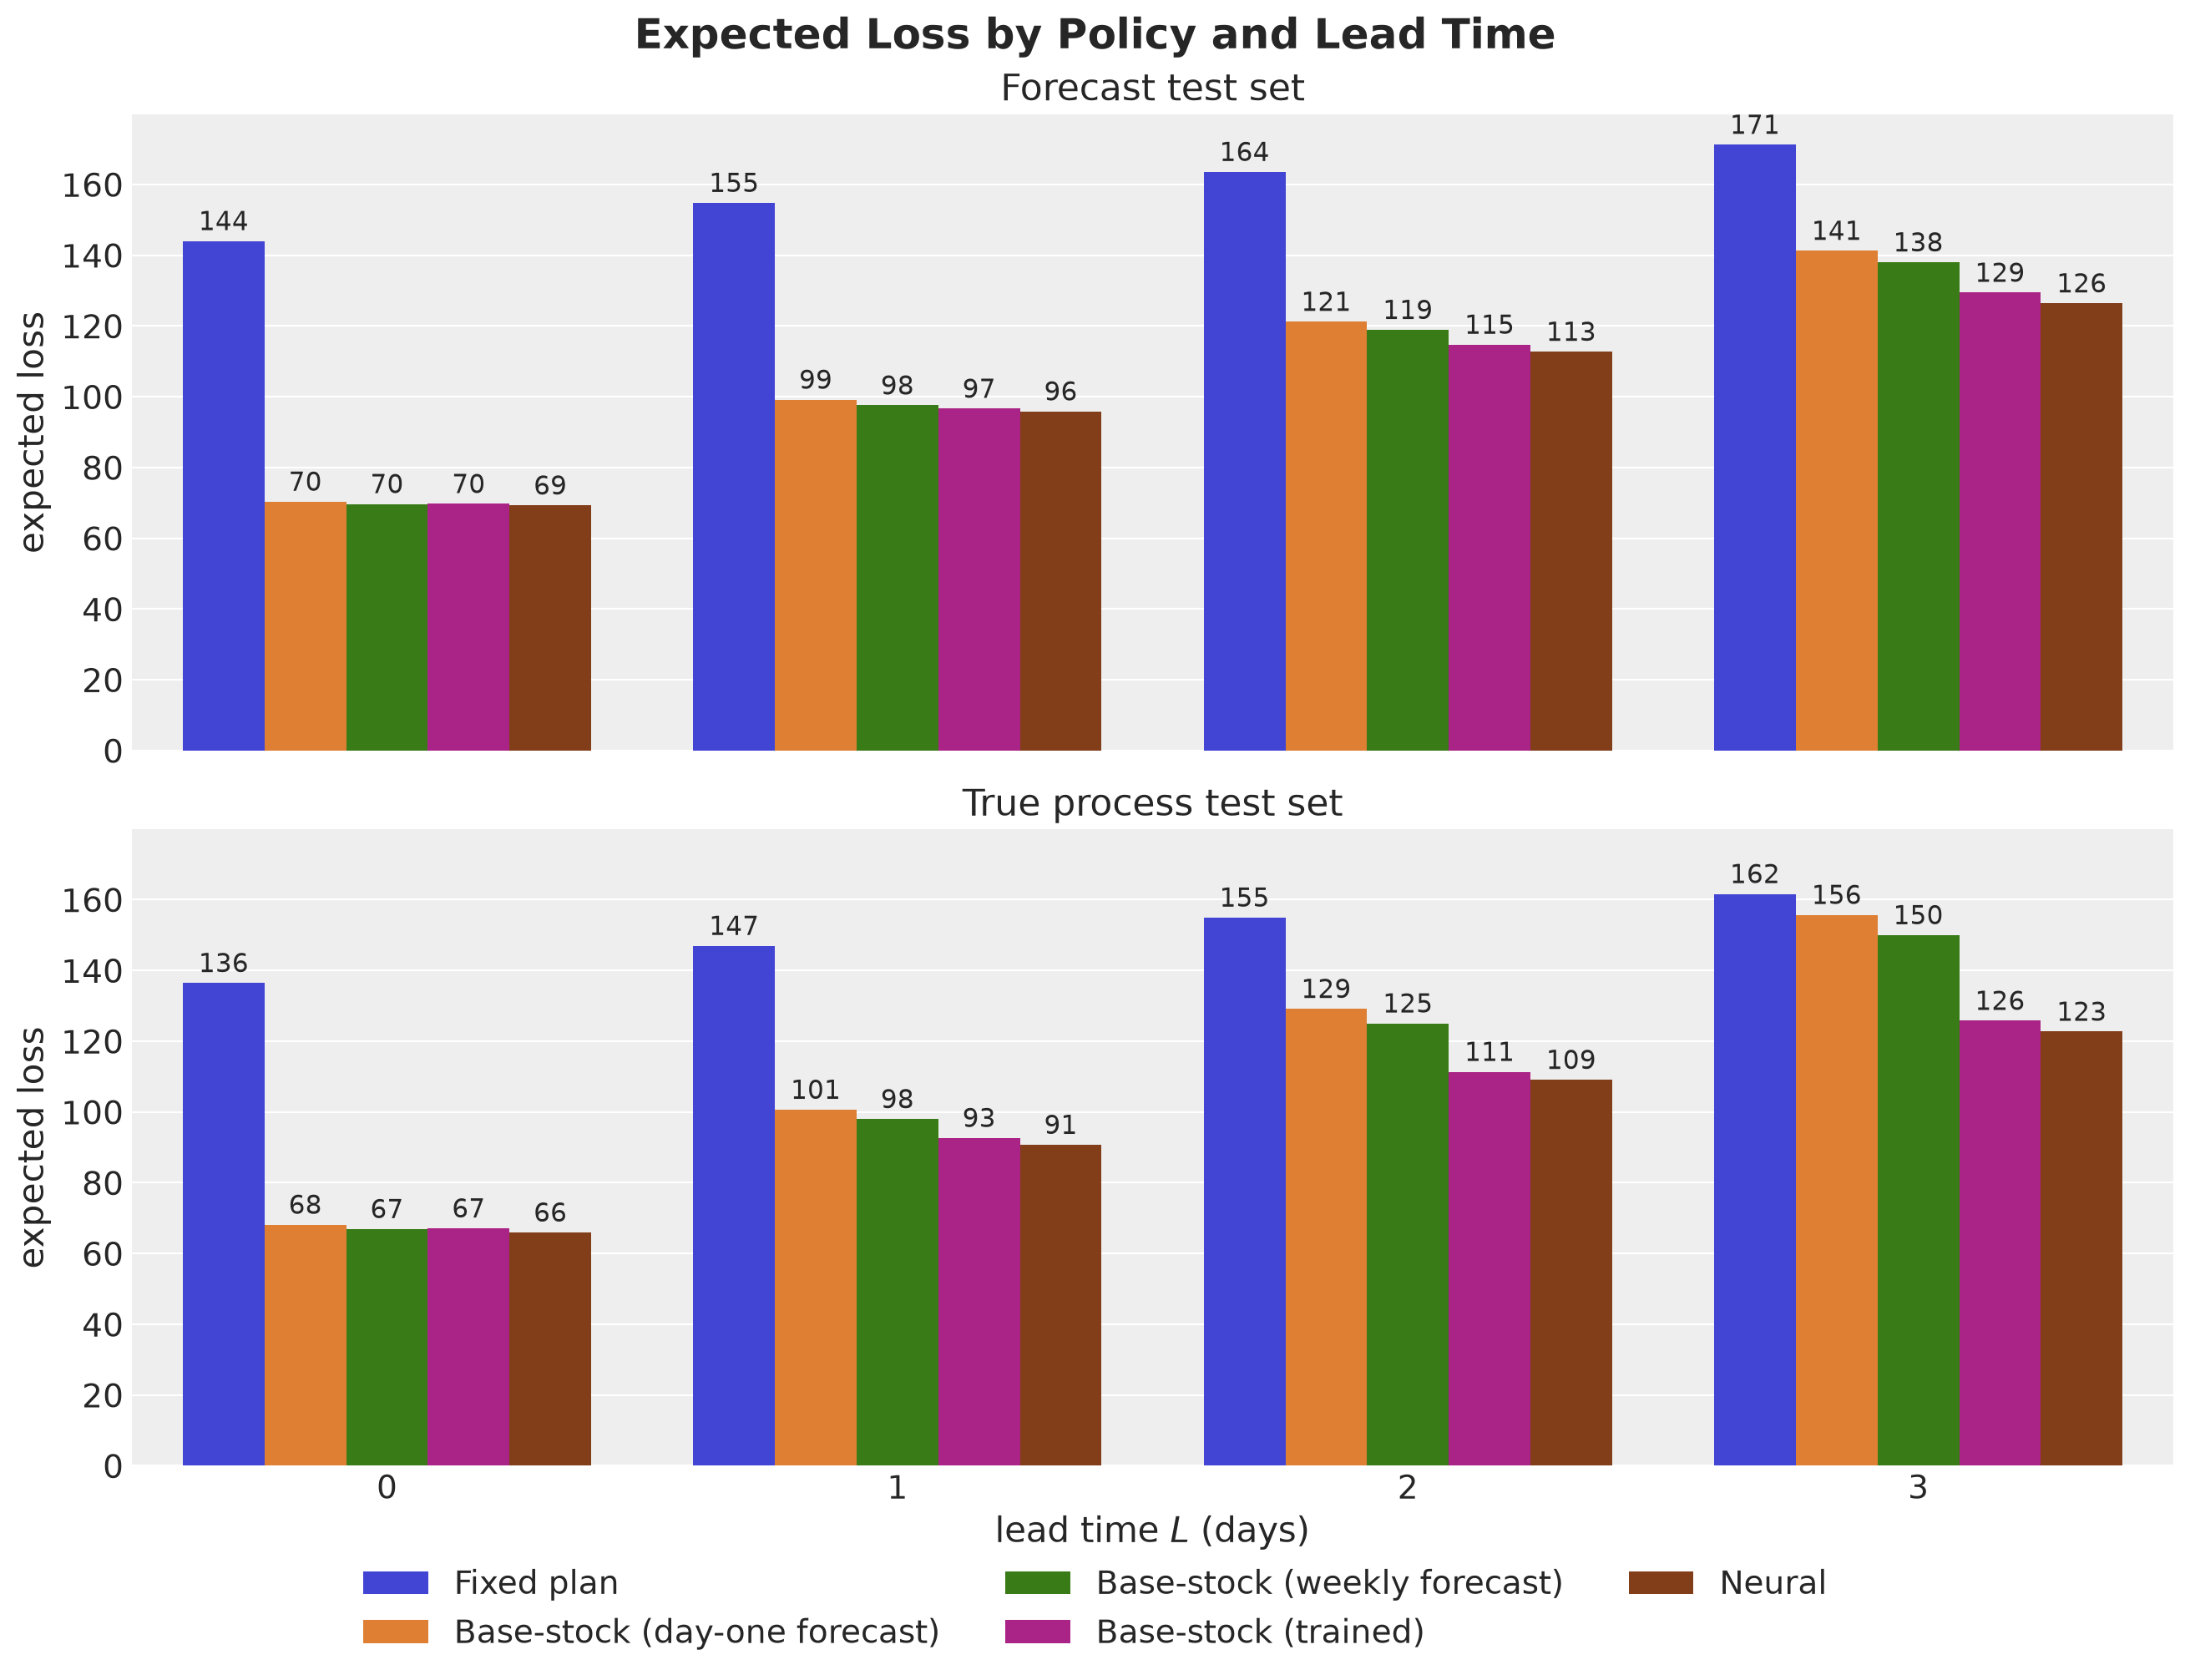

In [49]:
BAR_POLICIES = [
    PolicyName.FIXED_PLAN,
    PolicyName.DAY_ONE,
    PolicyName.WEEKLY,
    PolicyName.BASE_STOCK,
    PolicyName.NEURAL,
]

fig, axes = plt.subplots(
    nrows=2, figsize=(13, 10), sharex=True, sharey=True, layout="constrained"
)

for ax, test_set in zip(axes, TEST_SETS, strict=True):
    sns.barplot(
        data=results.filter(
            (pl.col("scenario set") == test_set) & pl.col("policy").is_in(BAR_POLICIES)
        ),
        x="lead time",
        y=Metric.EXPECTED_LOSS,
        hue="policy",
        hue_order=BAR_POLICIES,
        palette=POLICY_COLORS,
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="{:.0f}", fontsize=11, padding=2)

    ax.get_legend().remove()
    ax.set(title=test_set.capitalize(), xlabel="", ylabel=Metric.EXPECTED_LOSS)

axes[-1].set(xlabel="lead time $L$ (days)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Expected Loss by Policy and Lead Time", fontsize=18, fontweight="bold");

Let's read the upper panel, the forecast test set, first.

- **Fixed plan.** The expected loss is $144$ for $L = 0$ and $171$ for $L = 3$. For $L = 0$ this is the expected cost plan of the first post.
- **Base-stock (day-one forecast).** With no lead time the expected loss is $70$, about half of the loss of the fixed plan, and we did not need an optimizer. For $L = 3$ it is $141$, about $18\%$ below the fixed plan.
- **Base-stock (weekly forecast).** The update of day $8$ lowers the expected loss by less than $1$ for $L = 0$ and by about $3$ for $L = 3$.
- **Base-stock (trained).** Training the offsets changes nothing for $L = 0$. It lowers the expected loss by $1$ for $L = 1$ and by $9$ for $L = 3$.
- **Neural.** The network lowers the expected loss by a further $0.4$ to $3$.

On the true process test set the five policies keep the same order. The fixed plan and the trained policies have a lower loss there, and the two untrained base-stock policies a higher one for $L \geq 1$. For $L = 3$ the day-one levels are only $4\%$ below the fixed plan, and training the offsets lowers the loss by $24$.

So here is the answer to the first question. With no lead time a policy that looks only at the stock removes about half of the expected loss of the fixed plan, on both test sets. The share is smaller for every extra day of lead time:

- **Day-one levels.** $51\%$, $36\%$, $26\%$ and $18\%$ for $L = 0, 1, 2, 3$ on the forecast test set, and $50\%$, $32\%$, $17\%$ and $4\%$ on the true process test set.
- **Trained offsets.** $52\%$, $38\%$, $30\%$ and $24\%$ on the forecast test set, and $51\%$, $37\%$, $28\%$ and $22\%$ on the true process test set.

The lead time matters because an order answers to what we observe today and arrives $L$ days later. The longer the lead time, the more days of demand an order has to cover without seeing them. This is consistent with [Goldberg et al. (2016)](https://doi.org/10.1287/moor.2015.0760), who show that for lost sales with long lead times a constant order is close to optimal:

> The main insight of our work is that when the lead time is very large, such a significant amount of randomness is injected into the system between when an order for more inventory is placed and when the order is received, that "being smart" algorithmically provides almost no benefit.

### Paired Differences

The base-stock policies have expected losses within a few percent of each other, and an average over $3{,}000$ scenarios has a Monte Carlo error of the same order. The policies run on the same scenarios, so for each pair of policies we take the difference of the two losses in every scenario.

The mean of these differences equals the difference of the two means. But its standard error, which we compute from the differences, is much smaller than if the policies ran on separate scenarios, because the two losses of a scenario move together. We report the mean with two Monte Carlo standard errors.

Note that these error bars are about the mean. The spread of the difference across the scenarios is much wider, and we are interested in the expected loss. The training set has $5$ scenarios per posterior draw, which are not independent, so there we average the scenarios of a draw before we compute the standard error.

The function `plot_differences` draws such differences, one panel per pair of policies. Each panel shows the loss of one policy minus the loss of the policy that adds one component to it, so a positive value means that the component lowers the loss:

- **Weekly forecast.** The day-one levels against the weekly levels.
- **Trained offsets.** The weekly levels against the weekly levels plus the trained offsets.
- **Network.** The trained base-stock policy against the neural policy.

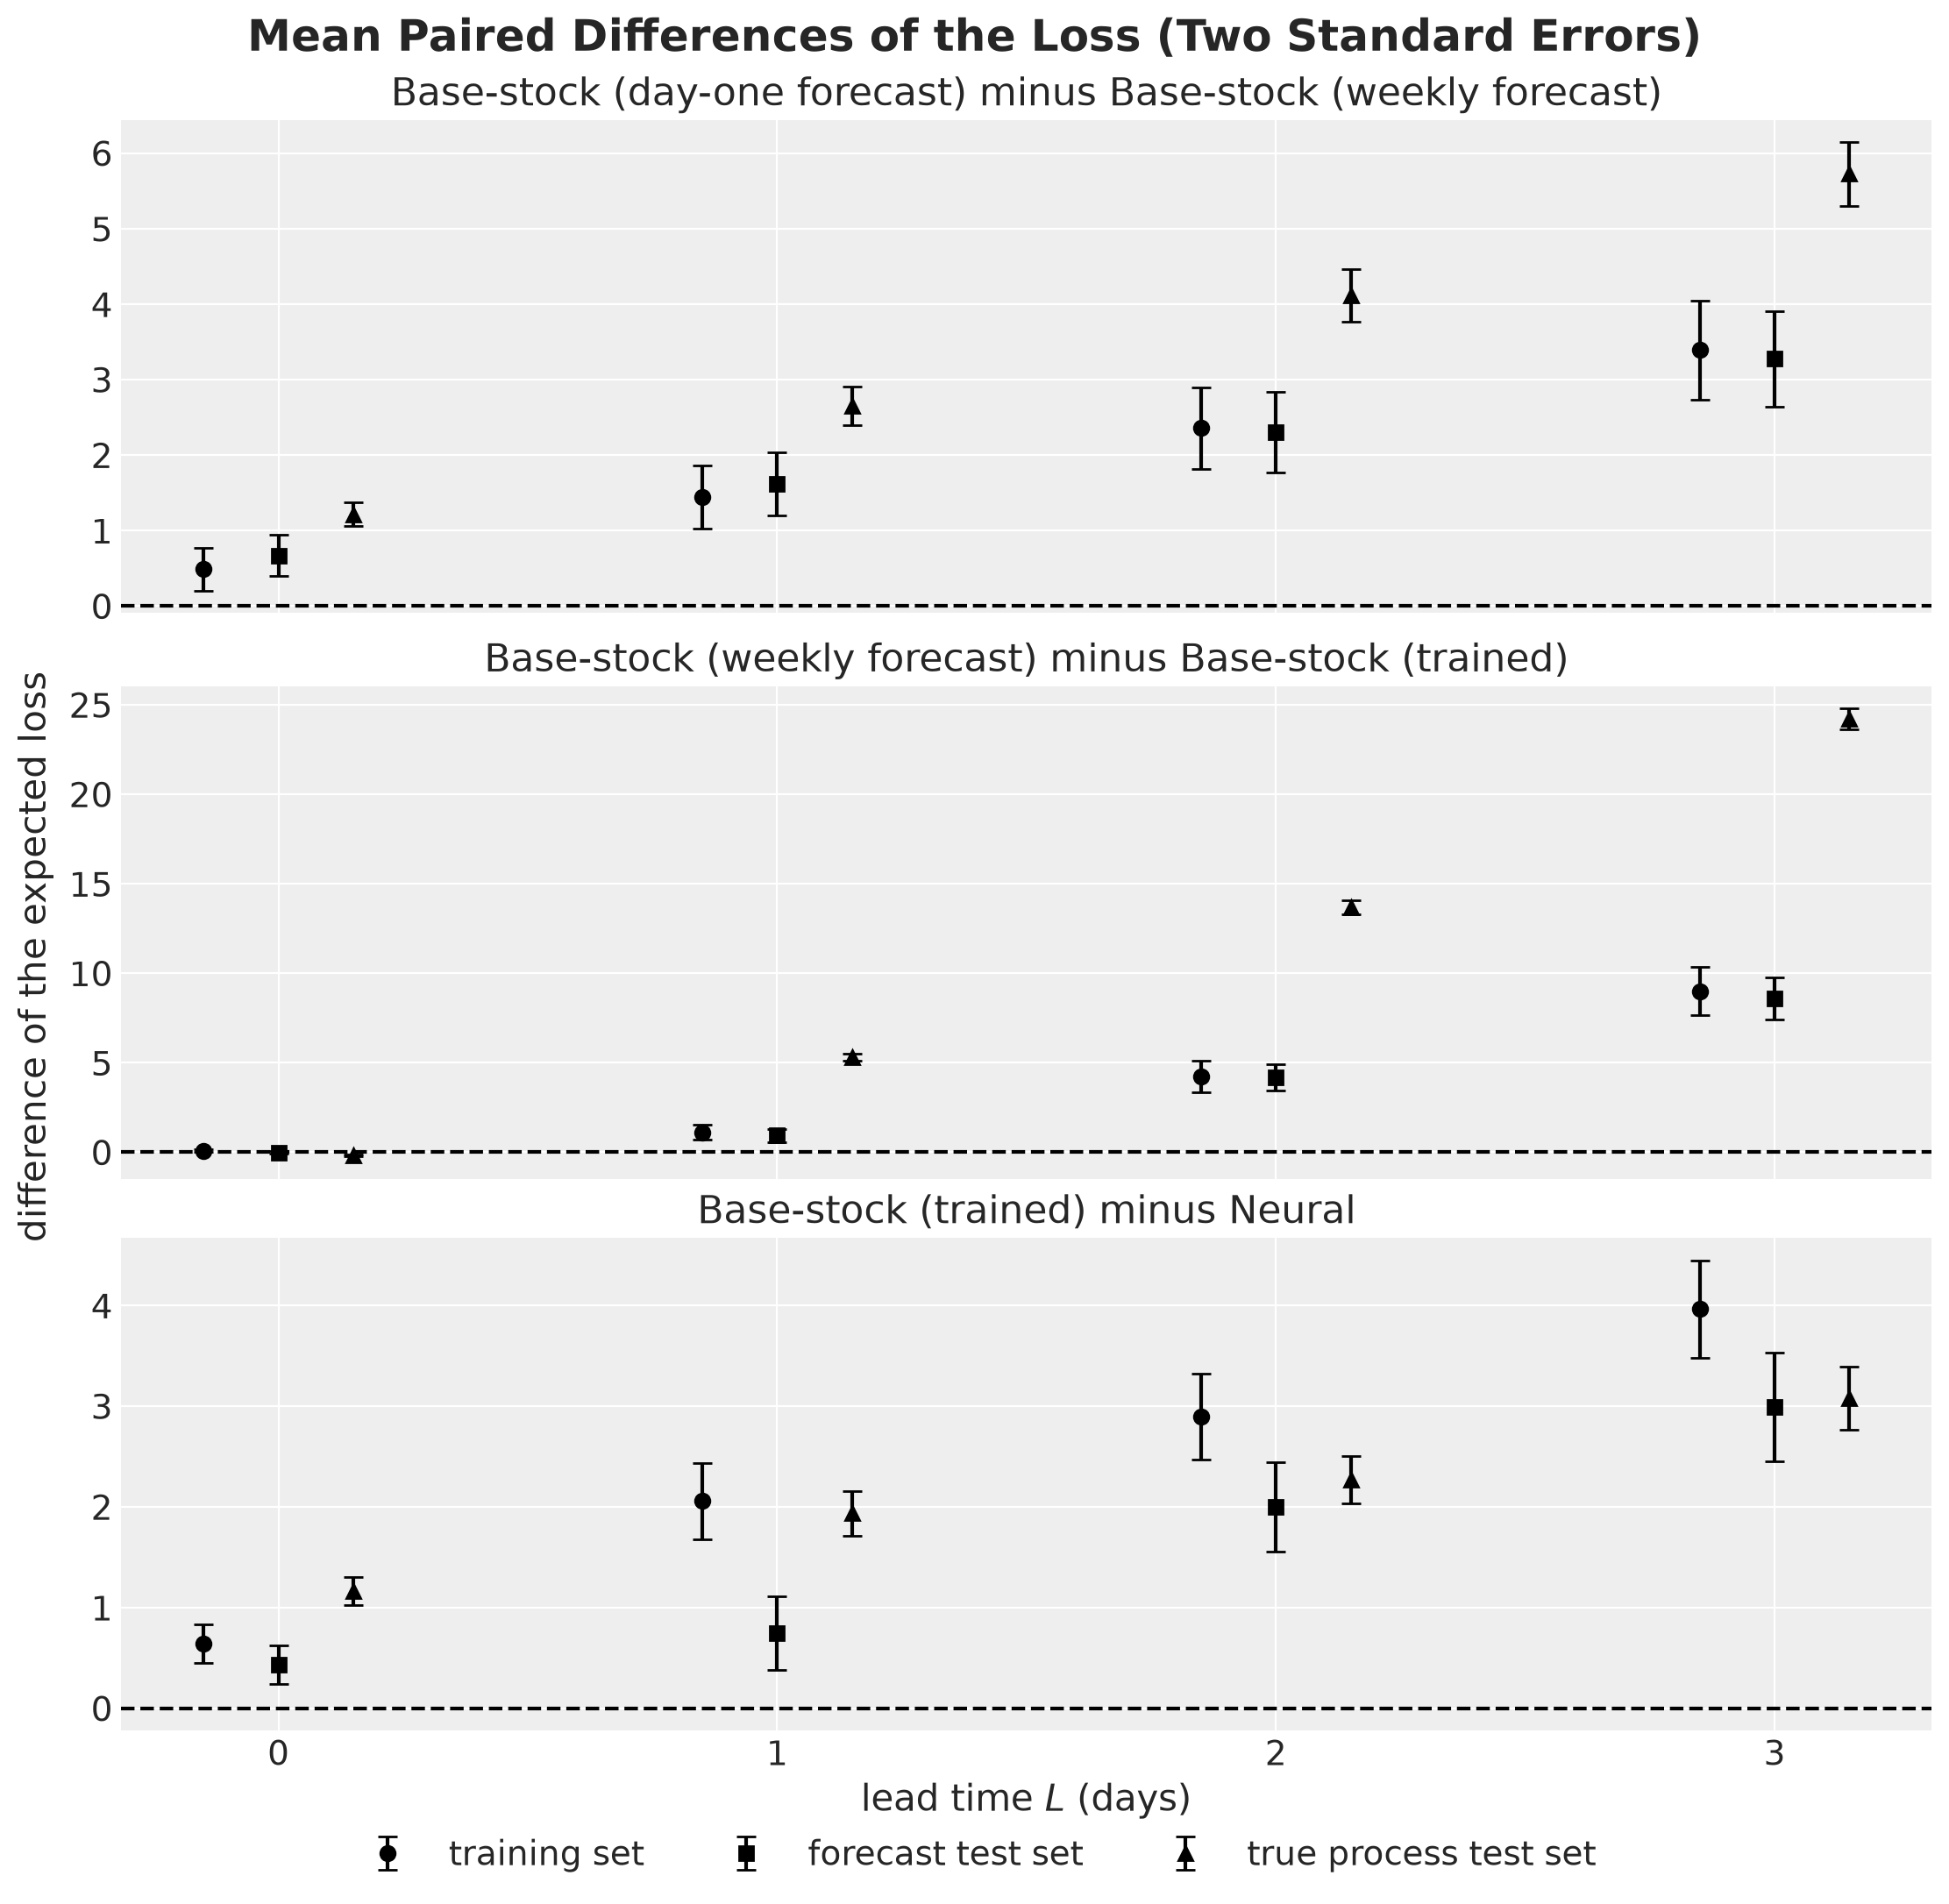

In [50]:
class Estimate(NamedTuple):
    """Mean of a paired difference with two Monte Carlo standard errors."""

    mean: float
    error: float


def mean_difference(
    difference: Float[Array, " scenarios"], num_paths: int = 1
) -> Estimate:
    """Mean and two standard errors of a difference over scenarios.

    With `num_paths` scenarios per posterior draw we average the scenarios of a
    draw first, since they are not independent.
    """
    by_draw = difference.reshape(num_paths, -1).mean(axis=0)
    return Estimate(
        float(by_draw.mean()), 2 * float(by_draw.std() / jnp.sqrt(by_draw.shape[0]))
    )


SET_MARKERS = {
    ScenarioSet.TRAINING: "o",
    ScenarioSet.FORECAST: "s",
    ScenarioSet.TRUE_PROCESS: "^",
}


def plot_differences(
    pairs: list[tuple[PolicyName, PolicyName]], scenario_sets: list[ScenarioSet]
) -> plt.Figure:
    """Mean paired difference of the loss by lead time, with two standard errors.

    One panel per pair (loss of the first policy minus loss of the second) and one
    marker per scenario set.
    """
    fig, axes = plt.subplots(
        nrows=len(pairs),
        figsize=(11, 3.6 * len(pairs)),
        sharex=True,
        layout="constrained",
    )
    offsets = jnp.linspace(-0.15, 0.15, len(scenario_sets))

    for ax, (first, second) in zip(axes, pairs, strict=True):
        for offset, scenario_set in zip(offsets, scenario_sets, strict=True):
            num_paths = PATHS_PER_DRAW if scenario_set == ScenarioSet.TRAINING else 1
            estimates = [
                mean_difference(
                    simulations[scenario_set, lead_time, first].loss
                    - simulations[scenario_set, lead_time, second].loss,
                    num_paths,
                )
                for lead_time in setup.lead_times
            ]
            ax.errorbar(
                jnp.asarray(setup.lead_times) + offset,
                [estimate.mean for estimate in estimates],
                yerr=[estimate.error for estimate in estimates],
                fmt=SET_MARKERS[scenario_set],
                color="black",
                capsize=4,
                label=scenario_set,
            )

        ax.axhline(0.0, color="black", linestyle="--")
        ax.set(title=f"{first} minus {second}")

    axes[-1].set(xlabel="lead time $L$ (days)", xticks=setup.lead_times)
    fig.supylabel(
        "difference of the expected loss", fontsize=plt.rcParams["axes.labelsize"]
    )
    fig.legend(
        *axes[0].get_legend_handles_labels(),
        loc="outside lower center",
        ncol=len(scenario_sets),
    )
    return fig


fig = plot_differences(
    [
        (PolicyName.DAY_ONE, PolicyName.WEEKLY),
        (PolicyName.WEEKLY, PolicyName.BASE_STOCK),
        (PolicyName.BASE_STOCK, PolicyName.NEURAL),
    ],
    EVALUATION_SETS,
)
fig.suptitle(
    "Mean Paired Differences of the Loss (Two Standard Errors)",
    fontsize=18,
    fontweight="bold",
);

On every set and in every panel, the gain grows with the lead time.

- **Weekly forecast.** The update lowers the expected loss on all three sets and at every lead time, and the gain grows with the lead time. On the forecast test set it is $0.7$, $1.6$, $2.3$ and $3.3$ for $L = 0, 1, 2, 3$, about the same as on the training set. On the true process test set it is larger: $1.2$, $2.7$, $4.1$ and $5.7$.
- **Trained offsets.** The gain of the training is zero for $L = 0$ and grows with the lead time. On the training set and on the forecast test set it is about $1$, $4$ and $9$ for $L = 1, 2, 3$, so it carries over to new scenarios from the forecast. On the true process test set it is much larger: $5$, $14$ and $24$. Recall that the training lowers the levels, and that the true process has less demand than the forecast in the second week. For $L = 0$ on the true process test set the trained offsets cost $0.2$ more.
- **Network.** On the forecast test set the network lowers the expected loss by $0.4$, $0.7$, $2.0$ and $3.0$. On the training set the gains are larger, between $0.6$ and $4.0$, so part of them does not carry over to new scenarios. On the true process test set the gains are between $1.2$ and $3.1$.

So here is the answer to the second question. The update of the forecast after the first week lowers the expected loss by $0.7$ to $3.3$ on the forecast test set and by $1.2$ to $5.7$ on the true process test set. This is much less than what the stock gives, and it grows with the lead time.

And here is the answer to the third question. With the weekly forecast, training the offsets lowers the expected loss by up to $9$ on the forecast test set and up to $24$ on the true process test set, for the longer lead times. The network adds up to $3$.

### Weekly Forecast Gain

Where does the weekly forecast pay? We take the lead time $L = 2$ and group the scenarios of the forecast test set by the **expected demand** behind them: the expected total demand of the ordering days under the parameters and the level of the scenario, with the level held at its value on the last day of the history. We read it from the deterministic site `mean` of the demand model, with the increments `drift` fixed at zero, which the function `log_expected_demand` does.

We write it on the log scale and in standard deviations from its mean over the test draws, so zero is the center of the forecast. The output shows where the true process is on this scale.

In [51]:
def log_expected_demand(
    key: PRNGKeyArray, particles: Particles
) -> Float[Array, " particles"]:
    """Log of the expected demand of the ordering days at the level of each particle."""
    num_particles = particles.level.shape[0]
    # no increments: the level stays at the level of the last observed day
    no_drift = jnp.zeros((num_particles, setup.horizon, 1))
    mean = Predictive(
        demand_model,
        posterior_samples={**model_params(particles), Site.DRIFT: no_drift},
        return_sites=[Site.MEAN],
        parallel=True,
    )(key, covariate_window(0, setup.horizon))[Site.MEAN]
    return jnp.log(mean.sum(axis=(1, 2)))


rng_key, key_mean = random.split(rng_key)
log_demand_test = log_expected_demand(key_mean, particles_test)
log_demand_true = log_expected_demand(
    key_mean, select_particles(particles_true, jnp.arange(1))
)

# in standard deviations from the center of the forecast
center, spread = log_demand_test.mean(), log_demand_test.std()
expected_demand_test = (log_demand_test - center) / spread
expected_demand_true = float((log_demand_true[0] - center) / spread)
{
    "expected demand of the true process (standard deviations)": expected_demand_true,
    "elasticity: posterior mean": float(posterior[Site.ELASTICITY].mean()),
    "elasticity: true value": float(true_params[Site.ELASTICITY]),
}

{'expected demand of the true process (standard deviations)': -1.0536822080612183,
 'elasticity: posterior mean': -1.6888920068740845,
 'elasticity: true value': -1.5}

The true process is about one standard deviation below the center of the forecast, so it has less demand than the typical test scenario. Part of the reason is the elasticity. Its posterior mean is $-1.69$ against a true value of $-1.5$, so the forecast expects more demand in the promotion week than the true process has.

Next, we cut the test scenarios into $8$ groups of equal size by their expected demand, and compute for each group the mean gain of the weekly forecast: the loss of `Base-stock (day-one forecast)` minus the loss of `Base-stock (weekly forecast)`, with two standard errors.

In [52]:
NUM_GROUPS = 8
gain = (
    simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, PolicyName.DAY_ONE].loss
    - simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, PolicyName.WEEKLY].loss
)
# rank of every scenario by its expected demand, cut into groups of equal size
group = jnp.argsort(jnp.argsort(expected_demand_test)) * NUM_GROUPS // gain.shape[0]
estimates = [mean_difference(gain[group == g]) for g in range(NUM_GROUPS)]
gain_by_group = pl.DataFrame(
    {
        "group": list(range(1, NUM_GROUPS + 1)),
        "expected demand (standard deviations)": [
            float(expected_demand_test[group == g].mean()) for g in range(NUM_GROUPS)
        ],
        "mean gain": [estimate.mean for estimate in estimates],
        "two standard errors": [estimate.error for estimate in estimates],
    }
)
gain_by_group

group,expected demand (standard deviations),mean gain,two standard errors
i64,f64,f64,f64
1,-1.6,8.6,1.2
2,-0.9,4.8,1.3
3,-0.5,1.9,1.3
4,-0.2,2.0,1.2
5,0.1,0.5,1.2
6,0.5,0.1,1.4
7,0.9,-1.3,1.5
8,1.7,1.9,2.5


The next figure shows the same numbers, with the position of the true process as a vertical line.

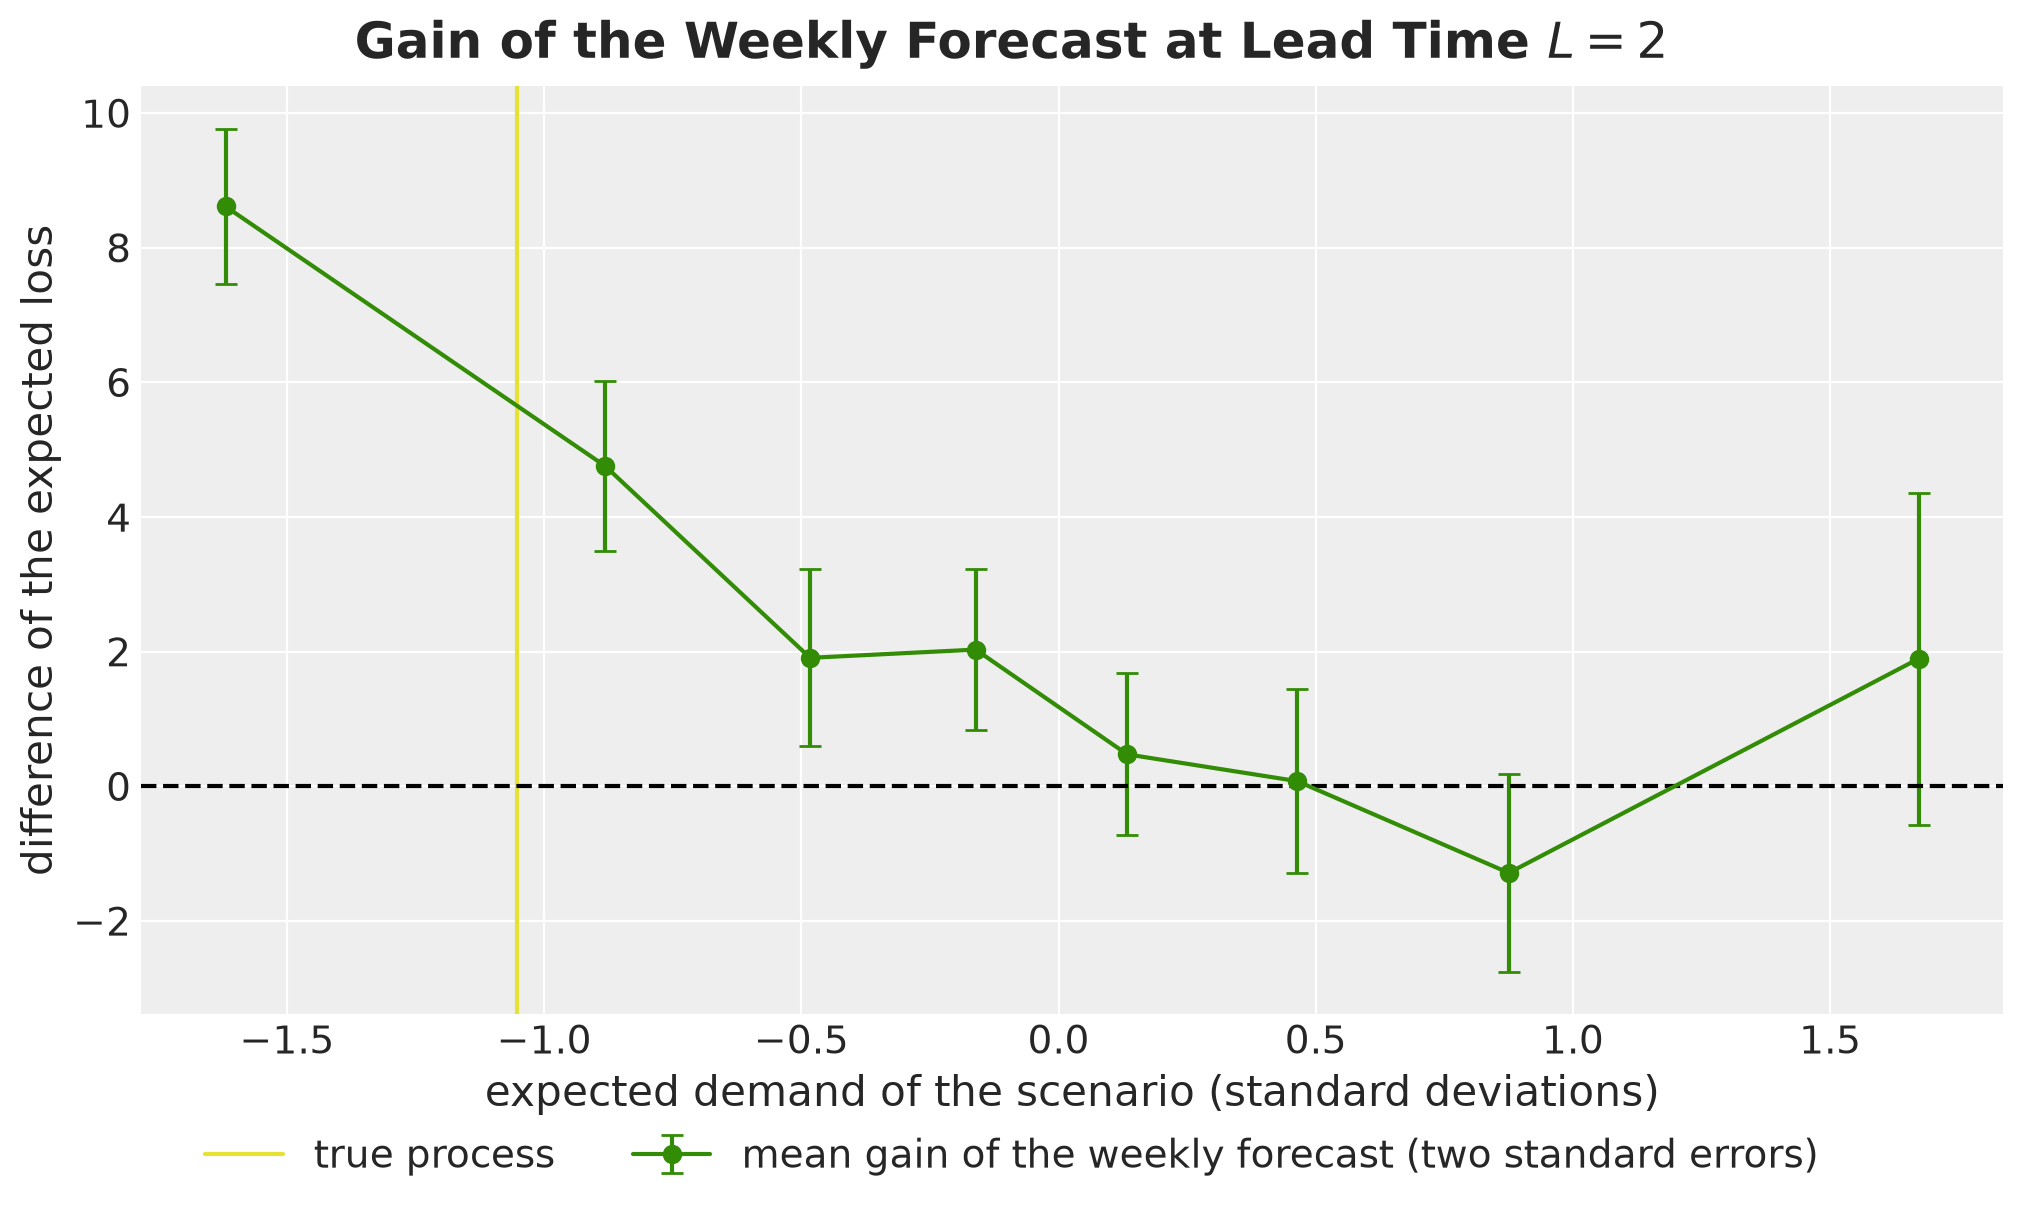

In [53]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(
    gain_by_group["expected demand (standard deviations)"],
    gain_by_group["mean gain"],
    yerr=gain_by_group["two standard errors"],
    fmt="o-",
    color=POLICY_COLORS[PolicyName.WEEKLY],
    capsize=4,
    label="mean gain of the weekly forecast (two standard errors)",
)
ax.axvline(expected_demand_true, color="C6", label="true process")
ax.axhline(0.0, color="black", linestyle="--")
ax.set(
    xlabel="expected demand of the scenario (standard deviations)",
    ylabel="difference of the expected loss",
)
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    f"Gain of the Weekly Forecast at Lead Time $L = {LEAD_TIME_DETAIL}$",
    fontsize=18,
    fontweight="bold",
);

The gain of the weekly forecast is largest in the groups with the lowest expected demand: about $9$ in the lowest group and about $5$ in the second one. Above the center it is about zero, and all $4$ intervals contain zero. The true process is between the first two groups, where the gain is about $5$, close to the gain of $4.1$ on the true process test set at $L = 2$.

This is consistent with the high critical fractile. The day-one level is a high quantile of a forecast that does not know the parameters and the level of a path. For a path with low demand it is too high, and the update lowers it and saves holding cost on every day of the second week. For a path with high demand the update raises the level, and the gain there is smaller and less certain.

### Demand Since the Update

The network also sees the demand of the last week, which the forecast has not seen yet on most days. Does it use it? We look at ordering day $15$, when the forecast of day $8$ is $7$ days old and the last $7$ days, days $8$ to $14$, all come after the update. The function `observe_day` runs the neural policy up to a day in every scenario of the forecast test set and returns what the policy observes at the start of that day.

In [54]:
def observe_day(day: int) -> Observation:
    """What the neural policy observes on a day, in every forecast test scenario."""
    trained = policies[LEAD_TIME_DETAIL, PolicyName.NEURAL]
    scenarios = scenarios_for(ScenarioSet.FORECAST, LEAD_TIME_DETAIL, trained.source)

    def observe_path(scenario: Scenarios) -> Observation:
        def step(
            state: InventoryState,
            inputs: tuple[Float[Array, ""], Forecast, Int[Array, ""]],
        ) -> tuple[InventoryState, None]:
            demand_t, forecast_t, day_t = inputs
            day_result = inventory_step(
                trained.policy,
                trained.params,
                state,
                demand_t,
                forecast_t,
                day_t,
                config,
                LEAD_TIME_DETAIL,
            )
            return day_result.state, None

        # run the days before `day`, then observe the start of `day`
        head = jax.tree.map(lambda leaf: leaf[:day], scenario)
        state, _ = jax.lax.scan(
            step,
            initial_state(LEAD_TIME_DETAIL),
            (head.demand, head.forecast, jnp.arange(day)),
        )
        forecast_day = jax.tree.map(lambda leaf: leaf[day], scenario.forecast)
        return observe(state, jnp.asarray(day), forecast_day, LEAD_TIME_DETAIL)

    return jax.vmap(observe_path)(scenarios)


ORDERING_DAY = 15  # the last 7 days are the days 8 to 14, after the update
# what the policy sees on the ordering day (the simulator counts days from zero)
observation = observe_day(ORDERING_DAY - 1)
observation.demand_history.shape

(3000, 7)

We have the observation of every scenario. The correction of the network depends on the demand history, but also on the stock and the forecast, which move with the same demand. To isolate the demand history, we raise the demand of each of the last $7$ days by $10\%$ and keep the rest of the observation fixed. The figure shows the change of the correction in every scenario, against the demand since the update relative to its mean over the scenarios.

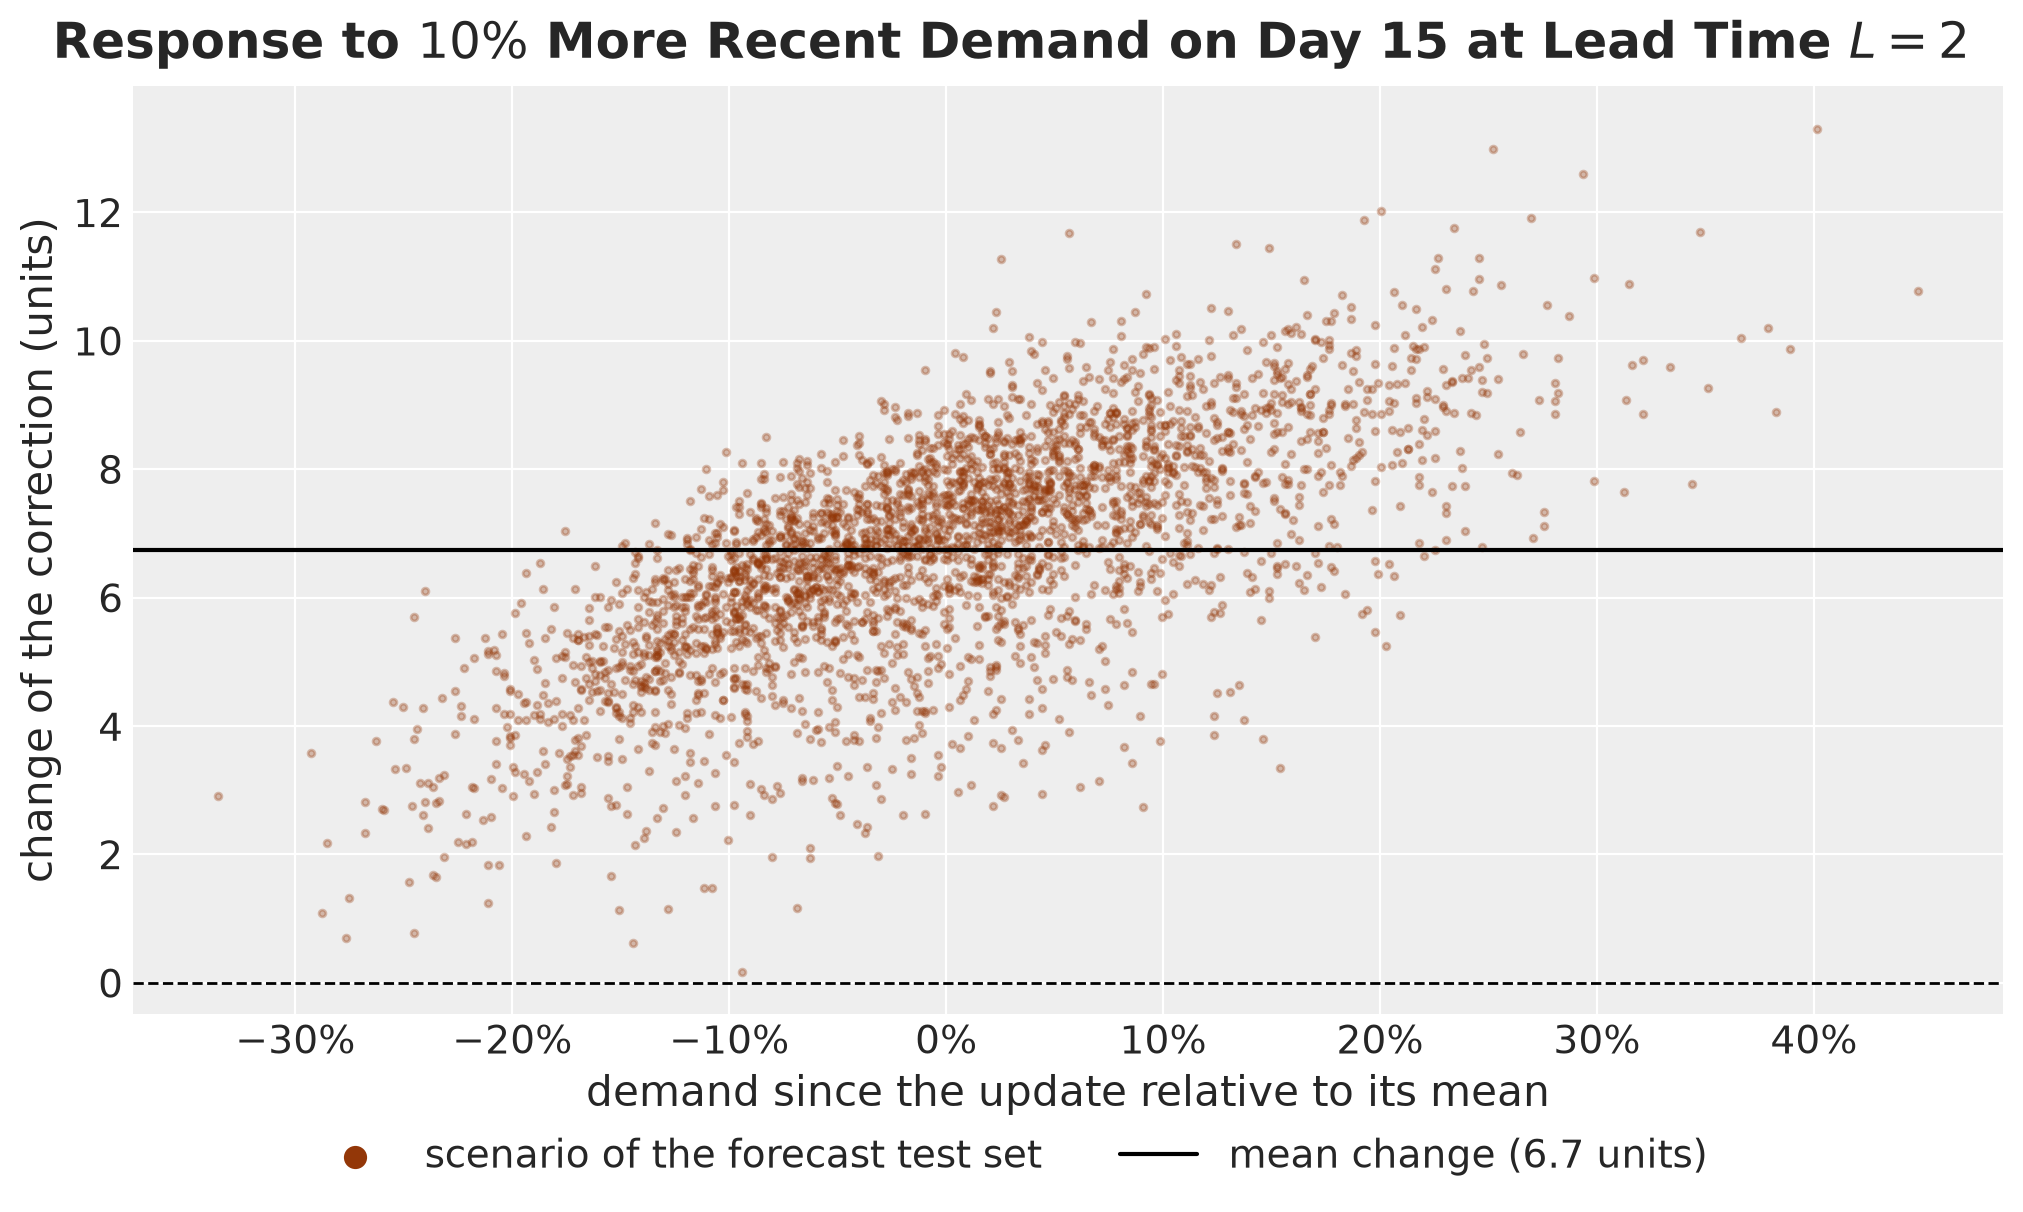

In [55]:
neural_detail = make_neural_policy(LEAD_TIME_DETAIL)
params_detail = policies[LEAD_TIME_DETAIL, PolicyName.NEURAL].params
correction_of = jax.vmap(neural_detail.correction, in_axes=(None, 0))

# the same observations with 10% more demand on each of the last 7 days
observation_up = observation._replace(demand_history=1.1 * observation.demand_history)
response = correction_of(params_detail, observation_up) - correction_of(
    params_detail, observation
)

# the demand of the days since the update, relative to its mean over the scenarios
since_update = observation.demand_history.sum(axis=1)
relative_demand = since_update / since_update.mean() - 1

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    relative_demand,
    response,
    s=6,
    alpha=0.3,
    color=POLICY_COLORS[PolicyName.NEURAL],
    label=f"scenario of the {ScenarioSet.FORECAST}",
)
ax.axhline(
    float(response.mean()),
    color="black",
    label=f"mean change ({float(response.mean()):.1f} units)",
)
ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(
    xlabel="demand since the update relative to its mean",
    ylabel="change of the correction (units)",
)
legend = fig.legend(loc="outside lower center", ncol=2, markerscale=3)
legend.legend_handles[0].set_alpha(1.0)
fig.suptitle(
    f"Response to $10\\%$ More Recent Demand on Day {ORDERING_DAY} "
    f"at Lead Time $L = {LEAD_TIME_DETAIL}$",
    fontsize=18,
    fontweight="bold",
);

The change is positive in every scenario. On average, $10\%$ more demand on each of the last $7$ days raises the correction by $6.7$ units, and by $3.6$ to $9.5$ units in $90\%$ of the scenarios. The change is larger when the demand since the update is high, in part because $10\%$ of a larger demand is more units.

So with the stock and the forecast held fixed, the network uses the demand that the forecast has not seen yet.

### Stock and Stockouts

To see why the policies beat the fixed plan, we look at what each of them does with the stock. We stay with the lead time $L = 2$ and the forecast test set. The next figure shows four of the scores.

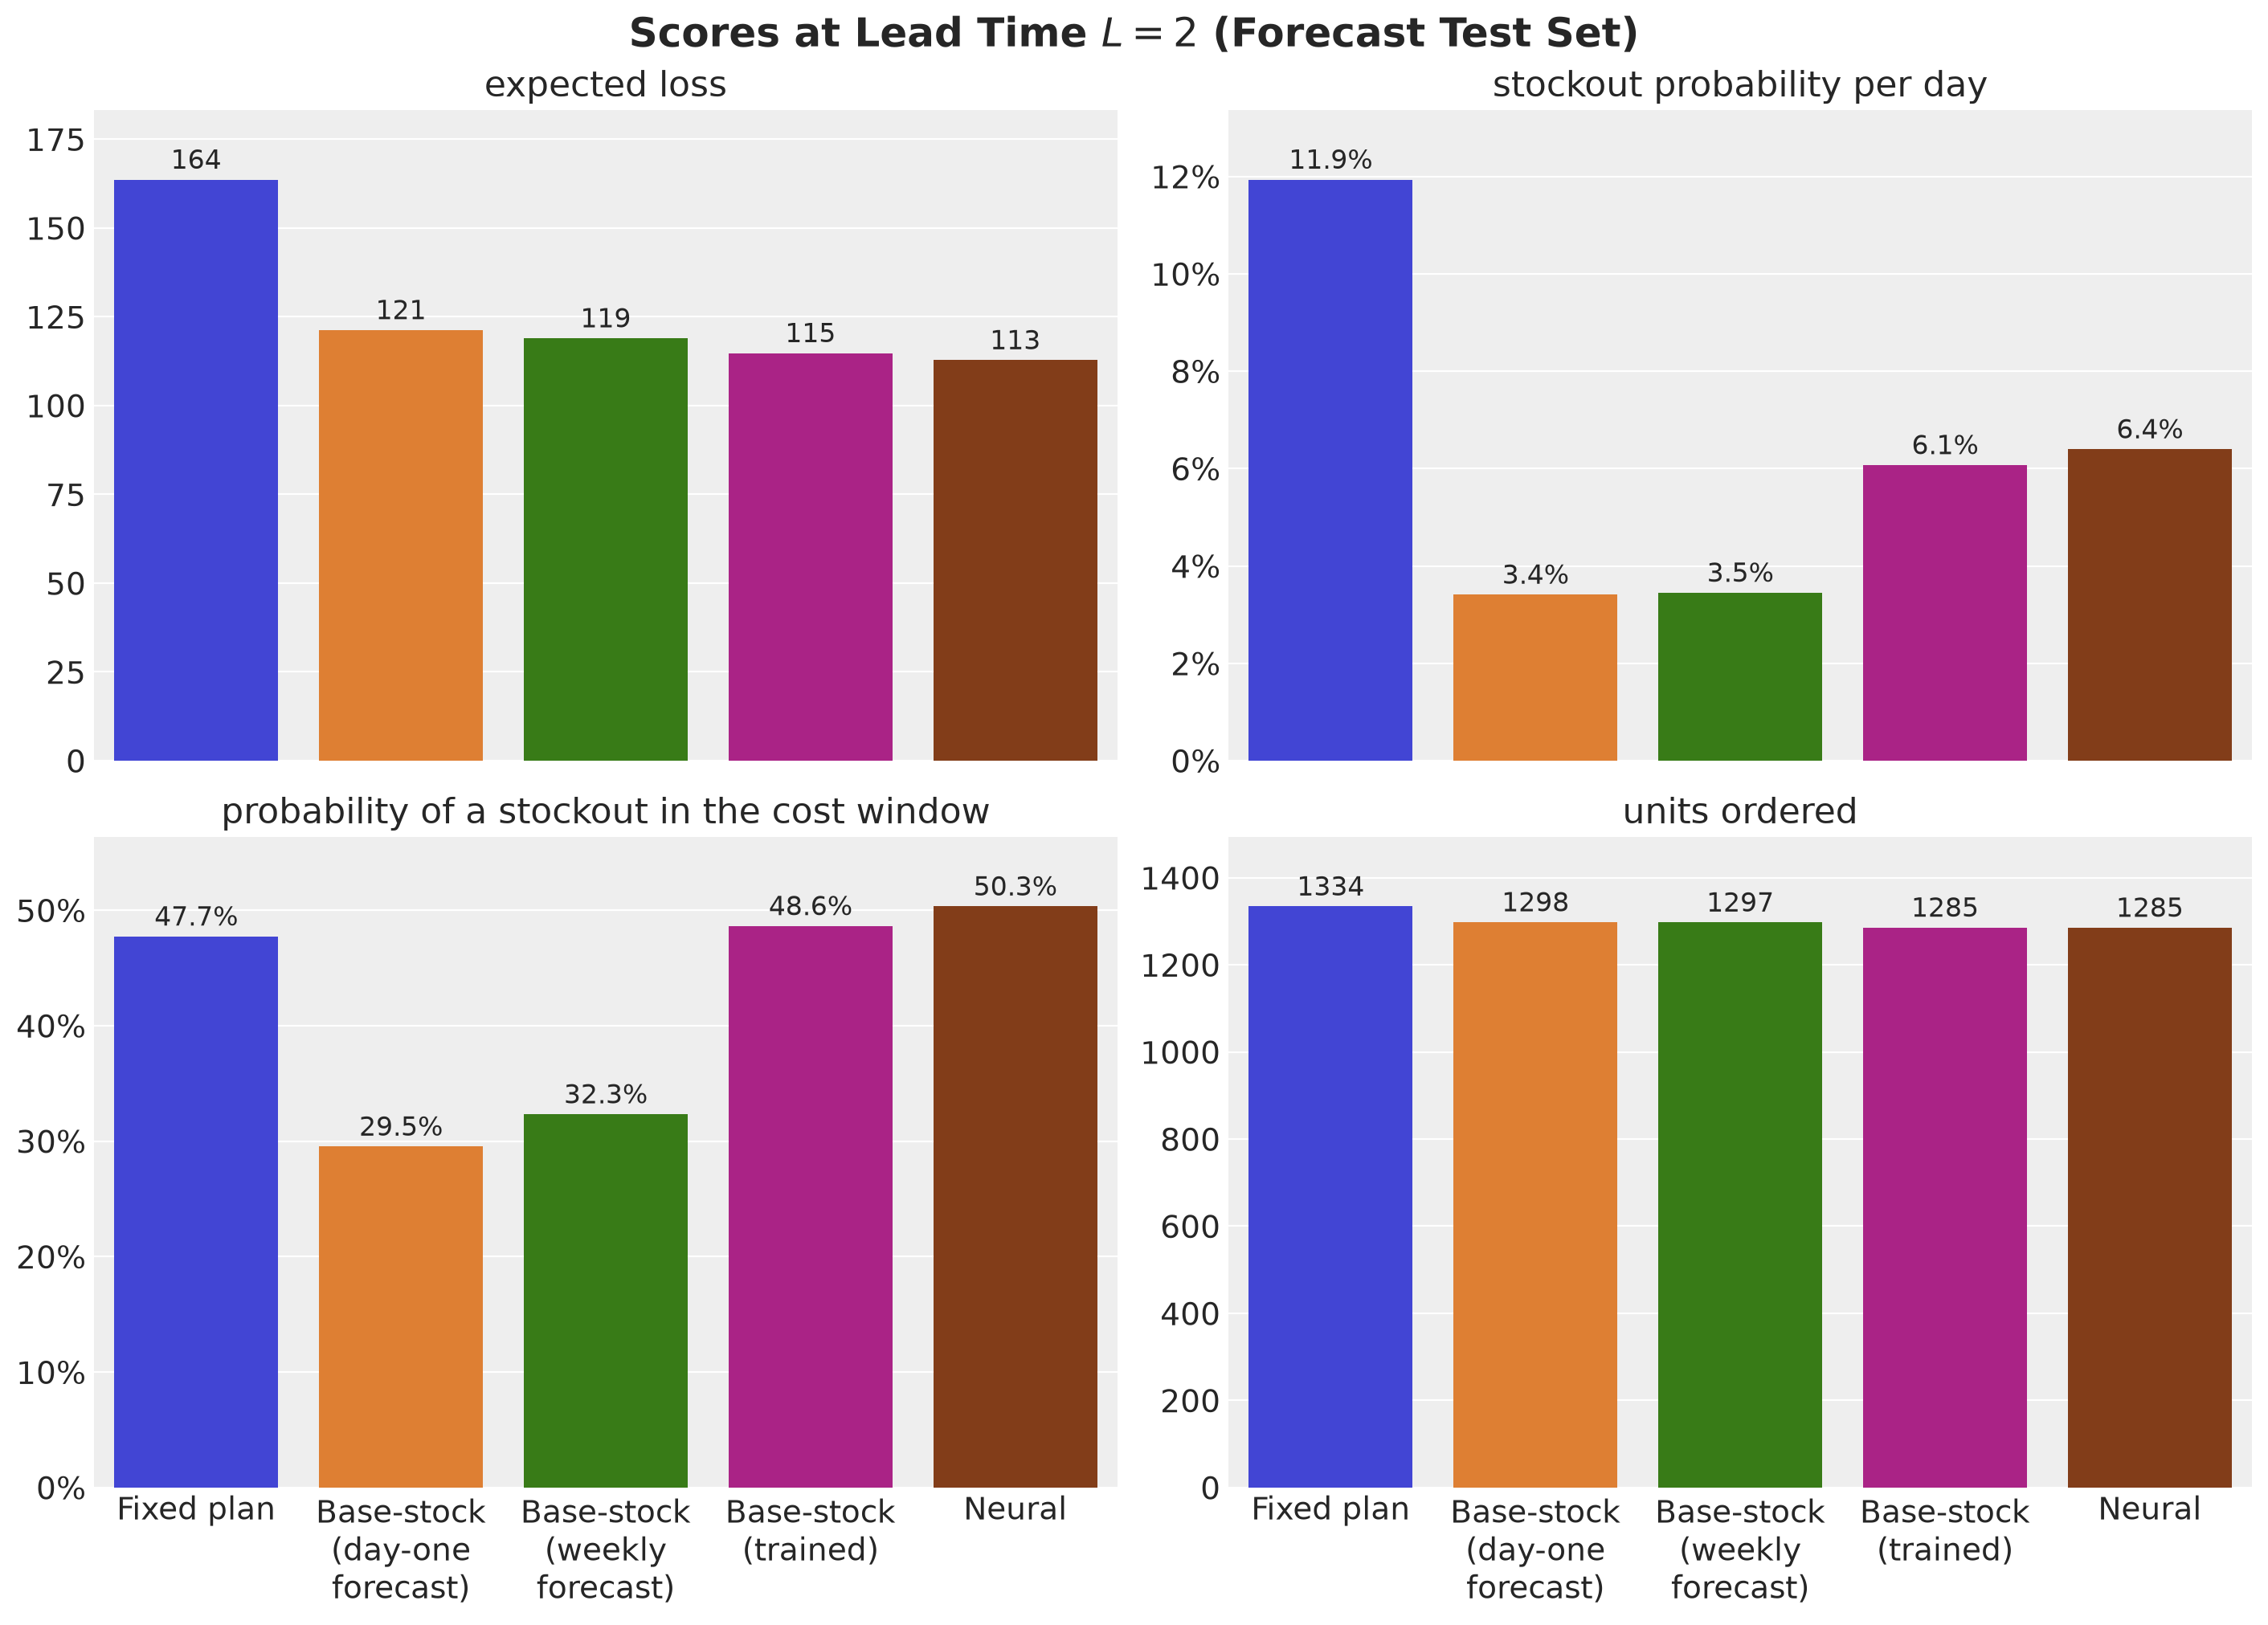

In [56]:
DETAIL_POLICIES = BAR_POLICIES
simulations_detail = {
    name: simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, name]
    for name in DETAIL_POLICIES
}
results_detail = pl.DataFrame(
    [
        {"policy": str(name), **summarize(simulation, LEAD_TIME_DETAIL)}
        for name, simulation in simulations_detail.items()
    ]
)

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(14, 10), sharex=True, layout="constrained"
)

for ax, metric in zip(
    axes.flat,
    [Metric.EXPECTED_LOSS, Metric.STOCKOUT, Metric.WINDOW, Metric.ORDERED],
    strict=True,
):
    is_probability = metric in {Metric.STOCKOUT, Metric.WINDOW}
    sns.barplot(
        data=results_detail,
        x="policy",
        y=metric,
        hue="policy",
        palette=POLICY_COLORS,
        legend=False,
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="{:.1%}" if is_probability else "{:.0f}",
            fontsize=12,
            padding=2,
        )

    if is_probability:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

    ax.margins(y=0.12)
    ax.set(title=metric, xlabel="", ylabel="")

for ax in axes[-1]:
    # the names of the policies on two lines
    ax.set_xticks(
        range(len(DETAIL_POLICIES)),
        [
            name.replace(" (", "\n(").replace(" forecast)", "\nforecast)")
            for name in DETAIL_POLICIES
        ],
    )

fig.suptitle(
    f"Scores at Lead Time $L = {LEAD_TIME_DETAIL}$ ({ScenarioSet.FORECAST.title()})",
    fontsize=18,
    fontweight="bold",
);

Let's go through the five policies.

- **Fixed plan.** It has the highest expected loss, $164$. It runs out on $11.9\%$ of the days, and it also orders the most, $1{,}334$ units on average.
- **Base-stock, day-one and weekly forecast.** The expected loss is $121$ and $119$. They run out on $3.4\%$ and $3.5\%$ of the days and order about $1{,}298$ units.
- **Base-stock (trained) and neural.** The expected loss is $115$ and $113$. They run out on $6.1\%$ and $6.4\%$ of the days, about twice as often as the untrained base-stock policies, and order about $1{,}285$ units. They run out at least once in the cost window in about half of the scenarios, as often as the fixed plan, against about a third for the untrained base-stock policies.

The fixed plan orders more than every policy and still runs out on more days. Its orders are the same in every scenario. So in the scenarios with low demand the units stay on the shelf, and in the scenarios with high demand they are missing.

The trained offsets lower the levels: the trained policies hold less stock and run out more often, and this is cheaper. Recall from the *Base-Stock Policy* section that with lost sales the newsvendor level asks for more stock than we need when an order takes time to arrive.

The next figure shows the same five policies day by day: the mean order, the mean stock on hand at the end of the day and the stockout probability. The black lines mark the cost window, and the shaded days are the promotion week.

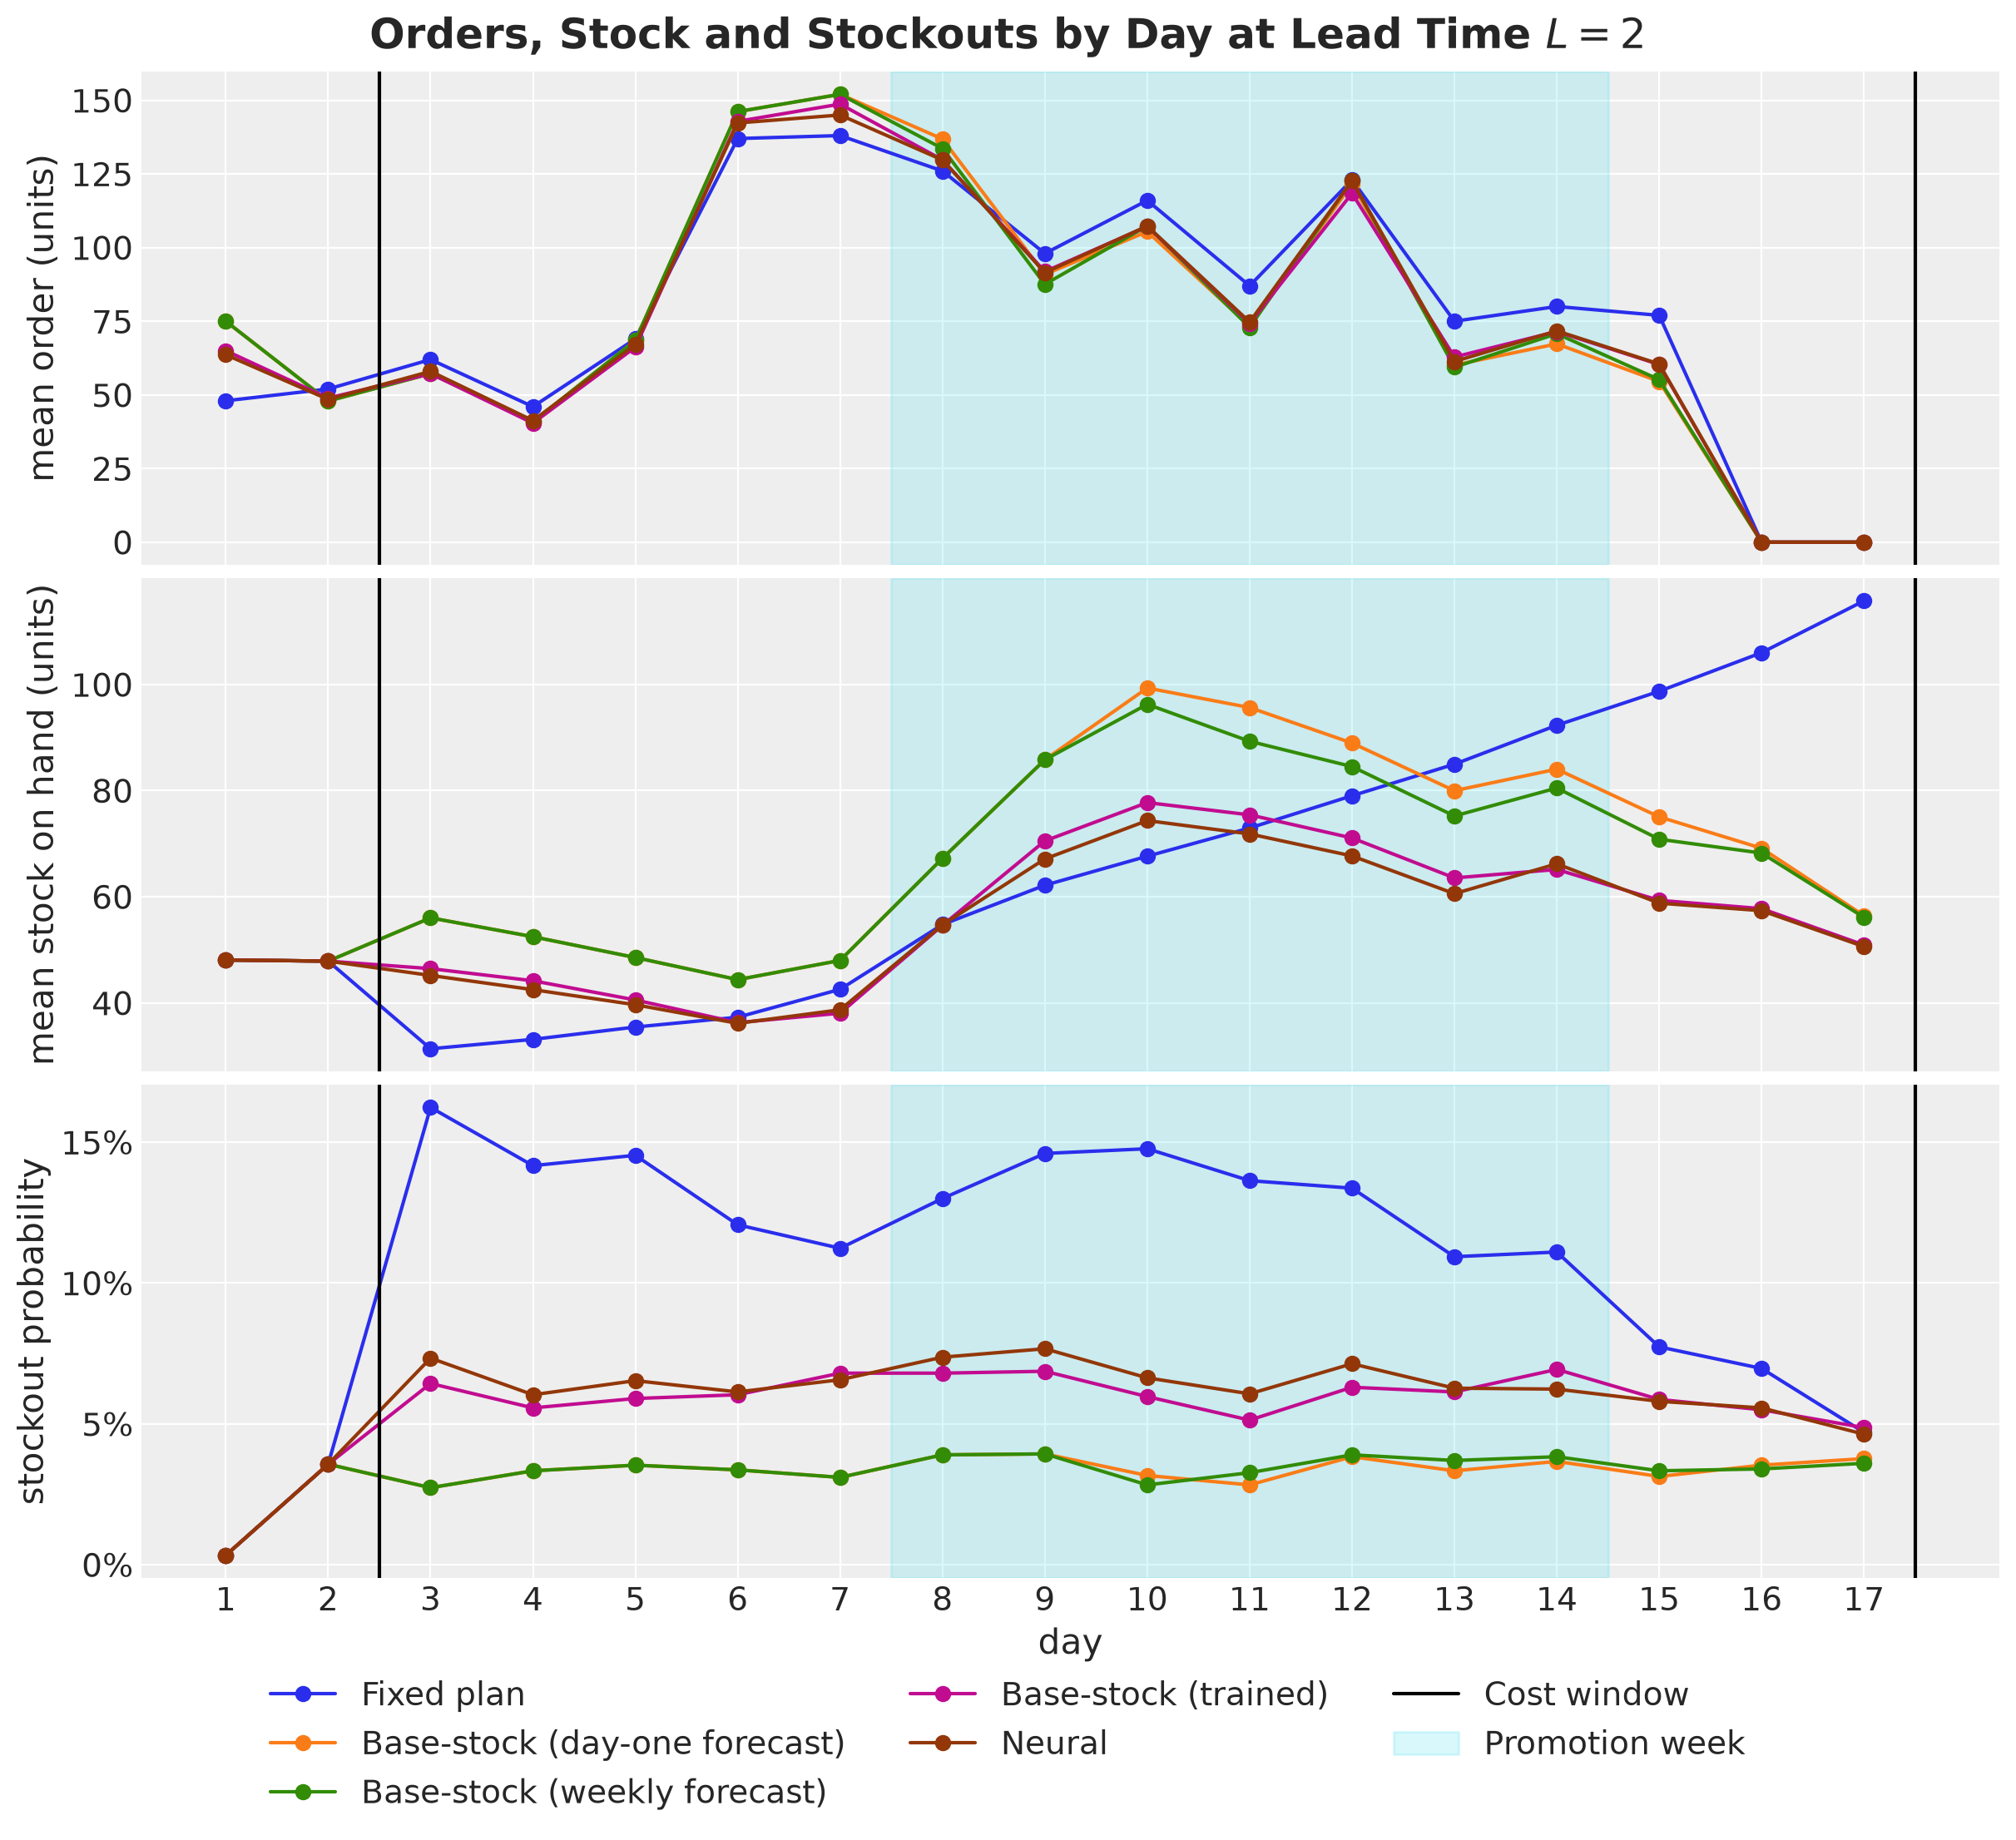

In [57]:
days_detail = jnp.arange(1, setup.horizon + LEAD_TIME_DETAIL + 1)

fig, axes = plt.subplots(nrows=3, figsize=(12, 11), sharex=True, layout="constrained")

for name, simulation in simulations_detail.items():
    for ax, values in zip(
        axes,
        [
            simulation.orders.mean(axis=0),
            simulation.inventory.mean(axis=0),
            (simulation.lost_sales > STOCKOUT_TOL).mean(axis=0),
        ],
        strict=True,
    ):
        ax.plot(days_detail, values, "o-", color=POLICY_COLORS[name], label=name)

for ax in axes:
    ax.axvline(LEAD_TIME_DETAIL + 0.5, color="black", label="Cost window")
    ax.axvline(days_detail[-1] + 0.5, color="black")
    shade_promotion(ax)

axes[0].set(ylabel="mean order (units)")
axes[1].set(ylabel="mean stock on hand (units)")
axes[2].yaxis.set_major_locator(MultipleLocator(0.05))
axes[2].yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes[2].set(xlabel="day", ylabel="stockout probability", xticks=days_detail)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    f"Orders, Stock and Stockouts by Day at Lead Time $L = {LEAD_TIME_DETAIL}$",
    fontsize=18,
    fontweight="bold",
);

We go policy by policy again.

- **Fixed plan.** The mean stock grows through the cost window and ends at $116$ units, almost four times its value on day $3$. From day $3$ to day $14$ the stockout probability stays between $11\%$ and $16\%$. The leftovers of the scenarios with low demand pile up, and the plan cannot lower a later order to use them.
- **Untrained base-stock policies.** They order $75$ units on day one, against $48$ for the fixed plan. Their mean stock rises in the promotion week to about $99$ units and comes back to $56$. Their stockout probability stays between $3\%$ and $4\%$ on every day of the cost window. On days $10$ to $16$ the policy with the weekly forecast holds $1$ to $7$ units less stock than the policy with the forecast of day one, with about the same stockout probability.
- **Trained base-stock and neural policies.** They order about $64$ units on day one. Their mean stock is $5$ to $25$ units below the stock of the untrained base-stock policies, and their stockout probability is between $5\%$ and $8\%$.

### Cost Ratio

Next, we check how much the answer to the first question depends on the costs. The lost margin $p = 2$ is $20$ times the holding cost. We also take a lost margin of $0.5$ and of $8$, so the cost ratios are $p / h = 5$, $20$ and $80$. For each ratio we train the fixed plan again and compute the newsvendor levels of the forecast of day one at the critical fractile of that ratio, from the same paths as before.

The comparison isolates the first question: both use only the forecast of day one, and the base-stock policy needs no training. The next figure shows the reduction of the expected loss of `Base-stock (day-one forecast)` relative to the fixed plan on the forecast test set. The cost ratio is ordered, so its colors come from the viridis palette, as the lead times above.

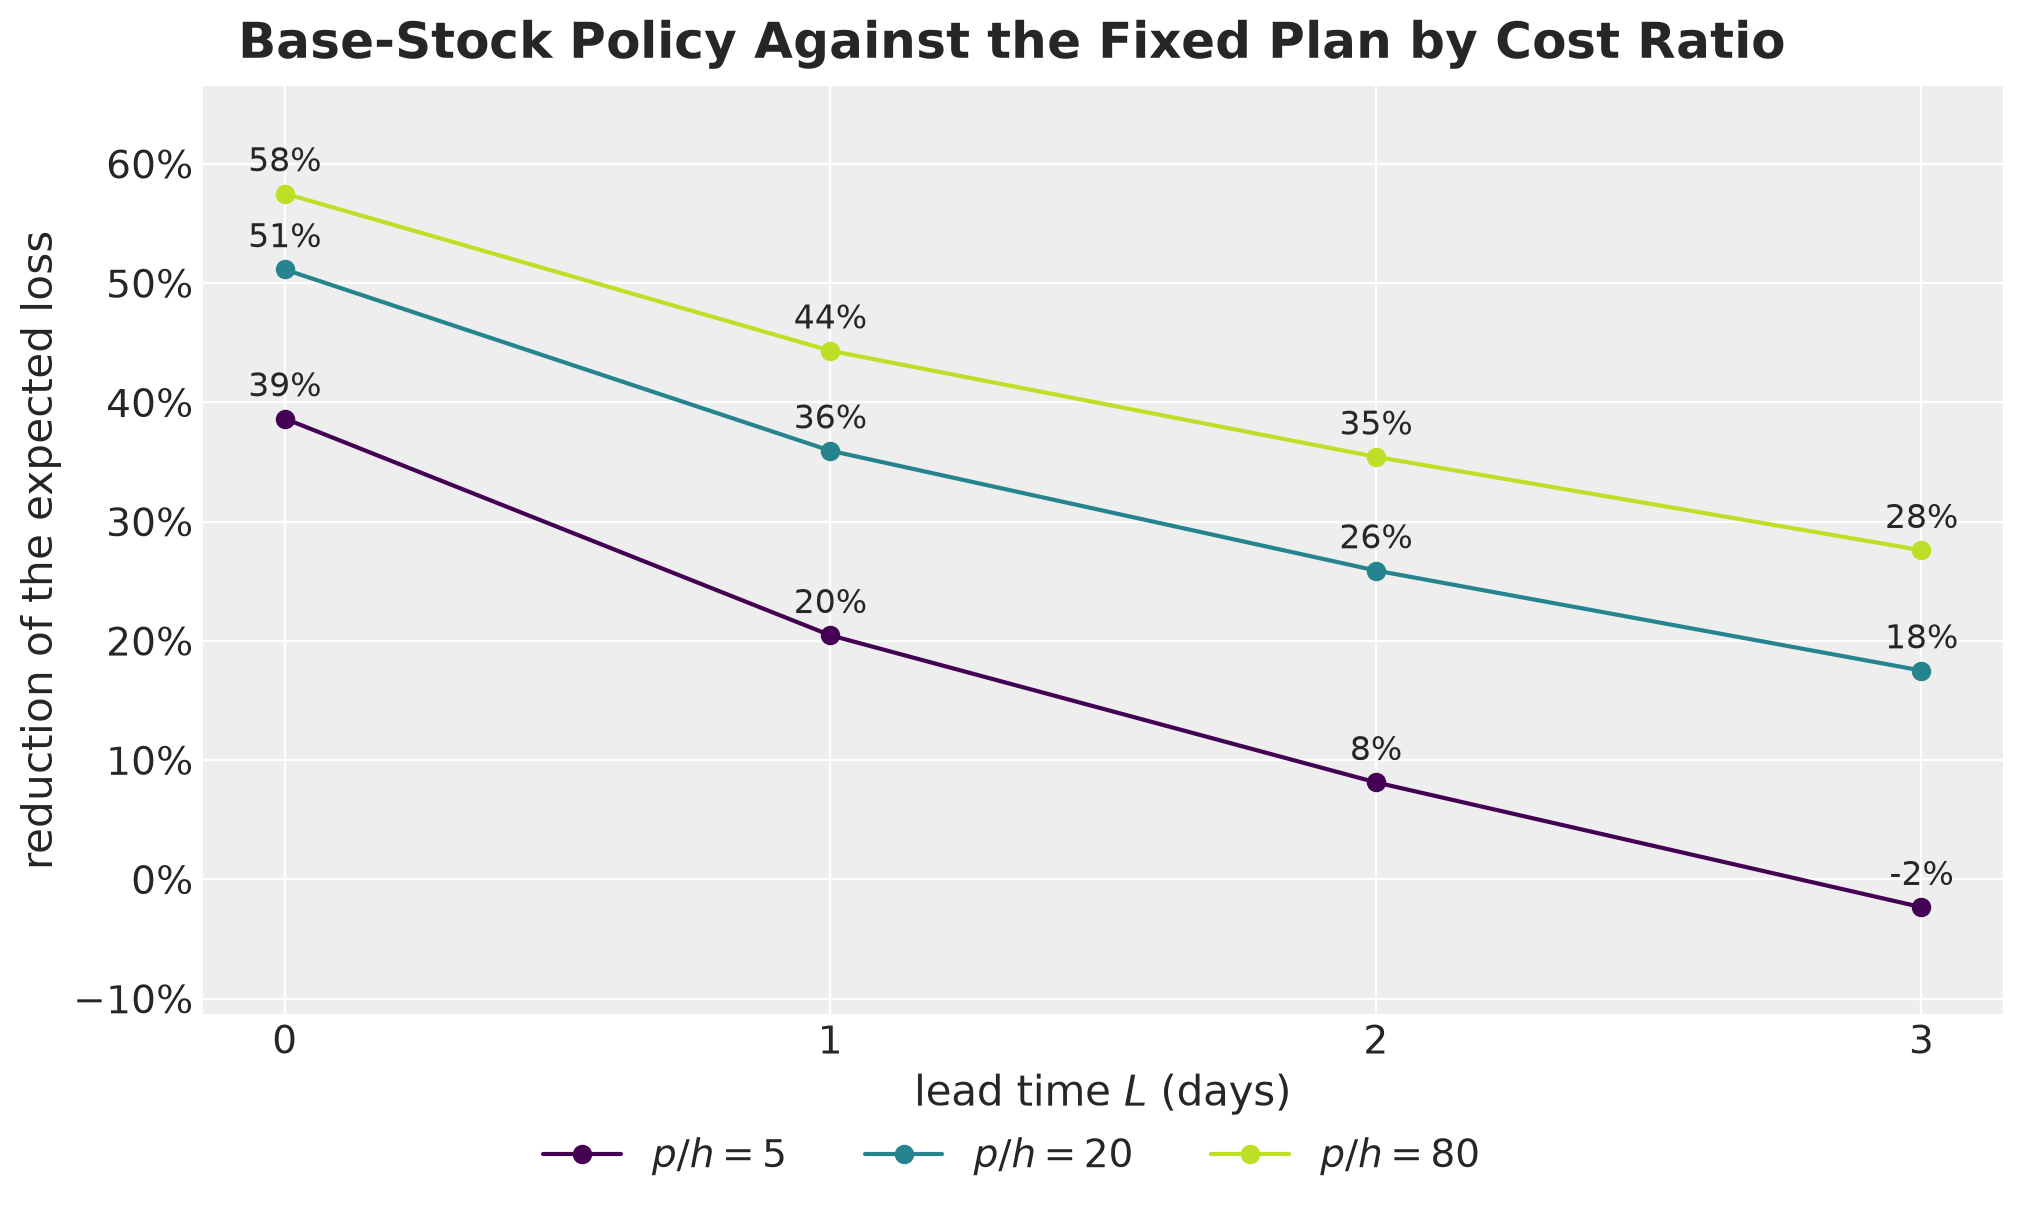

In [58]:
LOST_SALES_COSTS = [0.5, 2.0, 8.0]
rows = []

for lost_sales_cost in LOST_SALES_COSTS:
    config_sweep = config._replace(lost_sales_cost=lost_sales_cost)
    # the day-one forecast at the critical fractile of this cost ratio
    day_one_sweep = summarize_forecast(
        paths_day_one, setup.max_days, critical_fractile(config_sweep)
    )

    for lead_time in setup.lead_times:
        loss_plan = evaluate(
            train_fixed_plan(lead_time, config_sweep),
            ScenarioSet.FORECAST,
            lead_time,
            config_sweep,
        ).loss.mean()
        loss_base_stock = simulate_scenarios_jit(
            base_stock,
            no_offsets,
            scenarios_for(
                ScenarioSet.FORECAST,
                lead_time,
                ForecastSource.DAY_ONE,
                day_one=day_one_sweep,
            ),
            initial_state(lead_time),
            config_sweep,
            lead_time,
        ).loss.mean()
        rows.append(
            {
                "cost ratio": f"$p / h = {lost_sales_cost / config.holding_cost:g}$",
                "lead time": lead_time,
                "reduction": float(1 - loss_base_stock / loss_plan),
            }
        )

cost_sweep = pl.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 6))

for ((ratio,), frame), color in zip(
    cost_sweep.group_by("cost ratio", maintain_order=True),
    sequential_colors(len(LOST_SALES_COSTS)),
    strict=True,
):
    ax.plot(frame["lead time"], frame["reduction"], "o-", color=color, label=ratio)

    for lead_time, reduction in zip(
        frame["lead time"], frame["reduction"], strict=True
    ):
        ax.annotate(
            f"{reduction:.0%}",
            (lead_time, reduction),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=12,
        )

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(
    xlabel="lead time $L$ (days)",
    ylabel="reduction of the expected loss",
    xticks=setup.lead_times,
)
ax.margins(y=0.15)
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle(
    "Base-Stock Policy Against the Fixed Plan by Cost Ratio",
    fontsize=18,
    fontweight="bold",
);

The reduction is larger when a lost sale is more expensive: for $L = 0$ it is $39\%$ for the smallest ratio and $58\%$ for the largest. For every ratio it shrinks with the lead time, to between $-2\%$ and $28\%$ for $L = 3$.

So the answer to the first question holds for $p / h = 20$ and $80$, and its size depends on the costs. With a cheap lost sale and a lead time of $3$ days the untrained base-stock policy is no better than the fixed plan. We did not train the offsets for the other ratios.

### Tail Risk

Finally, we look at the tail of the loss. Recall that the CVaR is the mean of the worst $5\%$ of the scenario losses, here $150$ of $3{,}000$. In the first post the CVaR plan gave up some expected loss for a lower CVaR, and the tail weight $\lambda$ traced a **frontier**: the plans for which we cannot lower one of the two without raising the other.

We can train a policy with the same objective. To keep the comparison about the stock, we use the forecast of day one for both. We train the fixed plan and the offsets of the day-one base-stock rule for $6$ tail weights at $L = 2$ and score them on the forecast test set.

The base-stock rule with trained day-one offsets appears only in this section. We show `Base-stock (day-one forecast)`, which has no offsets, as a single point next to it.

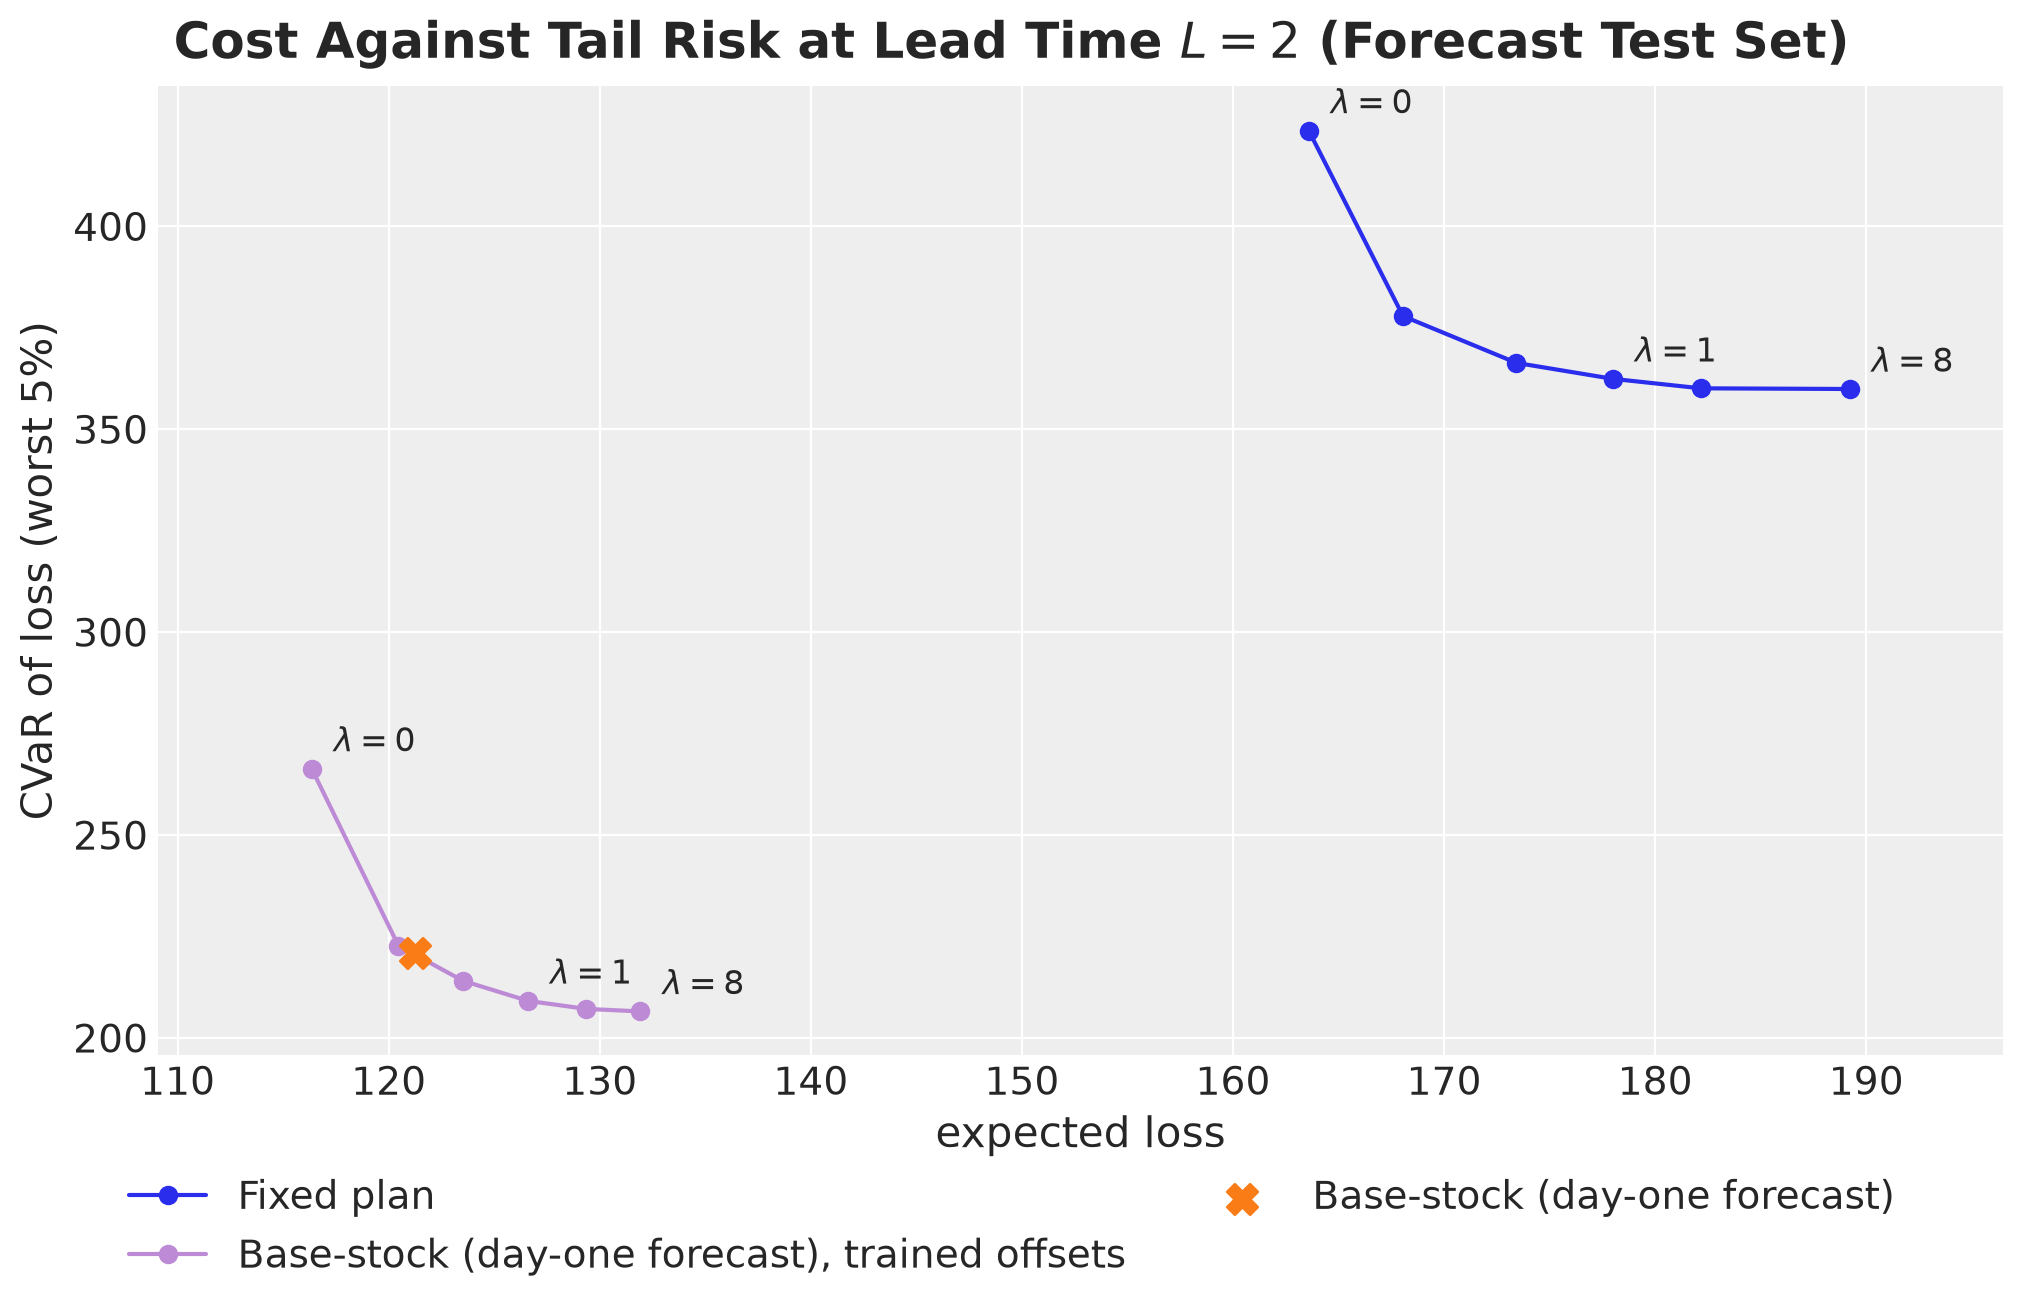

In [59]:
TAIL_WEIGHTS = [0.0, 0.25, 0.5, 1.0, 2.0, 8.0]
DAY_ONE_TRAINED = "Base-stock (day-one forecast), trained offsets"
# the color and the training function of each frontier
FRONTIER_POLICIES = {
    str(PolicyName.FIXED_PLAN): (
        POLICY_COLORS[PolicyName.FIXED_PLAN],
        lambda tail_weight: train_fixed_plan(LEAD_TIME_DETAIL, config, tail_weight),
    ),
    DAY_ONE_TRAINED: (
        "C8",
        lambda tail_weight: train_base_stock(
            LEAD_TIME_DETAIL, config, ForecastSource.DAY_ONE, tail_weight
        ),
    ),
}
frontier = pl.DataFrame(
    [
        {
            "policy": name,
            "tail weight": tail_weight,
            **summarize(
                evaluate(
                    train_policy(tail_weight), ScenarioSet.FORECAST, LEAD_TIME_DETAIL
                ),
                LEAD_TIME_DETAIL,
            ),
        }
        for name, (_, train_policy) in FRONTIER_POLICIES.items()
        for tail_weight in TAIL_WEIGHTS
    ]
)

fig, ax = plt.subplots(figsize=(10, 6.5))

for (name,), frame in frontier.group_by("policy", maintain_order=True):
    ax.plot(
        frame[Metric.EXPECTED_LOSS],
        frame[Metric.CVAR],
        "o-",
        color=FRONTIER_POLICIES[name][0],
        label=name,
    )

    for row in frame.filter(pl.col("tail weight").is_in([0.0, 1.0, 8.0])).iter_rows(
        named=True
    ):
        ax.annotate(
            rf"$\lambda={row['tail weight']:g}$",
            (row[Metric.EXPECTED_LOSS], row[Metric.CVAR]),
            textcoords="offset points",
            xytext=(8, 6),
            fontsize=12,
        )

# the base-stock rule with the day-one levels and no offsets
day_one_scores = summarize(
    simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, PolicyName.DAY_ONE],
    LEAD_TIME_DETAIL,
)
ax.scatter(
    day_one_scores[Metric.EXPECTED_LOSS],
    day_one_scores[Metric.CVAR],
    marker="X",
    s=120,
    color=POLICY_COLORS[PolicyName.DAY_ONE],
    label=PolicyName.DAY_ONE,
    zorder=3,
)
ax.set(xlabel=Metric.EXPECTED_LOSS, ylabel=Metric.CVAR)
ax.margins(x=0.1)
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    f"Cost Against Tail Risk at Lead Time $L = {LEAD_TIME_DETAIL}$ "
    f"({ScenarioSet.FORECAST.title()})",
    fontsize=18,
    fontweight="bold",
);

Let's compare the two frontiers.

- **Fixed plan.** With $\lambda = 0$ the expected loss is about $164$ and the CVaR about $424$. With $\lambda = 8$ they are about $189$ and $360$. Most of the reduction of the CVaR comes with the first tail weights, as in the first post.
- **Base-stock (day-one forecast), trained offsets.** The frontier has the same shape. With $\lambda = 0$ the two values are about $116$ and $266$, and with $\lambda = 8$ about $132$ and $207$.
- **Base-stock (day-one forecast).** Without offsets the rule has an expected loss of about $121$ and a CVaR of about $221$, close to the trained frontier at $\lambda = 0.25$. Its newsvendor levels are higher than the trained ones, which protects the tail.

The whole frontier of the base-stock rule lies below and to the left of the frontier of the fixed plan. Trained for the expected loss alone, the base-stock rule has a CVaR of about $266$, and the lowest CVaR of the fixed plan over the $6$ tail weights is about $360$.

This is what we expect. A fixed plan loses the most when the demand moves away from the plan, and the base-stock policy changes its orders when that happens.

## Conclusion

### Key Findings

The first four findings answer the three questions of the introduction.

- **Orders that depend on the stock.** With no lead time a base-stock policy at the newsvendor levels of the forecast of day one has about half of the expected loss of the fixed plan, $70$ against $144$ on the forecast test set. It needs a quantile of the scenarios and no optimizer. At $L = 2$ the fixed plan orders more units than any policy and runs out on more days ($12\%$ against $3\%$ to $6\%$), since its orders are the same in every scenario.
- **Lead time.** The gain is smaller for every extra day of lead time, because each order covers more demand that we have not seen. With the day-one levels it falls from $51\%$ to $18\%$ of the loss of the fixed plan on the forecast test set, and from $50\%$ to $4\%$ on the true process test set, which lies one standard deviation below the center of the forecast.
- **Weekly forecast.** The update after the first week lowers the expected loss by $0.7$ to $3.3$ on the forecast test set and by $1.2$ to $5.7$ on the true process test set, and the gain grows with the lead time. At $L = 2$ it comes from the scenarios with low expected demand, which is where the truth is.
- **Training.** Training the offsets through the simulator lowers the levels for $L \geq 1$ and the expected loss by $1$ to $9$ on the forecast test set and by $5$ to $24$ on the true process test set. The network adds $0.4$ to $3.0$ and $1.2$ to $3.1$. On day $15$ at $L = 2$, with the stock and the forecast held fixed, it raises its level when the recent demand is higher.
- **Tail risk.** For $L = 2$ the base-stock rule with trained day-one offsets has a lower CVaR than the fixed plan with any of our tail weights, also when we train it for the expected loss alone.
- **One model, one simulator and one trainer.** The same NumPyro model generates the data, is fitted with NUTS, simulates every scenario and weights the particles of the filter. One function trains the fixed plan, the offsets and the network, with the gradient from `jax.grad` through the `jax.lax.scan` of the simulator.

### Model Limitations

- **Observed demand.** We observe the demand of a day even when the shelf was empty. In practice the history is sales, which are censored on those days, see [Caron (2023)](https://kylejcaron.github.io/posts/censored_demand/2024-02-06-censored-demand.html) and the [censored demand example](https://juanitorduz.github.io/numpyro_forecast/docs/examples/censored_demand.html) of `numpyro_forecast`. This assumption also lets us compute the weekly forecast of every scenario before the training, because the forecast then does not depend on the orders. With censored sales the forecast depends on the policy, and the filter needs a censored likelihood.
- **One forecast origin.** Every scenario starts from the same history, the same initial stock and the same promotion calendar, so the offsets and the network are specific to these $15$ days. A policy for daily use has to be trained over many forecast origins.
- **One data set and one truth.** The results come from one synthetic series. The true process test set uses one set of true parameters. The comparisons on that set can change for a truth at another place of the posterior.
- **Well-specified forecast.** The forecasting model has the structure of the generator. With a misspecified forecast the scenarios, the levels and the filter can be wrong in the same direction, and we did not study that case.
- **Particle filter.** The filter never refreshes the parameter draws of its particles, and the updated levels come from $1{,}000$ paths per scenario. Their Monte Carlo error can add a small cost to the policies that read the weekly forecast.
- **One update.** We update the forecast once, on day $8$. An update on day $15$ would change only the last order, and a daily update would give the policies more recent forecasts.
- **Small samples for small differences.** The validation set has $1{,}000$ scenarios from $200$ posterior draws, and the error bars of the paired differences are for one training run of each policy. The CVaR is a mean of $150$ losses.
- **Costs and lead time.** The lead time is known and the same for every order, the costs are linear and the orders are continuous. Order minimums, fixed ordering costs and uncertain lead times change the simulator.

### Recommendations

1. **Start with a base-stock policy.** Order up to the $p / (p + h)$ quantile of the total demand of the next $L + 1$ days under the latest forecast, from the stock on hand plus the pipeline. It needs the scenarios of the forecast and a quantile.
2. **Update the forecast with the new demand.** One update after a week lowered the expected loss at every lead time, and more when the truth was below the center of the forecast. A particle filter makes the update cheap enough to run on every scenario.
3. **Train the offsets when there is a lead time.** Training the offsets through the simulator lowered the expected loss by about $4$ and $9$ for $L = 2$ and $L = 3$ on the forecast test set, and by more on the true process test set.
4. **Measure before adding a network.** Compare the candidates on the same held-out scenarios, look at the paired difference with its Monte Carlo error, and check how the gain depends on where the truth can lie inside the forecast.

## Next Steps

1. **Rolling horizon.** Solve the fixed plan again every day with the latest forecast and place only its first order, the practical version of the problem of the first post. It needs a solve for every scenario and every day, so it costs much more than a trained policy, and we left it out here.
2. **Censored demand.** Train the policies on sales, with a censored likelihood in the forecasting model and in the weight step of the filter. The forecast then depends on the orders, so the filter has to run inside the simulator.
3. **Many forecast origins.** Train one policy on the scenarios of the forecast origins of a rolling backtest, with the forecast of each origin among its features, so that it can be used every day.
4. **Many products.** Share a capacity between the products of a store, and let the policy return the orders of all the products.

## References

- Orduz, J. (2026). [From Forecasts to Decisions: Inventory Planning with Probabilistic Programming](https://juanitorduz.github.io/forecast_to_decision/). Personal blog.
- Orduz, J. (2026). [From Forecasts to Decisions: Cannibalization and Shared Capacity](https://juanitorduz.github.io/forecast_to_decision_cannibalization/). Personal blog.
- Alvo, M., Russo, D., Kanoria, Y. and Lee, M. (2023). [Deep Reinforcement Learning for Inventory Networks: Toward Reliable Policy Optimization](https://arxiv.org/abs/2306.11246). arXiv:2306.11246.
- Zipkin, P. (2008). [Old and New Methods for Lost-Sales Inventory Systems](https://doi.org/10.1287/opre.1070.0471). *Operations Research*, 56(5), 1256-1263.
- Bijvank, M. and Vis, I. F. A. (2011). [Lost-sales inventory theory: A review](https://doi.org/10.1016/j.ejor.2011.02.004). *European Journal of Operational Research*, 215(1), 1-13.
- Huh, W. T., Janakiraman, G., Muckstadt, J. A. and Rusmevichientong, P. (2009). [Asymptotic Optimality of Order-Up-To Policies in Lost Sales Inventory Systems](https://doi.org/10.1287/mnsc.1080.0945). *Management Science*, 55(3), 404-420.
- Goldberg, D. A., Katz-Rogozhnikov, D. A., Lu, Y., Sharma, M. and Squillante, M. S. (2016). [Asymptotic Optimality of Constant-Order Policies for Lost Sales Inventory Models with Large Lead Times](https://doi.org/10.1287/moor.2015.0760). *Mathematics of Operations Research*.
- Gijsbrechts, J., Boute, R. N., Van Mieghem, J. A. and Zhang, D. J. (2022). [Can Deep Reinforcement Learning Improve Inventory Management? Performance on Lost Sales, Dual-Sourcing, and Multi-Echelon Problems](https://doi.org/10.1287/msom.2021.1064). *Manufacturing & Service Operations Management*, 24(3), 1349-1368.
- Doucet, A. and Johansen, A. M. (2011). [A Tutorial on Particle Filtering and Smoothing: Fifteen Years Later](https://www.stats.ox.ac.uk/~doucet/doucet_johansen_tutorialPF2011.pdf). In *The Oxford Handbook of Nonlinear Filtering*. Oxford University Press.
- Szabłowski, B. (2026). [One Global Model, Many Behaviors: Stockout-Aware Feature Engineering and Dynamic Scaling for Multi-Horizon Retail Demand Forecasting with a Cost-Aware Ordering Policy (VN2 Winner Report)](https://arxiv.org/abs/2601.18919). arXiv:2601.18919.
- Caron, K. (2023). [Modeling Anything With First Principles: Demand under extreme stockouts](https://kylejcaron.github.io/posts/censored_demand/2024-02-06-censored-demand.html). Personal blog.
- Orduz, J. [NumPyro Forecast documentation](https://juanitorduz.github.io/numpyro_forecast/).
- DeepMind. [Optax documentation](https://optax.readthedocs.io/).
- Flax team. [Flax NNX basics](https://flax.readthedocs.io/en/latest/nnx_basics.html).